
# DATA3001 — Final Report: Part 1
## Data Audit and Forecast Sample Construction

**Research focus:** Motion characteristics and 24-hour drifter forecast errors in the Gulf Stream.

**Study region:** 80°W–60°W, 30°N–45°N  
**Study period:** July–September, 2007–2022  
**History window:** 24 hours  
**Forecast horizon:** 24 hours

This notebook establishes the data-processing pipeline for the final modelling report. Previous exploratory analyses are used only as references; all final results will be based on a consistent and reproducible dataset.


In [3]:

from pathlib import Path
import pandas as pd
import numpy as np

# Project paths
DATA_DIR = Path("../data/processed")

# Final study configuration
REGION = {
    "west": -80.0,
    "east": -60.0,
    "south": 30.0,
    "north": 45.0
}

START_YEAR = 2007
END_YEAR = 2022
STUDY_MONTHS = [7, 8, 9]

HISTORY_HOURS = 24
FORECAST_HOURS = 24

# Inspect available processed files
files = sorted(DATA_DIR.glob("*"))

inventory = []

for file in files:
    if file.is_file():
        inventory.append({
            "filename": file.name,
            "format": file.suffix,
            "size_MB": round(
                file.stat().st_size / (1024 ** 2), 2
            )
        })

inventory_df = pd.DataFrame(inventory)

print("Data directory:", DATA_DIR.resolve())
print("Number of files:", len(inventory_df))

display(inventory_df)


Data directory: /Users/tangzijin/Desktop/DATA3001/Data3001-group-project/data/processed
Number of files: 9


,filename,format,size_MB
0,gb_validation_predictions.parquet,.parquet,1.44
1,gulf_stream_in_region.npy,.npy,188.08
2,gulf_stream_q3_2007_2010.parquet,.parquet,11.10
3,gulf_stream_q3_2011_2014.parquet,.parquet,11.27
4,gulf_stream_q3_2015_2018.parquet,.parquet,13.07
5,gulf_stream_q3_2019_2022.parquet,.parquet,19.25
6,gulf_stream_trajectories.parquet,.parquet,448.16
7,modelling_dataset.parquet,.parquet,76.57
8,modelling_dataset_split.parquet,.parquet,76.58



## 1.2 Dataset Structure and Coverage

Inspect the available trajectory and seasonal datasets to identify their schemas, temporal coverage, geographic extent, and unique drifter counts before constructing the final modelling cohort.


In [4]:

import pyarrow.parquet as pq

datasets = [
    "gulf_stream_trajectories.parquet",
    "gulf_stream_q3_2007_2010.parquet",
    "gulf_stream_q3_2011_2014.parquet",
    "gulf_stream_q3_2015_2018.parquet",
    "gulf_stream_q3_2019_2022.parquet"
]

for filename in datasets:
    path = DATA_DIR / filename

    print(f"\n{'=' * 65}")
    print(filename)
    print(f"{'=' * 65}")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    pf = pq.ParquetFile(path)

    print("Rows:", pf.metadata.num_rows)
    print("Row groups:", pf.metadata.num_row_groups)
    print("\nSchema:")
    print(pf.schema_arrow)



gulf_stream_trajectories.parquet
Rows: 20216717
Row groups: 20

Schema:
trajectory_id: int64
time: timestamp[ns]
lon: double
lat: double
ve: float
vn: float
sst: float
drogue_status: bool
in_region: bool
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1098

gulf_stream_q3_2007_2010.parquet
Rows: 616023
Row groups: 1

Schema:
trajectory_id: int64
time: timestamp[ns]
lon: double
lat: double
ve: float
vn: float
sst: float
drogue_status: bool
in_region: bool
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1098

gulf_stream_q3_2011_2014.parquet
Rows: 640974
Row groups: 1

Schema:
trajectory_id: int64
time: timestamp[ns]
lon: double
lat: double
ve: float
vn: float
sst: float
drogue_status: bool
in_region: bool
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1098

gulf_stream_q3_2015_2018.parquet
Rows: 587026
Row groups: 1

Schema:
trajector

In [5]:

import pandas as pd
import numpy as np

# Load complete trajectories
df = pd.read_parquet(
    DATA_DIR / "gulf_stream_trajectories.parquet",
    columns=[
        "trajectory_id", "time", "lon", "lat",
        "ve", "vn", "sst", "drogue_status"
    ]
)

df = df.sort_values(
    ["trajectory_id", "time"]
).reset_index(drop=True)

# Select eligible forecast origins
origin_mask = (
    df["time"].dt.year.between(START_YEAR, END_YEAR)
    & df["time"].dt.month.isin(STUDY_MONTHS)
    & df["lon"].between(REGION["west"], REGION["east"])
    & df["lat"].between(REGION["south"], REGION["north"])
)

origins = df.loc[origin_mask].copy()

print(f"Eligible forecast origins: {len(origins):,}")
print(
    "Unique drifters:",
    origins["trajectory_id"].nunique()
)


Eligible forecast origins: 632,770
Unique drifters: 519



## 1.4 Forecast Sample Construction

Construct 24-hour historical input windows and match the observed position exactly 24 hours after each forecast origin.

Each valid sample contains 25 consecutive hourly input observations from t−24h to t, and one future target at t+24h. All models will use the same valid forecast origins.


In [6]:
# Use trajectory ID and timestamp for exact matching.
# The complete trajectory dataset is retained as the source.

history_hours = np.arange(-HISTORY_HOURS, 1)

# Build the required historical timestamps for each origin
origin_base = origins[
    ["trajectory_id", "time", "lon", "lat", "ve", "vn"]
].copy()

origin_base = origin_base.rename(columns={
    "lon": "lon_t",
    "lat": "lat_t",
    "ve": "ve_t",
    "vn": "vn_t"
})

# Assign a unique sample ID
origin_base = origin_base.reset_index(drop=True)
origin_base["sample_id"] = np.arange(len(origin_base))

# Create 25 historical timestamps per origin
history_index = pd.DataFrame({
    "sample_id": np.repeat(
        origin_base["sample_id"].to_numpy(),
        len(history_hours)
    ),
    "trajectory_id": np.repeat(
        origin_base["trajectory_id"].to_numpy(),
        len(history_hours)
    ),
    "time": np.repeat(
        origin_base["time"].to_numpy(),
        len(history_hours)
    ) + np.tile(
        history_hours, len(origin_base)
    ).astype("timedelta64[h]"),
    "lag": np.tile(
        history_hours, len(origin_base)
    )
})

# Match historical observations
history = history_index.merge(
    df[["trajectory_id", "time", "lon", "lat", "ve", "vn"]],
    on=["trajectory_id", "time"],
    how="left",
    validate="many_to_one"
)

# A complete input window requires 25 valid observations
valid_history = (
    history[["lon", "lat", "ve", "vn"]]
    .notna()
    .all(axis=1)
    .groupby(history["sample_id"])
    .sum()
    .eq(HISTORY_HOURS + 1)
)

# Match the exact 24-hour future target
target_index = origin_base[
    ["sample_id", "trajectory_id", "time"]
].copy()

target_index["time"] += pd.Timedelta(
    hours=FORECAST_HOURS
)

targets = target_index.merge(
    df[["trajectory_id", "time", "lon", "lat"]],
    on=["trajectory_id", "time"],
    how="left",
    validate="many_to_one"
)

targets = targets.rename(columns={
    "lon": "lon_target",
    "lat": "lat_target"
})

valid_target = targets[
    ["lon_target", "lat_target"]
].notna().all(axis=1)

# Final eligible sample IDs
valid_ids = origin_base.loc[
    valid_history.reindex(
        origin_base["sample_id"],
        fill_value=False
    ).to_numpy() & valid_target.to_numpy(),
    "sample_id"
]

# Retain only valid samples
samples = origin_base[
    origin_base["sample_id"].isin(valid_ids)
].merge(
    targets[
        ["sample_id", "lon_target", "lat_target"]
    ],
    on="sample_id",
    how="left",
    validate="one_to_one"
)

history = history[
    history["sample_id"].isin(valid_ids)
].copy()

print(f"Candidate origins: {len(origin_base):,}")
print(f"Valid forecast samples: {len(samples):,}")
print(
    "Unique drifters:",
    samples["trajectory_id"].nunique()
)
print(
    "Retained percentage:",
    f"{100 * len(samples) / len(origin_base):.2f}%"
)
print(f"Historical observations: {len(history):,}")


Candidate origins: 632,770
Valid forecast samples: 626,679
Unique drifters: 517
Retained percentage: 99.04%
Historical observations: 15,666,975


In [7]:

# Step 1.5 — Motion feature engineering

H = HISTORY_HOURS
DT = 3600.0
LOW_SPEED = 0.05

# Ensure each sample is ordered chronologically
history = history.sort_values(
    ["sample_id", "lag"]
)

samples = samples.sort_values(
    "sample_id"
).reset_index(drop=True)

n = len(samples)
window = H + 1

# Reshape into (samples, 25)
ve = history["ve"].to_numpy().reshape(n, window)
vn = history["vn"].to_numpy().reshape(n, window)
lon = history["lon"].to_numpy().reshape(n, window)
lat = history["lat"].to_numpy().reshape(n, window)

# 1. Speed
speed = np.hypot(ve, vn)

# 2. Acceleration
dve = np.diff(ve, axis=1)
dvn = np.diff(vn, axis=1)

acceleration = np.hypot(dve, dvn) / DT
speed_change = np.abs(
    np.diff(speed, axis=1)
) / DT

# 3. Heading and turning
heading = np.arctan2(vn, ve)

delta_heading = np.arctan2(
    np.sin(np.diff(heading, axis=1)),
    np.cos(np.diff(heading, axis=1))
)

turning = np.degrees(
    np.abs(delta_heading)
)

# Turning is undefined when either velocity is too small
valid_turn = (
    (speed[:, 1:] >= LOW_SPEED)
    & (speed[:, :-1] >= LOW_SPEED)
)

turning = np.where(
    valid_turn, turning, np.nan
)

# Avoid warnings for all-NaN turning windows
turn_count = valid_turn.sum(axis=1)
turn_sum = np.nansum(turning, axis=1)

mean_turning = np.divide(
    turn_sum,
    turn_count,
    out=np.full(n, np.nan),
    where=turn_count > 0
)

max_turning = np.max(
    np.where(np.isnan(turning), -np.inf, turning),
    axis=1
)
max_turning[turn_count == 0] = np.nan

# 4. Velocity trend (linear slope over 24 hours)
hours = np.arange(-H, 1, dtype=float)
centered_hours = hours - hours.mean()
denom = np.sum(centered_hours ** 2)

ve_trend = (
    (ve * centered_hours).sum(axis=1) / denom
)
vn_trend = (
    (vn * centered_hours).sum(axis=1) / denom
)

# 5. Assemble features
features = pd.DataFrame({
    "sample_id": samples["sample_id"].to_numpy(),

    # Current-state features
    "lon_t": samples["lon_t"].to_numpy(),
    "lat_t": samples["lat_t"].to_numpy(),
    "ve_t": samples["ve_t"].to_numpy(),
    "vn_t": samples["vn_t"].to_numpy(),
    "speed_t": speed[:, -1],
    "heading_sin_t": np.sin(heading[:, -1]),
    "heading_cos_t": np.cos(heading[:, -1]),

    # Historical speed
    "mean_speed": speed.mean(axis=1),
    "sd_speed": speed.std(axis=1),

    # Historical velocity
    "mean_ve": ve.mean(axis=1),
    "mean_vn": vn.mean(axis=1),
    "sd_ve": ve.std(axis=1),
    "sd_vn": vn.std(axis=1),

    # Acceleration
    "mean_acceleration": acceleration.mean(axis=1),
    "max_acceleration": acceleration.max(axis=1),
    "mean_speed_change": speed_change.mean(axis=1),

    # Turning
    "mean_turning": mean_turning,
    "max_turning": max_turning,
    "valid_turn_fraction": turn_count / H,

    # Velocity trends
    "ve_trend": ve_trend,
    "vn_trend": vn_trend,

    # Historical displacement (degrees)
    "history_dlon": lon[:, -1] - lon[:, 0],
    "history_dlat": lat[:, -1] - lat[:, 0]
})

# Cyclic time features
time = pd.to_datetime(samples["time"])

day_of_year = time.dt.dayofyear.to_numpy()
year_length = np.where(
    time.dt.is_leap_year.to_numpy(), 366, 365
)

phase = 2 * np.pi * (day_of_year - 1) / year_length

features["day_sin"] = np.sin(phase)
features["day_cos"] = np.cos(phase)

# Attach features to modelling samples
modelling = samples.merge(
    features,
    on="sample_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_feature")
)

print("Modelling samples:", len(modelling))
print("Feature columns:", len(features.columns) - 1)

print("\nMotion descriptors:")
display(
    modelling[
        ["mean_speed", "mean_acceleration",
         "mean_turning", "valid_turn_fraction"]
    ].describe().round(5)
)


Modelling samples: 626679
Feature columns: 25

Motion descriptors:


,mean_speed,mean_acceleration,mean_turning,valid_turn_fraction
count,626679.00000,626679.00000,626208.00000,626679.00000
mean,0.40772,0.00002,11.56701,0.96555
std,0.31828,0.00001,7.83732,0.08301
min,0.00102,0.00000,0.01747,0.00000
25%,0.21122,0.00001,5.41793,1.00000
50%,0.30842,0.00002,9.42297,1.00000
75%,0.48515,0.00003,16.27019,1.00000
max,2.60074,0.00021,90.17885,1.00000


In [8]:
from sklearn.model_selection import GroupShuffleSplit

# Step 1.6 — Targets and grouped train/validation/test split

EARTH_RADIUS = 6_371_000.0
HORIZON_SECONDS = FORECAST_HOURS * 3600

# Actual displacement in local east/north coordinates
lat0 = np.radians(modelling["lat_t"].to_numpy())
lon0 = np.radians(modelling["lon_t"].to_numpy())

lat1 = np.radians(modelling["lat_target"].to_numpy())
lon1 = np.radians(modelling["lon_target"].to_numpy())

# Wrap longitude difference to [-pi, pi]
dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi

modelling["dx_true"] = (
    EARTH_RADIUS * np.cos(lat0) * dlon
)
modelling["dy_true"] = (
    EARTH_RADIUS * (lat1 - lat0)
)

# Constant-velocity displacement
modelling["dx_cv"] = (
    modelling["ve_t"] * HORIZON_SECONDS
)
modelling["dy_cv"] = (
    modelling["vn_t"] * HORIZON_SECONDS
)

# Residual targets for machine learning
modelling["dx_residual"] = (
    modelling["dx_true"] - modelling["dx_cv"]
)
modelling["dy_residual"] = (
    modelling["dy_true"] - modelling["dy_cv"]
)

# Split by unique drifter ID
groups = modelling["trajectory_id"]

split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

trainval_idx, test_idx = next(
    split_1.split(modelling, groups=groups)
)

trainval = modelling.iloc[trainval_idx]

# 15% validation from total:
# 0.15 / 0.85 of the remaining trainval group
split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=43
)

train_idx_local, val_idx_local = next(
    split_2.split(
        trainval,
        groups=trainval["trajectory_id"]
    )
)

train_idx = trainval_idx[train_idx_local]
val_idx = trainval_idx[val_idx_local]

modelling["split"] = ""

modelling.loc[train_idx, "split"] = "train"
modelling.loc[val_idx, "split"] = "validation"
modelling.loc[test_idx, "split"] = "test"

# Save the new final modelling dataset
output_path = (
    DATA_DIR / "modelling_dataset_final.parquet"
)

modelling.to_parquet(
    output_path,
    index=False
)

split_summary = (
    modelling.groupby("split")
    .agg(
        samples=("sample_id", "count"),
        drifters=("trajectory_id", "nunique")
    )
)

split_summary["sample_pct"] = (
    100 * split_summary["samples"] / len(modelling)
)

print("Saved:", output_path)
display(split_summary.round(2))


Saved: ../data/processed/modelling_dataset_final.parquet


,samples,drifters,sample_pct
split,,,
test,82546,78,13.17
train,455662,361,72.71
validation,88471,78,14.12


In [9]:
import numpy as np
import pandas as pd

EARTH_RADIUS = 6_371_000.0

def displacement_to_position(lon, lat, dx, dy):
    """
    Convert local east/north displacement (metres)
    into a predicted geographic position using
    spherical forward geodesic approximation.
    """
    lon1 = np.radians(np.asarray(lon))
    lat1 = np.radians(np.asarray(lat))

    distance = np.hypot(dx, dy)
    bearing = np.arctan2(dx, dy)

    angular_distance = distance / EARTH_RADIUS

    lat2 = np.arcsin(
        np.sin(lat1) * np.cos(angular_distance)
        + np.cos(lat1) * np.sin(angular_distance)
        * np.cos(bearing)
    )

    lon2 = lon1 + np.arctan2(
        np.sin(bearing) * np.sin(angular_distance)
        * np.cos(lat1),
        np.cos(angular_distance)
        - np.sin(lat1) * np.sin(lat2)
    )

    lon2 = (lon2 + np.pi) % (2 * np.pi) - np.pi

    return np.degrees(lon2), np.degrees(lat2)


def great_circle_error(lon_pred, lat_pred, lon_true, lat_true):
    """
    Great-circle distance in kilometres.
    """
    lon1 = np.radians(np.asarray(lon_pred))
    lat1 = np.radians(np.asarray(lat_pred))
    lon2 = np.radians(np.asarray(lon_true))
    lat2 = np.radians(np.asarray(lat_true))

    dlon = (lon2 - lon1 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return (
        2 * EARTH_RADIUS
        * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        / 1000
    )


# Constant Velocity predictions
modelling["lon_cv"], modelling["lat_cv"] = (
    displacement_to_position(
        modelling["lon_t"],
        modelling["lat_t"],
        modelling["dx_cv"],
        modelling["dy_cv"]
    )
)

modelling["error_cv_km"] = great_circle_error(
    modelling["lon_cv"],
    modelling["lat_cv"],
    modelling["lon_target"],
    modelling["lat_target"]
)

# Evaluate on validation data only
cv_val = modelling.loc[
    modelling["split"] == "validation",
    "error_cv_km"
]

cv_results = pd.DataFrame({
    "Metric": ["Mean", "Median", "P90", "RMSE"],
    "Error (km)": [
        cv_val.mean(),
        cv_val.median(),
        cv_val.quantile(0.90),
        np.sqrt(np.mean(cv_val ** 2))
    ]
})

display(cv_results.round(3))


,Metric,Error (km)
0,Mean,18.883
1,Median,15.044
2,P90,36.273
3,RMSE,24.496


In [10]:
# Step 2.2 — Mean-flow Advection Baseline

GRID_SIZE = 1.0

train = modelling[
    modelling["split"] == "train"
].copy()

validation = modelling[
    modelling["split"] == "validation"
].copy()

# 1. Assign spatial grid cells
def assign_grid(df, grid_size=1.0):
    result = df.copy()

    result["grid_lon"] = (
        np.floor(result["lon_t"] / grid_size)
        * grid_size
    )

    result["grid_lat"] = (
        np.floor(result["lat_t"] / grid_size)
        * grid_size
    )

    return result


train_grid = assign_grid(train, GRID_SIZE)
val_grid = assign_grid(validation, GRID_SIZE)

# 2. Estimate mean velocity from training data only
mean_flow = (
    train_grid.groupby(["grid_lon", "grid_lat"])
    .agg(
        flow_ve=("ve_t", "mean"),
        flow_vn=("vn_t", "mean"),
        n_observations=("ve_t", "size")
    )
    .reset_index()
)

# 3. Global fallback for cells without training observations
global_ve = train["ve_t"].mean()
global_vn = train["vn_t"].mean()

# 4. Match validation origins to the estimated flow field
val_flow = val_grid.merge(
    mean_flow,
    on=["grid_lon", "grid_lat"],
    how="left",
    validate="many_to_one"
)

unseen_cells = val_flow["flow_ve"].isna().sum()

val_flow["flow_ve"] = (
    val_flow["flow_ve"].fillna(global_ve)
)

val_flow["flow_vn"] = (
    val_flow["flow_vn"].fillna(global_vn)
)

# 5. Predict displacement
val_flow["dx_flow"] = (
    val_flow["flow_ve"] * HORIZON_SECONDS
)

val_flow["dy_flow"] = (
    val_flow["flow_vn"] * HORIZON_SECONDS
)

val_flow["lon_flow"], val_flow["lat_flow"] = (
    displacement_to_position(
        val_flow["lon_t"],
        val_flow["lat_t"],
        val_flow["dx_flow"],
        val_flow["dy_flow"]
    )
)

# 6. Great-circle errors
val_flow["error_flow_km"] = great_circle_error(
    val_flow["lon_flow"],
    val_flow["lat_flow"],
    val_flow["lon_target"],
    val_flow["lat_target"]
)

# 7. Compare both physical baselines
baseline_results = pd.DataFrame({
    "Model": ["Constant Velocity", "Mean-flow Advection"],
    "Mean (km)": [
        validation["error_cv_km"].mean(),
        val_flow["error_flow_km"].mean()
    ],
    "Median (km)": [
        validation["error_cv_km"].median(),
        val_flow["error_flow_km"].median()
    ],
    "P90 (km)": [
        validation["error_cv_km"].quantile(0.9),
        val_flow["error_flow_km"].quantile(0.9)
    ],
    "RMSE (km)": [
        np.sqrt(np.mean(validation["error_cv_km"] ** 2)),
        np.sqrt(np.mean(val_flow["error_flow_km"] ** 2))
    ]
})

print("Mean-flow grid cells:", len(mean_flow))
print("Validation origins using fallback:", unseen_cells)

display(baseline_results.round(3))


Mean-flow grid cells: 224
Validation origins using fallback: 427


,Model,Mean (km),Median (km),P90 (km),RMSE (km)
0,Constant Velocity,18.883,15.044,36.273,24.496
1,Mean-flow Advection,29.073,22.663,58.993,37.753


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge

# Current-state features
current_features = [
    "lon_t", "lat_t",
    "ve_t", "vn_t",
    "speed_t",
    "heading_sin_t", "heading_cos_t",
    "day_sin", "day_cos"
]

# Additional historical features
history_features = [
    "mean_speed", "sd_speed",
    "mean_ve", "mean_vn",
    "sd_ve", "sd_vn",
    "mean_acceleration", "max_acceleration",
    "mean_speed_change",
    "mean_turning", "max_turning",
    "valid_turn_fraction",
    "ve_trend", "vn_trend",
    "history_dlon", "history_dlat"
]

feature_sets = {
    "Ridge Current": current_features,
    "Ridge History": current_features + history_features
}

train_mask = modelling["split"] == "train"
val_mask = modelling["split"] == "validation"

target_cols = ["dx_residual", "dy_residual"]

Y_train = modelling.loc[
    train_mask, target_cols
].to_numpy()

Y_val = modelling.loc[
    val_mask, target_cols
].to_numpy()

# Candidate regularisation strengths
alphas = [0.1, 1, 10, 100, 1000]

ridge_models = {}
ridge_predictions = {}
ridge_results = []

for model_name, cols in feature_sets.items():

    X_train = modelling.loc[train_mask, cols]
    X_val = modelling.loc[val_mask, cols]

    for alpha in alphas:

        pipeline = Pipeline([
            ("imputer", SimpleImputer(
                strategy="median",
                add_indicator=True
            )),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha))
        ])

        pipeline.fit(X_train, Y_train)

        residual_pred = pipeline.predict(X_val)

        val_data = modelling.loc[val_mask]

        dx_pred = (
            val_data["dx_cv"].to_numpy()
            + residual_pred[:, 0]
        )

        dy_pred = (
            val_data["dy_cv"].to_numpy()
            + residual_pred[:, 1]
        )

        lon_pred, lat_pred = displacement_to_position(
            val_data["lon_t"],
            val_data["lat_t"],
            dx_pred,
            dy_pred
        )

        errors = great_circle_error(
            lon_pred,
            lat_pred,
            val_data["lon_target"],
            val_data["lat_target"]
        )

        ridge_results.append({
            "Model": model_name,
            "Alpha": alpha,
            "Mean": np.mean(errors),
            "Median": np.median(errors),
            "P90": np.quantile(errors, 0.90),
            "RMSE": np.sqrt(np.mean(errors ** 2))
        })

        ridge_models[(model_name, alpha)] = pipeline
        ridge_predictions[(model_name, alpha)] = errors

ridge_results = pd.DataFrame(ridge_results)

display(
    ridge_results.sort_values(
        ["Model", "Median"]
    ).round(3)
)


,Model,Alpha,Mean,Median,P90,RMSE
4,Ridge Current,1000.0,16.756,13.239,32.508,21.537
3,Ridge Current,100.0,16.759,13.243,32.512,21.540
1,Ridge Current,1.0,16.759,13.243,32.514,21.540
0,Ridge Current,0.1,16.759,13.243,32.514,21.540
2,Ridge Current,10.0,16.759,13.243,32.514,21.540
6,Ridge History,1.0,14.271,10.483,28.383,19.553
5,Ridge History,0.1,14.271,10.483,28.383,19.553
7,Ridge History,10.0,14.271,10.484,28.378,19.553
8,Ridge History,100.0,14.270,10.485,28.367,19.552
9,Ridge History,1000.0,14.283,10.496,28.406,19.562



### Ridge Regression: Contribution of Historical Motion

Ridge regression was used to estimate corrections to the Constant Velocity forecast. Two feature configurations were compared: a current-state model and a history-enhanced model incorporating motion statistics from the preceding 24 hours.

The history-enhanced Ridge model achieved a validation median error of 10.483 km, compared with 13.239 km for the current-state model and 15.044 km for Constant Velocity. This corresponds to a 20.8% reduction relative to current-state Ridge and a 30.3% reduction relative to CV.

The improvement extended beyond the median: the 90th-percentile error decreased from 32.508 km to 28.383 km when historical features were included.

Performance was relatively insensitive to the regularisation strength across the tested values, suggesting that the observed historical-feature improvement was not driven by a narrow hyperparameter choice.

These findings provide preliminary evidence that recent motion history contains predictive information beyond the instantaneous position and velocity. Further analysis is required to identify which historical motion characteristics contribute most strongly to this improvement.


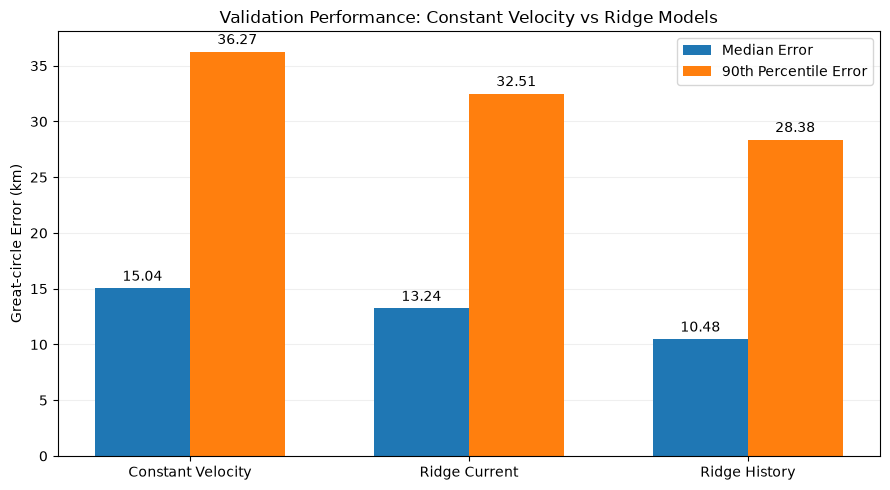

<Figure size 640x480 with 0 Axes>

In [13]:
import matplotlib.pyplot as plt
import numpy as np

model_names = [
    "Constant Velocity",
    "Ridge Current",
    "Ridge History"
]

median_errors = [15.044, 13.239, 10.483]
p90_errors = [36.273, 32.508, 28.383]

x = np.arange(len(model_names))
width = 0.34

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width / 2,
    median_errors,
    width,
    label="Median Error"
)

bars2 = ax.bar(
    x + width / 2,
    p90_errors,
    width,
    label="90th Percentile Error"
)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.set_ylabel("Great-circle Error (km)")
ax.set_title(
    "Validation Performance: Constant Velocity vs Ridge Models"
)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    "../image/report_ridge_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 3.2 Gradient Boosting Regression

Gradient Boosting was introduced to investigate whether nonlinear relationships between drifter motion characteristics and future displacement could improve forecasting performance beyond Ridge regression.

Two feature configurations were evaluated:

- **Current-only:** Geographic position, instantaneous velocity, speed, heading and seasonal features.
- **History-enhanced:** All current-state features plus summary statistics describing the preceding 24 hours of motion, including velocity variability, acceleration, turning and historical displacement.

Both configurations predict eastward and northward corrections to the Constant Velocity forecast. Three hyperparameter configurations are compared using the same drifter-level training and validation partitions as Ridge regression.

Models are selected using validation median great-circle error. The held-out test set is not used during model selection.


In [14]:
from pathlib import Path
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

# Step 3.2 — Gradient Boosting Regression

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

gb_configs = [
    {
        "max_iter": 150,
        "max_leaf_nodes": 15,
        "learning_rate": 0.08
    },
    {
        "max_iter": 200,
        "max_leaf_nodes": 31,
        "learning_rate": 0.06
    },
    {
        "max_iter": 250,
        "max_leaf_nodes": 31,
        "learning_rate": 0.08
    }
]

gb_feature_sets = {
    "GB Current": current_features,
    "GB History": current_features + history_features
}

gb_models = {}
gb_predictions = {}
gb_results = []

val_data = modelling.loc[val_mask]

for model_name, cols in gb_feature_sets.items():

    X_train = modelling.loc[train_mask, cols]
    X_val = modelling.loc[val_mask, cols]

    for config_id, config in enumerate(gb_configs):

        print(f"Training {model_name}, config {config_id}...")

        model = MultiOutputRegressor(
            HistGradientBoostingRegressor(
                **config,
                l2_regularization=1.0,
                min_samples_leaf=50,
                random_state=42
            )
        )

        model.fit(X_train, Y_train)

        residual_pred = model.predict(X_val)

        dx_pred = (
            val_data["dx_cv"].to_numpy()
            + residual_pred[:, 0]
        )

        dy_pred = (
            val_data["dy_cv"].to_numpy()
            + residual_pred[:, 1]
        )

        lon_pred, lat_pred = displacement_to_position(
            val_data["lon_t"],
            val_data["lat_t"],
            dx_pred,
            dy_pred
        )

        errors = great_circle_error(
            lon_pred,
            lat_pred,
            val_data["lon_target"],
            val_data["lat_target"]
        )

        gb_results.append({
            "Model": model_name,
            "Config": config_id,
            "Max Iter": config["max_iter"],
            "Leaf Nodes": config["max_leaf_nodes"],
            "Learning Rate": config["learning_rate"],
            "Mean": np.mean(errors),
            "Median": np.median(errors),
            "P90": np.quantile(errors, 0.90),
            "RMSE": np.sqrt(np.mean(errors ** 2))
        })

        gb_models[(model_name, config_id)] = model
        gb_predictions[(model_name, config_id)] = errors

        # Save fitted model
        model_filename = (
            model_name.lower().replace(" ", "_")
            + f"_config_{config_id}.joblib"
        )

        joblib.dump(
            model,
            MODEL_DIR / model_filename
        )

gb_results = pd.DataFrame(gb_results)

gb_results.to_csv(
    MODEL_DIR / "gb_validation_results.csv",
    index=False
)

display(
    gb_results.sort_values(
        ["Model", "Median"]
    ).round(3)
)


Training GB Current, config 0...
Training GB Current, config 1...
Training GB Current, config 2...
Training GB History, config 0...
Training GB History, config 1...
Training GB History, config 2...


,Model,Config,Max Iter,Leaf Nodes,Learning Rate,Mean,Median,P90,RMSE
2,GB Current,2,250,31,0.08,15.765,12.656,30.204,20.141
1,GB Current,1,200,31,0.06,15.750,12.659,30.160,20.075
0,GB Current,0,150,15,0.08,15.807,12.676,30.227,20.148
5,GB History,2,250,31,0.08,11.954,8.513,24.828,16.668
4,GB History,1,200,31,0.06,12.142,8.693,25.295,16.830
3,GB History,0,150,15,0.08,12.552,9.101,25.997,17.236


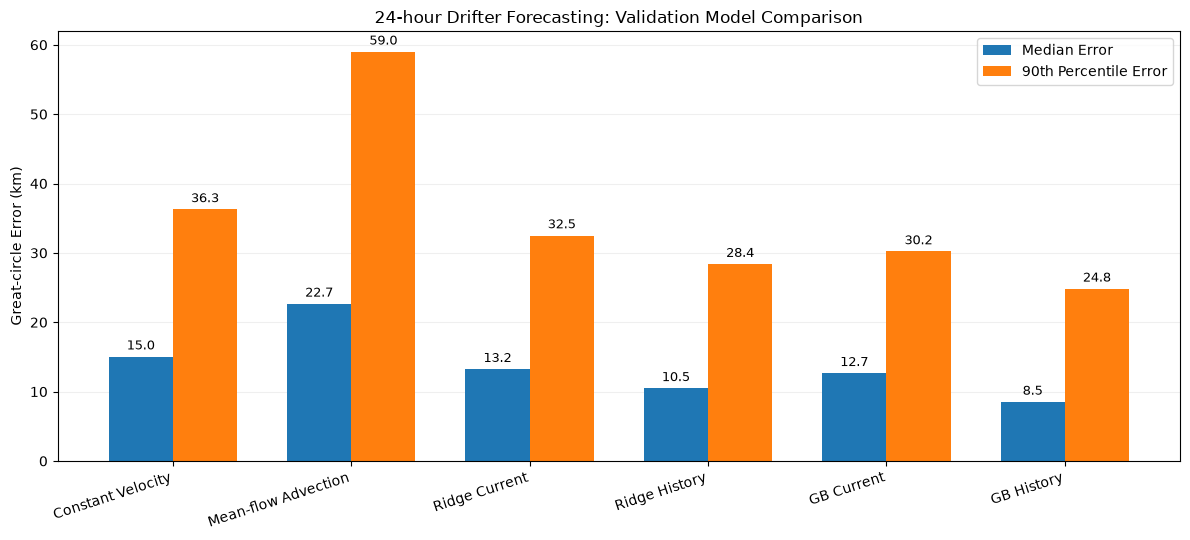

,Model,Mean,Median,P90,RMSE
0,Constant Velocity,18.883,15.044,36.273,24.496
1,Mean-flow Advection,29.073,22.663,58.993,37.753
2,Ridge Current,16.756,13.239,32.508,21.537
3,Ridge History,14.271,10.483,28.383,19.553
4,GB Current,15.765,12.656,30.204,20.141
5,GB History,11.954,8.513,24.828,16.668


In [15]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG_DIR = Path("../image")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Select the best configuration by validation median error
best_ridge = (
    ridge_results.loc[
        ridge_results.groupby("Model")["Median"].idxmin()
    ].copy()
)

best_gb = (
    gb_results.loc[
        gb_results.groupby("Model")["Median"].idxmin()
    ].copy()
)

# Baselines
baseline_plot = baseline_results.rename(columns={
    "Mean (km)": "Mean",
    "Median (km)": "Median",
    "P90 (km)": "P90",
    "RMSE (km)": "RMSE"
})[["Model", "Mean", "Median", "P90", "RMSE"]]

comparison = pd.concat([
    baseline_plot,
    best_ridge[["Model", "Mean", "Median", "P90", "RMSE"]],
    best_gb[["Model", "Mean", "Median", "P90", "RMSE"]]
], ignore_index=True)

model_order = [
    "Constant Velocity",
    "Mean-flow Advection",
    "Ridge Current",
    "Ridge History",
    "GB Current",
    "GB History"
]

comparison = (
    comparison.set_index("Model")
    .loc[model_order]
    .reset_index()
)

x = np.arange(len(comparison))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 5.5))

bars1 = ax.bar(
    x - width / 2,
    comparison["Median"],
    width,
    label="Median Error"
)

bars2 = ax.bar(
    x + width / 2,
    comparison["P90"],
    width,
    label="90th Percentile Error"
)

ax.bar_label(bars1, fmt="%.1f", padding=3, fontsize=9)
ax.bar_label(bars2, fmt="%.1f", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(comparison["Model"], rotation=18, ha="right")
ax.set_ylabel("Great-circle Error (km)")
ax.set_title("24-hour Drifter Forecasting: Validation Model Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "report_six_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(comparison.round(3))


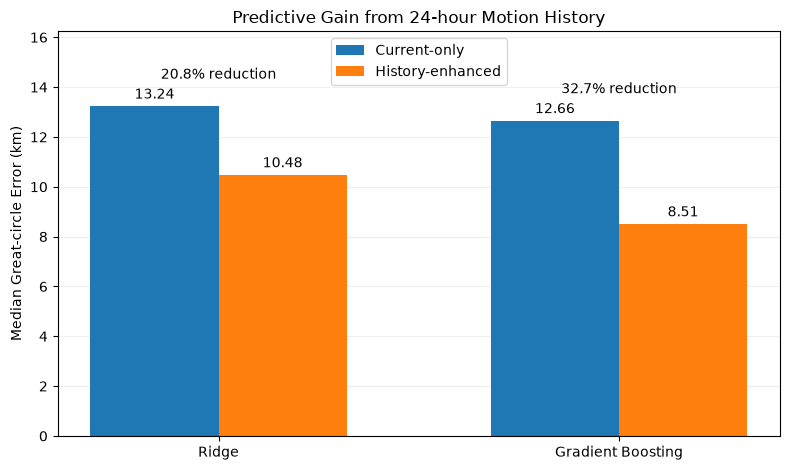

,Model,Current,History,Reduction (%)
0,Ridge,13.239,10.483,20.821
1,Gradient Boosting,12.656,8.513,32.734


In [16]:
history_gain = pd.DataFrame({
    "Model": ["Ridge", "Gradient Boosting"],
    "Current": [
        comparison.set_index("Model").loc["Ridge Current", "Median"],
        comparison.set_index("Model").loc["GB Current", "Median"]
    ],
    "History": [
        comparison.set_index("Model").loc["Ridge History", "Median"],
        comparison.set_index("Model").loc["GB History", "Median"]
    ]
})

history_gain["Reduction (%)"] = (
    100 * (history_gain["Current"] - history_gain["History"])
    / history_gain["Current"]
)

fig, ax = plt.subplots(figsize=(8, 4.8))

x = np.arange(len(history_gain))
width = 0.32

bars1 = ax.bar(
    x - width / 2,
    history_gain["Current"],
    width,
    label="Current-only"
)

bars2 = ax.bar(
    x + width / 2,
    history_gain["History"],
    width,
    label="History-enhanced"
)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

for i, gain in enumerate(history_gain["Reduction (%)"]):
    ax.text(
        i,
        max(history_gain.loc[i, "Current"],
            history_gain.loc[i, "History"]) + 1.1,
        f"{gain:.1f}% reduction",
        ha="center",
        fontsize=10
    )

ax.set_xticks(x)
ax.set_xticklabels(history_gain["Model"])
ax.set_ylim(0, history_gain["Current"].max() + 3)
ax.set_ylabel("Median Great-circle Error (km)")
ax.set_title("Predictive Gain from 24-hour Motion History")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "report_history_gain.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(history_gain.round(3))



## 4. Refinement of the Mean-flow Advection Baseline

The validation results demonstrate that incorporating historical motion information substantially improves 24-hour drifter forecasting. History-enhanced Ridge and Gradient Boosting reduced median prediction errors by 20.8% and 32.7%, respectively, compared with their current-only counterparts.

Before proceeding to final evaluation, the physical baselines require further consideration. While Constant Velocity achieved a median validation error of 15.044 km, the initial empirical Mean-flow Advection baseline produced a substantially higher error of 22.663 km.

The initial Mean-flow approach assumed that the average velocity of the origin grid cell remained constant throughout the entire 24-hour forecast. This simplification does not account for spatial changes in the estimated flow field as the drifter moves.

### 4.1 Stepwise Mean-flow Advection

To address this limitation, a stepwise advection method is implemented. Rather than extrapolating a single velocity estimate over 24 hours, the predicted position is updated at hourly intervals using the estimated mean velocity of the corresponding grid cell.

The spatial flow field is constructed exclusively from training data to prevent information leakage. When a predicted position falls outside the available flow-field coverage, the drifter's observed velocity at the forecast origin is used as a fallback.

The refined baseline will be evaluated on the same validation samples using mean, median, 90th-percentile and root mean squared great-circle errors.

This comparison aims to determine whether accounting for spatial variation improves the empirical Mean-flow baseline and to establish a consistent set of physical benchmarks before evaluating the selected machine-learning models on previously unseen test drifters.


In [17]:
# Step 4.1 — Stepwise Mean-flow Advection

FLOW_STEPS = 24
STEP_SECONDS = 3600.0

# Reuse the training-derived mean-flow field
flow_lookup = {
    (row.grid_lon, row.grid_lat): (row.flow_ve, row.flow_vn)
    for row in mean_flow.itertuples(index=False)
}

def stepwise_mean_flow(data, flow_lookup, grid_size=1.0):
    """
    Update predicted positions hourly using the
    training-derived empirical mean-flow field.

    Unobserved cells use the origin velocity as fallback.
    """
    lon = data["lon_t"].to_numpy(dtype=float).copy()
    lat = data["lat_t"].to_numpy(dtype=float).copy()

    fallback_ve = data["ve_t"].to_numpy(dtype=float)
    fallback_vn = data["vn_t"].to_numpy(dtype=float)

    fallback_steps = np.zeros(len(data), dtype=int)

    for step in range(FLOW_STEPS):

        grid_lon = np.floor(lon / grid_size) * grid_size
        grid_lat = np.floor(lat / grid_size) * grid_size

        velocities = np.array([
            flow_lookup.get((x, y), (np.nan, np.nan))
            for x, y in zip(grid_lon, grid_lat)
        ])

        flow_ve = velocities[:, 0]
        flow_vn = velocities[:, 1]

        missing = ~np.isfinite(flow_ve) | ~np.isfinite(flow_vn)

        fallback_steps += missing.astype(int)

        flow_ve = np.where(missing, fallback_ve, flow_ve)
        flow_vn = np.where(missing, fallback_vn, flow_vn)

        lon, lat = displacement_to_position(
            lon,
            lat,
            flow_ve * STEP_SECONDS,
            flow_vn * STEP_SECONDS
        )

    return lon, lat, fallback_steps


# Validation evaluation
val_flow_step = modelling.loc[
    modelling["split"] == "validation"
].copy()

(
    val_flow_step["lon_flow_step"],
    val_flow_step["lat_flow_step"],
    fallback_steps
) = stepwise_mean_flow(
    val_flow_step,
    flow_lookup,
    GRID_SIZE
)

val_flow_step["error_flow_step_km"] = great_circle_error(
    val_flow_step["lon_flow_step"],
    val_flow_step["lat_flow_step"],
    val_flow_step["lon_target"],
    val_flow_step["lat_target"]
)

step_errors = val_flow_step["error_flow_step_km"]

stepwise_results = pd.DataFrame({
    "Model": [
        "Constant Velocity",
        "Mean-flow Single-step",
        "Mean-flow Stepwise"
    ],
    "Mean": [
        cv_val.mean(),
        val_flow["error_flow_km"].mean(),
        step_errors.mean()
    ],
    "Median": [
        cv_val.median(),
        val_flow["error_flow_km"].median(),
        step_errors.median()
    ],
    "P90": [
        cv_val.quantile(0.9),
        val_flow["error_flow_km"].quantile(0.9),
        step_errors.quantile(0.9)
    ],
    "RMSE": [
        np.sqrt(np.mean(cv_val ** 2)),
        np.sqrt(np.mean(val_flow["error_flow_km"] ** 2)),
        np.sqrt(np.mean(step_errors ** 2))
    ]
})

print(
    "Validation samples requiring fallback:",
    np.sum(fallback_steps > 0)
)

print(
    "Hourly updates using fallback:",
    f"{100 * fallback_steps.sum() / (len(fallback_steps) * FLOW_STEPS):.2f}%"
)

display(stepwise_results.round(3))


Validation samples requiring fallback: 941
Hourly updates using fallback: 0.73%


,Model,Mean,Median,P90,RMSE
0,Constant Velocity,18.883,15.044,36.273,24.496
1,Mean-flow Single-step,29.073,22.663,58.993,37.753
2,Mean-flow Stepwise,28.648,22.368,57.730,37.158



### 4.2 Evaluation of Stepwise Mean-flow Advection

The stepwise Mean-flow Advection model achieved a median validation error of 22.368 km, compared with 22.663 km for the initial single-step implementation. The mean error decreased from 29.073 km to 28.648 km, while the 90th-percentile error decreased from 58.993 km to 57.730 km.

Although hourly updates improved all reported error metrics, the improvement was relatively small. The stepwise approach reduced median error by approximately 1.3% compared with single-step advection.

Only 0.73% of hourly updates required fallback velocities, indicating that the training-derived flow field covered most predicted locations.

Despite the refinement, stepwise Mean-flow remained less accurate than Constant Velocity, which achieved a median error of 15.044 km.

These findings suggest that a stationary, spatially averaged velocity field is insufficient to capture the short-term motion of individual drifters in the study region. Instantaneous velocity appears to provide more useful information for 24-hour forecasting than the empirical mean flow alone.

The stepwise implementation is therefore retained as the final Mean-flow baseline for held-out test evaluation.


,Model,Mean,Median,P90,RMSE
0,Constant Velocity,18.883,15.044,36.273,24.496
1,Mean-flow Advection,28.648,22.368,57.730,37.158
2,Ridge Current,16.756,13.239,32.508,21.537
3,Ridge History,14.271,10.483,28.383,19.553
4,GB Current,15.765,12.656,30.204,20.141
5,GB History,11.954,8.513,24.828,16.668


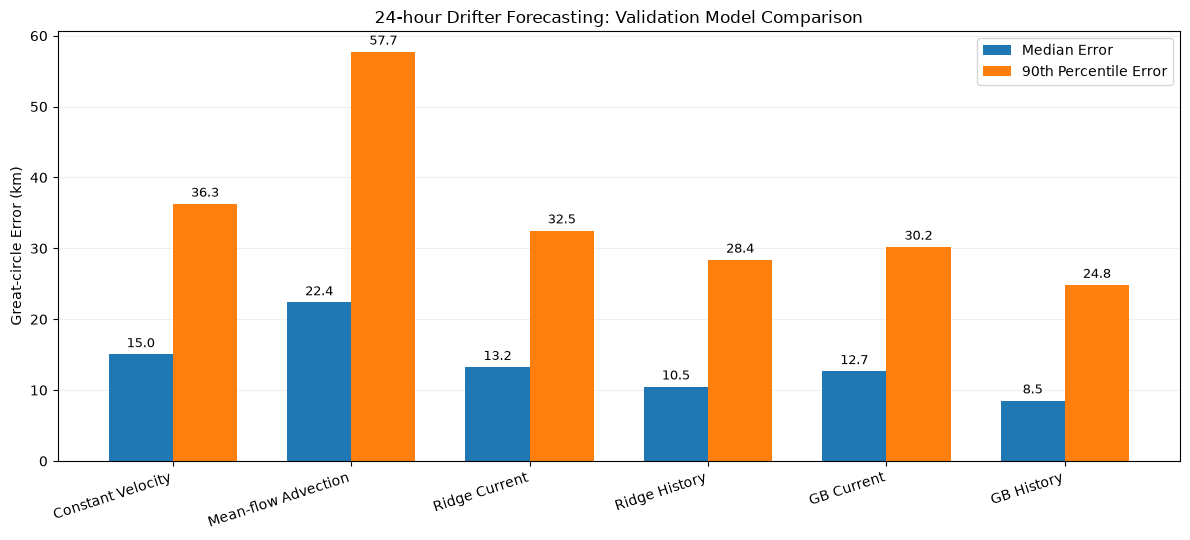

In [18]:
# Step 4.3 — Update six-model comparison with stepwise mean-flow

step_row = stepwise_results.loc[
    stepwise_results["Model"] == "Mean-flow Stepwise"
].iloc[0]

for metric in ["Mean", "Median", "P90", "RMSE"]:
    comparison.loc[
        comparison["Model"] == "Mean-flow Advection",
        metric
    ] = step_row[metric]

# Updated validation comparison
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(12, 5.5))

x = np.arange(len(comparison))
width = 0.36

bars1 = ax.bar(
    x - width / 2,
    comparison["Median"],
    width,
    label="Median Error"
)

bars2 = ax.bar(
    x + width / 2,
    comparison["P90"],
    width,
    label="90th Percentile Error"
)

ax.bar_label(bars1, fmt="%.1f", padding=3, fontsize=9)
ax.bar_label(bars2, fmt="%.1f", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(comparison["Model"], rotation=18, ha="right")
ax.set_ylabel("Great-circle Error (km)")
ax.set_title("24-hour Drifter Forecasting: Validation Model Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "report_six_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



### 4.3 Geometric Consistency Assessment

The machine-learning models predict eastward and northward displacement corrections relative to the Constant Velocity baseline. During target construction, observed displacements were approximated using local Cartesian coordinates centred at each forecast origin, while predicted positions were reconstructed using spherical forward-geodesic equations.

Although these approaches are closely related for short-range motion, they are not mathematically identical. The discrepancy may increase with displacement magnitude or latitude.

Before final test evaluation, the geometric approximation is assessed on the validation set by reconstructing observed target positions from their local displacement components and comparing them with the original geographic coordinates.

This assessment determines whether the existing displacement representation is sufficiently accurate for the 24-hour forecasting task or whether a consistent spherical inverse-geodesic target formulation is required.


In [19]:
# Step 4.4 — Geometric consistency assessment

geo_val = modelling.loc[
    modelling["split"] == "validation"
].copy()

# Reconstruct the observed endpoint using local displacement
lon_reconstructed, lat_reconstructed = displacement_to_position(
    geo_val["lon_t"],
    geo_val["lat_t"],
    geo_val["dx_true"],
    geo_val["dy_true"]
)

# Distance between reconstructed and actual endpoint
geometry_error_km = great_circle_error(
    lon_reconstructed,
    lat_reconstructed,
    geo_val["lon_target"],
    geo_val["lat_target"]
)

geometry_summary = pd.DataFrame({
    "Metric": ["Mean", "Median", "P90", "P99", "Maximum"],
    "Approximation Error (km)": [
        np.mean(geometry_error_km),
        np.median(geometry_error_km),
        np.quantile(geometry_error_km, 0.90),
        np.quantile(geometry_error_km, 0.99),
        np.max(geometry_error_km)
    ]
})

display(geometry_summary.round(5))

print(
    "Samples with geometry error > 0.1 km:",
    np.sum(geometry_error_km > 0.1)
)

print(
    "Samples with geometry error > 1 km:",
    np.sum(geometry_error_km > 1.0)
)


,Metric,Approximation Error (km)
0,Mean,0.10309
1,Median,0.02065
2,P90,0.21851
3,P99,1.53587
4,Maximum,2.98094


Samples with geometry error > 0.1 km: 15926
Samples with geometry error > 1 km: 1961



### 4.4 Geometric Consistency and Target Refinement

The geometric consistency assessment identified a small but non-negligible discrepancy between locally approximated displacement targets and spherical position reconstruction.

On the validation set, the median reconstruction error was 0.021 km, while the 99th-percentile error reached 1.536 km and the maximum approached 2.981 km. Approximately 2.2% of validation samples had reconstruction errors exceeding 1 km.

Although the typical discrepancy was small relative to forecasting errors, larger geometric discrepancies could affect the evaluation of high-displacement trajectories, which are particularly relevant to the analysis of motion characteristics.

To ensure consistency, observed target displacements were redefined using spherical inverse-geodesic calculations. The resulting eastward and northward components represent the great-circle distance and initial bearing from the forecast origin to the observed endpoint.

This representation is mathematically consistent with the spherical forward-geodesic transformation used to reconstruct predicted positions. All learned models will be refitted using the revised targets before final test evaluation.


In [20]:
# Step 4.5 — Geometrically consistent displacement targets

def position_to_displacement(lon0, lat0, lon1, lat1):
    """
    Spherical inverse geodesic.

    Returns east/north components (metres) of the
    great-circle displacement from origin to target.
    """
    lon0 = np.radians(np.asarray(lon0))
    lat0 = np.radians(np.asarray(lat0))
    lon1 = np.radians(np.asarray(lon1))
    lat1 = np.radians(np.asarray(lat1))

    dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat1 - lat0

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat0) * np.cos(lat1)
        * np.sin(dlon / 2) ** 2
    )

    angular_distance = 2 * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

    bearing = np.arctan2(
        np.sin(dlon) * np.cos(lat1),
        np.cos(lat0) * np.sin(lat1)
        - np.sin(lat0) * np.cos(lat1) * np.cos(dlon)
    )

    distance = EARTH_RADIUS * angular_distance

    dx = distance * np.sin(bearing)
    dy = distance * np.cos(bearing)

    return dx, dy


# Replace locally approximated targets
modelling["dx_true"], modelling["dy_true"] = (
    position_to_displacement(
        modelling["lon_t"],
        modelling["lat_t"],
        modelling["lon_target"],
        modelling["lat_target"]
    )
)

# Update residual targets
modelling["dx_residual"] = (
    modelling["dx_true"] - modelling["dx_cv"]
)

modelling["dy_residual"] = (
    modelling["dy_true"] - modelling["dy_cv"]
)

# Reconstruct targets using the revised displacement
val_geo = modelling.loc[
    modelling["split"] == "validation"
]

lon_check, lat_check = displacement_to_position(
    val_geo["lon_t"],
    val_geo["lat_t"],
    val_geo["dx_true"],
    val_geo["dy_true"]
)

reconstruction_error = great_circle_error(
    lon_check,
    lat_check,
    val_geo["lon_target"],
    val_geo["lat_target"]
)

print(
    "Maximum reconstruction error (metres):",
    np.max(reconstruction_error) * 1000
)

print(
    "Median reconstruction error (metres):",
    np.median(reconstruction_error) * 1000
)

# Save updated modelling dataset
modelling.to_parquet(
    DATA_DIR / "modelling_dataset_final.parquet",
    index=False
)


Maximum reconstruction error (metres): 4.955634356080134e-09
Median reconstruction error (metres): 0.0



## 5. Expanded Machine-Learning Benchmarking

Following the geometric refinement of the displacement targets, the machine-learning benchmark was expanded to evaluate whether the benefits of historical motion features generalise across different modelling approaches.

In addition to Ridge regression and Gradient Boosting, three complementary algorithms were introduced:

- **Elastic Net:** A regularised linear model combining L1 and L2 penalties, providing an alternative treatment of correlated and potentially redundant predictors.
- **Random Forest:** A bagging-based tree ensemble that captures nonlinear relationships and feature interactions through bootstrap aggregation.
- **Extra Trees:** An extremely randomised tree ensemble that introduces additional randomness into tree construction.

Each algorithm is evaluated using both current-state and history-enhanced features. All models predict eastward and northward displacement corrections relative to Constant Velocity, using the geometrically consistent spherical displacement targets.

The existing drifter-level training, validation and test partitions are retained. Hyperparameters are selected using validation performance, while the held-out test set remains untouched until model configurations are finalised.

The expanded benchmark aims to distinguish improvements attributable to historical information from those attributable to model flexibility or nonlinear learning.


In [21]:

# Step 5.1 — Refit Ridge using spherical displacement targets

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge

# Updated geometrically consistent targets
target_cols = ["dx_residual", "dy_residual"]

Y_train = modelling.loc[
    train_mask, target_cols
].to_numpy()

Y_val = modelling.loc[
    val_mask, target_cols
].to_numpy()

alphas = [0.1, 1, 10, 100, 1000]

ridge_models = {}
ridge_predictions = {}
ridge_results = []

val_data = modelling.loc[val_mask]

for model_name, cols in feature_sets.items():

    X_train = modelling.loc[train_mask, cols]
    X_val = modelling.loc[val_mask, cols]

    for alpha in alphas:

        model = Pipeline([
            ("imputer", SimpleImputer(
                strategy="median",
                add_indicator=True
            )),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha))
        ])

        model.fit(X_train, Y_train)

        residual_pred = model.predict(X_val)

        dx_pred = (
            val_data["dx_cv"].to_numpy()
            + residual_pred[:, 0]
        )

        dy_pred = (
            val_data["dy_cv"].to_numpy()
            + residual_pred[:, 1]
        )

        lon_pred, lat_pred = displacement_to_position(
            val_data["lon_t"],
            val_data["lat_t"],
            dx_pred,
            dy_pred
        )

        errors = great_circle_error(
            lon_pred,
            lat_pred,
            val_data["lon_target"],
            val_data["lat_target"]
        )

        ridge_results.append({
            "Model": model_name,
            "Alpha": alpha,
            "Mean": errors.mean(),
            "Median": np.median(errors),
            "P90": np.quantile(errors, 0.90),
            "RMSE": np.sqrt(np.mean(errors ** 2))
        })

        ridge_models[(model_name, alpha)] = model
        ridge_predictions[(model_name, alpha)] = errors

ridge_results = pd.DataFrame(ridge_results)

display(
    ridge_results.sort_values(
        ["Model", "Median"]
    ).round(3)
)


,Model,Alpha,Mean,Median,P90,RMSE
4,Ridge Current,1000.0,16.761,13.243,32.511,21.546
0,Ridge Current,0.1,16.764,13.244,32.523,21.549
1,Ridge Current,1.0,16.764,13.244,32.523,21.549
2,Ridge Current,10.0,16.764,13.244,32.522,21.549
3,Ridge Current,100.0,16.764,13.245,32.523,21.549
8,Ridge History,100.0,14.272,10.482,28.405,19.557
6,Ridge History,1.0,14.273,10.483,28.404,19.558
5,Ridge History,0.1,14.273,10.483,28.404,19.558
7,Ridge History,10.0,14.273,10.484,28.402,19.558
9,Ridge History,1000.0,14.285,10.496,28.410,19.567



### 5.1 Elastic Net Regression

Elastic Net regression was introduced as an alternative regularised linear model combining L1 and L2 penalties.

Unlike Ridge regression, Elastic Net can shrink some feature coefficients to zero, potentially reducing the influence of redundant predictors. This is particularly relevant because the history-enhanced feature set contains correlated measures of velocity, acceleration, turning and recent displacement.

Both current-only and history-enhanced Elastic Net models were trained to predict corrections to the Constant Velocity displacement. The same training and validation partitions and geometrically consistent targets were used.

Regularisation strength and the L1-to-L2 penalty ratio were selected using validation median great-circle error, enabling direct comparison with Ridge regression.


In [24]:
from sklearn.linear_model import MultiTaskElasticNet
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from pathlib import Path
import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

elastic_alphas = [0.01, 0.1, 1.0, 10.0]
l1_ratios = [0.2, 0.5, 0.8]

elastic_models = {}
elastic_predictions = {}
elastic_results = []

val_data = modelling.loc[val_mask]

for model_name, cols in [
    ("Elastic Net Current", current_features),
    ("Elastic Net History", current_features + history_features)
]:

    X_train = modelling.loc[train_mask, cols]
    X_val = modelling.loc[val_mask, cols]

    for alpha in elastic_alphas:
        for l1_ratio in l1_ratios:

            model = Pipeline([
                ("imputer", SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )),
                ("scaler", StandardScaler()),
                ("elastic", MultiTaskElasticNet(
                    alpha=alpha,
                    l1_ratio=l1_ratio,
                    max_iter=5000,
                    tol=1e-4,
                    random_state=42
                ))
            ])

            model.fit(X_train, Y_train)

            residual_pred = model.predict(X_val)

            dx_pred = (
                val_data["dx_cv"].to_numpy()
                + residual_pred[:, 0]
            )

            dy_pred = (
                val_data["dy_cv"].to_numpy()
                + residual_pred[:, 1]
            )

            lon_pred, lat_pred = displacement_to_position(
                val_data["lon_t"],
                val_data["lat_t"],
                dx_pred,
                dy_pred
            )

            errors = great_circle_error(
                lon_pred,
                lat_pred,
                val_data["lon_target"],
                val_data["lat_target"]
            )

            elastic_results.append({
                "Model": model_name,
                "Alpha": alpha,
                "L1 Ratio": l1_ratio,
                "Mean": errors.mean(),
                "Median": np.median(errors),
                "P90": np.quantile(errors, 0.90),
                "RMSE": np.sqrt(np.mean(errors ** 2))
            })

            elastic_models[(model_name, alpha, l1_ratio)] = model
            elastic_predictions[(model_name, alpha, l1_ratio)] = errors

elastic_results = pd.DataFrame(elastic_results)

# Save validation results
elastic_results.to_csv(
    MODEL_DIR / "elastic_net_validation_results.csv",
    index=False
)

# Save the best model for each feature configuration
best_elastic = elastic_results.loc[
    elastic_results.groupby("Model")["Median"].idxmin()
]

for _, row in best_elastic.iterrows():
    model = elastic_models[
        (row["Model"], row["Alpha"], row["L1 Ratio"])
    ]

    filename = (
        row["Model"].lower().replace(" ", "_")
        + ".joblib"
    )

    joblib.dump(model, MODEL_DIR / filename)

display(best_elastic.round(3))

,Model,Alpha,L1 Ratio,Mean,Median,P90,RMSE
7,Elastic Net Current,1.00,0.5,16.695,13.108,32.359,21.691
14,Elastic Net History,0.01,0.8,14.283,10.495,28.420,19.566



### 5.2 Random Forest Regression

Random Forest regression was added to evaluate nonlinear relationships and interactions between motion descriptors using a bagging-based ensemble.

Unlike Gradient Boosting, which sequentially fits trees to improve an existing prediction, Random Forest constructs multiple randomised decision trees and averages their predictions. This provides a complementary nonlinear modelling approach.

Current-only and history-enhanced Random Forest models were fitted using identical drifter-level partitions and geometrically consistent displacement targets. Tree complexity was controlled through maximum depth and minimum leaf size to manage overfitting and computational cost.

Hyperparameters were selected using validation median great-circle error.


In [25]:
from sklearn.ensemble import RandomForestRegressor
import time

rf_configs = [
    {"n_estimators": 100, "max_depth": 16,
     "min_samples_leaf": 20},
    {"n_estimators": 150, "max_depth": 20,
     "min_samples_leaf": 20},
    {"n_estimators": 150, "max_depth": 24,
     "min_samples_leaf": 10}
]

rf_models = {}
rf_results = []

val_data = modelling.loc[val_mask]

for model_name, cols in [
    ("RF Current", current_features),
    ("RF History", current_features + history_features)
]:

    X_train = modelling.loc[train_mask, cols].copy()
    X_val = modelling.loc[val_mask, cols].copy()

    # Fit imputation using training data only
    imputer = SimpleImputer(strategy="median")
    X_train_imp = imputer.fit_transform(X_train)
    X_val_imp = imputer.transform(X_val)

    for config_id, config in enumerate(rf_configs):

        start = time.time()

        model = RandomForestRegressor(
            **config,
            max_features=0.8,
            n_jobs=-1,
            random_state=42
        )

        model.fit(X_train_imp, Y_train)

        residual_pred = model.predict(X_val_imp)

        dx_pred = (
            val_data["dx_cv"].to_numpy()
            + residual_pred[:, 0]
        )

        dy_pred = (
            val_data["dy_cv"].to_numpy()
            + residual_pred[:, 1]
        )

        lon_pred, lat_pred = displacement_to_position(
            val_data["lon_t"],
            val_data["lat_t"],
            dx_pred,
            dy_pred
        )

        errors = great_circle_error(
            lon_pred,
            lat_pred,
            val_data["lon_target"],
            val_data["lat_target"]
        )

        elapsed = time.time() - start

        rf_results.append({
            "Model": model_name,
            "Config": config_id,
            "Mean": errors.mean(),
            "Median": np.median(errors),
            "P90": np.quantile(errors, 0.90),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "Training Time (s)": elapsed
        })

        # Store fitted model together with its imputer
        rf_models[(model_name, config_id)] = {
            "model": model,
            "imputer": imputer,
            "features": cols
        }

        print(
            f"{model_name} | Config {config_id} | "
            f"Median: {np.median(errors):.3f} km | "
            f"Time: {elapsed:.1f}s"
        )

rf_results = pd.DataFrame(rf_results)

display(
    rf_results.sort_values(
        ["Model", "Median"]
    ).round(3)
)

rf_results.to_csv(
    MODEL_DIR / "random_forest_validation_results.csv",
    index=False
)

# Save best configurations
best_rf = rf_results.loc[
    rf_results.groupby("Model")["Median"].idxmin()
]

for _, row in best_rf.iterrows():

    bundle = rf_models[
        (row["Model"], int(row["Config"]))
    ]

    filename = (
        row["Model"].lower().replace(" ", "_")
        + ".joblib"
    )

    joblib.dump(bundle, MODEL_DIR / filename)


RF Current | Config 0 | Median: 12.616 km | Time: 29.7s
RF Current | Config 1 | Median: 12.647 km | Time: 48.0s
RF Current | Config 2 | Median: 12.708 km | Time: 52.8s
RF History | Config 0 | Median: 8.828 km | Time: 93.1s
RF History | Config 1 | Median: 8.635 km | Time: 154.8s
RF History | Config 2 | Median: 8.539 km | Time: 172.8s


,Model,Config,Mean,Median,P90,RMSE,Training Time (s)
0,RF Current,0,15.871,12.616,30.515,20.352,29.670
1,RF Current,1,15.920,12.647,30.643,20.421,47.995
2,RF Current,2,16.009,12.708,30.847,20.536,52.783
5,RF History,2,12.035,8.539,25.197,16.873,172.841
4,RF History,1,12.142,8.635,25.414,16.952,154.793
3,RF History,0,12.275,8.828,25.524,17.027,93.105



### 5.3 Extra Trees Regression

Extremely Randomised Trees (Extra Trees) were introduced as a second bagging-style tree ensemble to assess the effect of additional randomisation during model construction.

Unlike Random Forest, Extra Trees typically uses the full training sample for each tree and selects random candidate splitting thresholds rather than optimising each threshold exhaustively. This may reduce variance and computational cost, although its effect on predictive accuracy is data-dependent.

Current-only and history-enhanced models were evaluated using the same features, drifter-level partitions, and spherical displacement targets as the other learned models. Model complexity was controlled through tree depth and minimum leaf size, and configurations were selected using validation median great-circle error.


In [26]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import time

et_configs = [
    {"n_estimators": 150, "max_depth": 16,
     "min_samples_leaf": 20},
    {"n_estimators": 150, "max_depth": 20,
     "min_samples_leaf": 20},
    {"n_estimators": 150, "max_depth": 24,
     "min_samples_leaf": 10}
]

et_models = {}
et_results = []

val_data = modelling.loc[val_mask]

for model_name, cols in [
    ("ET Current", current_features),
    ("ET History", current_features + history_features)
]:

    X_train = modelling.loc[train_mask, cols]
    X_val = modelling.loc[val_mask, cols]

    for config_id, config in enumerate(et_configs):

        start = time.time()

        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("extra_trees", ExtraTreesRegressor(
                **config,
                max_features=0.8,
                bootstrap=False,
                n_jobs=-1,
                random_state=42
            ))
        ])

        model.fit(X_train, Y_train)

        residual_pred = model.predict(X_val)

        dx_pred = (
            val_data["dx_cv"].to_numpy()
            + residual_pred[:, 0]
        )

        dy_pred = (
            val_data["dy_cv"].to_numpy()
            + residual_pred[:, 1]
        )

        lon_pred, lat_pred = displacement_to_position(
            val_data["lon_t"],
            val_data["lat_t"],
            dx_pred,
            dy_pred
        )

        errors = great_circle_error(
            lon_pred,
            lat_pred,
            val_data["lon_target"],
            val_data["lat_target"]
        )

        elapsed = time.time() - start

        et_results.append({
            "Model": model_name,
            "Config": config_id,
            "Mean": errors.mean(),
            "Median": np.median(errors),
            "P90": np.quantile(errors, 0.90),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "Training Time (s)": elapsed
        })

        et_models[(model_name, config_id)] = model

        print(
            f"{model_name} | Config {config_id} | "
            f"Median: {np.median(errors):.3f} km | "
            f"Time: {elapsed:.1f}s"
        )

et_results = pd.DataFrame(et_results)

display(
    et_results.sort_values(
        ["Model", "Median"]
    ).round(3)
)

et_results.to_csv(
    MODEL_DIR / "extra_trees_validation_results.csv",
    index=False
)

# Save the best model for each feature configuration
best_et = et_results.loc[
    et_results.groupby("Model")["Median"].idxmin()
]

for _, row in best_et.iterrows():

    model = et_models[
        (row["Model"], int(row["Config"]))
    ]

    filename = (
        row["Model"].lower().replace(" ", "_")
        + ".joblib"
    )

    joblib.dump(model, MODEL_DIR / filename)


ET Current | Config 0 | Median: 12.626 km | Time: 10.7s
ET Current | Config 1 | Median: 12.619 km | Time: 11.4s
ET Current | Config 2 | Median: 12.613 km | Time: 12.6s
ET History | Config 0 | Median: 9.298 km | Time: 27.5s
ET History | Config 1 | Median: 8.867 km | Time: 34.9s
ET History | Config 2 | Median: 8.627 km | Time: 40.7s


,Model,Config,Mean,Median,P90,RMSE,Training Time (s)
2,ET Current,2,15.834,12.613,30.168,20.306,12.556
1,ET Current,1,15.813,12.619,30.108,20.260,11.360
0,ET Current,0,15.784,12.626,30.063,20.225,10.749
5,ET History,2,12.085,8.627,25.273,16.812,40.687
4,ET History,1,12.317,8.867,25.573,17.006,34.860
3,ET History,0,12.651,9.298,25.899,17.227,27.482


In [27]:

# Step 5.5 — Refit Gradient Boosting with spherical targets

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import joblib
import time

gb_configs = [
    {"max_iter": 150, "max_leaf_nodes": 15,
     "learning_rate": 0.08},
    {"max_iter": 200, "max_leaf_nodes": 31,
     "learning_rate": 0.06},
    {"max_iter": 250, "max_leaf_nodes": 31,
     "learning_rate": 0.08}
]

gb_models = {}
gb_results = []

val_data = modelling.loc[val_mask]

for model_name, cols in [
    ("GB Current", current_features),
    ("GB History", current_features + history_features)
]:

    X_train = modelling.loc[train_mask, cols]
    X_val = modelling.loc[val_mask, cols]

    for config_id, config in enumerate(gb_configs):

        start = time.time()

        model = MultiOutputRegressor(
            HistGradientBoostingRegressor(
                **config,
                l2_regularization=1.0,
                min_samples_leaf=50,
                random_state=42
            ),
            n_jobs=2
        )

        # HistGradientBoostingRegressor handles NaNs natively
        model.fit(X_train, Y_train)

        residual_pred = model.predict(X_val)

        dx_pred = (
            val_data["dx_cv"].to_numpy()
            + residual_pred[:, 0]
        )

        dy_pred = (
            val_data["dy_cv"].to_numpy()
            + residual_pred[:, 1]
        )

        lon_pred, lat_pred = displacement_to_position(
            val_data["lon_t"],
            val_data["lat_t"],
            dx_pred,
            dy_pred
        )

        errors = great_circle_error(
            lon_pred,
            lat_pred,
            val_data["lon_target"],
            val_data["lat_target"]
        )

        elapsed = time.time() - start

        gb_results.append({
            "Model": model_name,
            "Config": config_id,
            "Mean": errors.mean(),
            "Median": np.median(errors),
            "P90": np.quantile(errors, 0.90),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "Training Time (s)": elapsed
        })

        gb_models[(model_name, config_id)] = model

        print(
            f"{model_name} | Config {config_id} | "
            f"Median: {np.median(errors):.3f} km | "
            f"Time: {elapsed:.1f}s"
        )

gb_results = pd.DataFrame(gb_results)

display(
    gb_results.sort_values(
        ["Model", "Median"]
    ).round(3)
)

gb_results.to_csv(
    MODEL_DIR / "gradient_boosting_validation_results.csv",
    index=False
)

# Save best configurations
best_gb = gb_results.loc[
    gb_results.groupby("Model")["Median"].idxmin()
]

for _, row in best_gb.iterrows():

    model = gb_models[
        (row["Model"], int(row["Config"]))
    ]

    filename = (
        row["Model"].lower().replace(" ", "_")
        + ".joblib"
    )

    joblib.dump(model, MODEL_DIR / filename)


GB Current | Config 0 | Median: 12.685 km | Time: 3.3s
GB Current | Config 1 | Median: 12.664 km | Time: 3.1s
GB Current | Config 2 | Median: 12.661 km | Time: 3.3s
GB History | Config 0 | Median: 9.106 km | Time: 3.8s
GB History | Config 1 | Median: 8.702 km | Time: 6.1s
GB History | Config 2 | Median: 8.507 km | Time: 6.4s


,Model,Config,Mean,Median,P90,RMSE,Training Time (s)
2,GB Current,2,15.772,12.661,30.192,20.161,3.252
1,GB Current,1,15.742,12.664,30.103,20.058,3.127
0,GB Current,0,15.808,12.685,30.259,20.150,3.310
5,GB History,2,11.969,8.507,24.977,16.681,6.384
4,GB History,1,12.155,8.702,25.312,16.852,6.091
3,GB History,0,12.542,9.106,25.956,17.216,3.837



### 5.4 Consolidated Validation Results

The expanded validation benchmark comprises two physical baselines and ten learned forecasting configurations across five model families.

All learned models use geometrically consistent spherical displacement targets and identical drifter-level training and validation partitions. For each model family and feature configuration, hyperparameters were selected by minimum validation median great-circle error.

The results are compared using mean, median, 90th-percentile and root-mean-square position errors. The incremental predictive value of trajectory history is assessed by comparing the current-only and history-enhanced variants within each model family.

These validation results are used to finalise model configurations before evaluation on the untouched test set.


,Model,Mean,Median,P90,RMSE
0,Constant Velocity,18.883,15.044,36.273,24.496
1,Mean-flow Advection,28.648,22.368,57.730,37.158
2,Ridge Current,16.761,13.243,32.511,21.546
3,Ridge History,14.272,10.482,28.405,19.557
4,Elastic Net Current,16.695,13.108,32.359,21.691
5,Elastic Net History,14.283,10.495,28.420,19.566
6,RF Current,15.871,12.616,30.515,20.352
7,RF History,12.035,8.539,25.197,16.873
8,ET Current,15.834,12.613,30.168,20.306
9,ET History,12.085,8.627,25.273,16.812


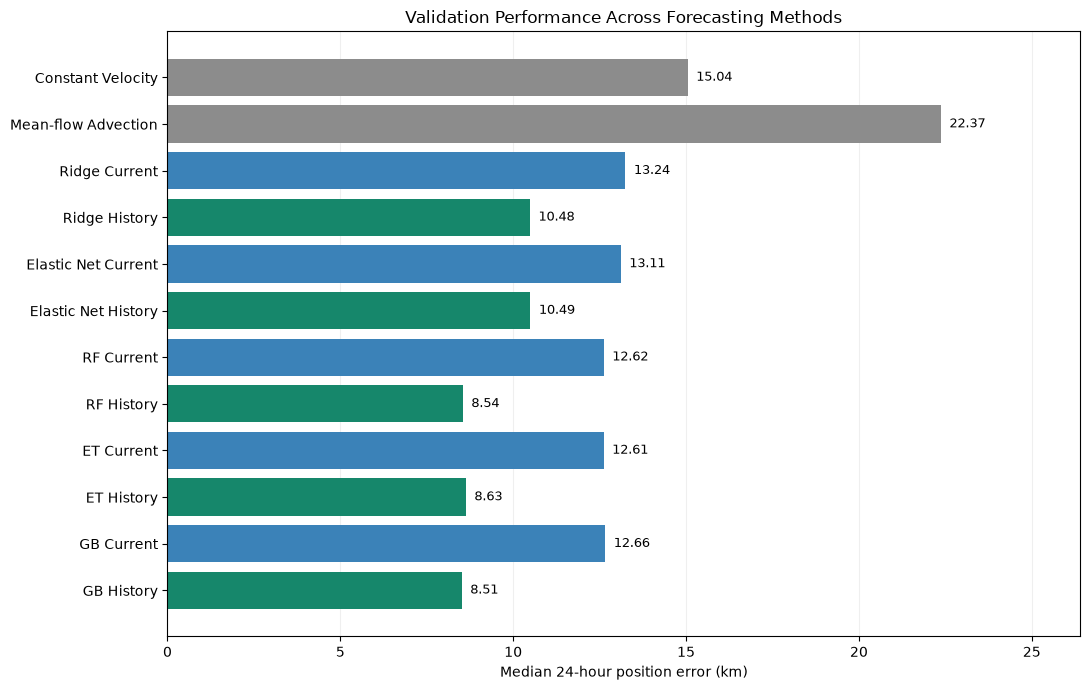

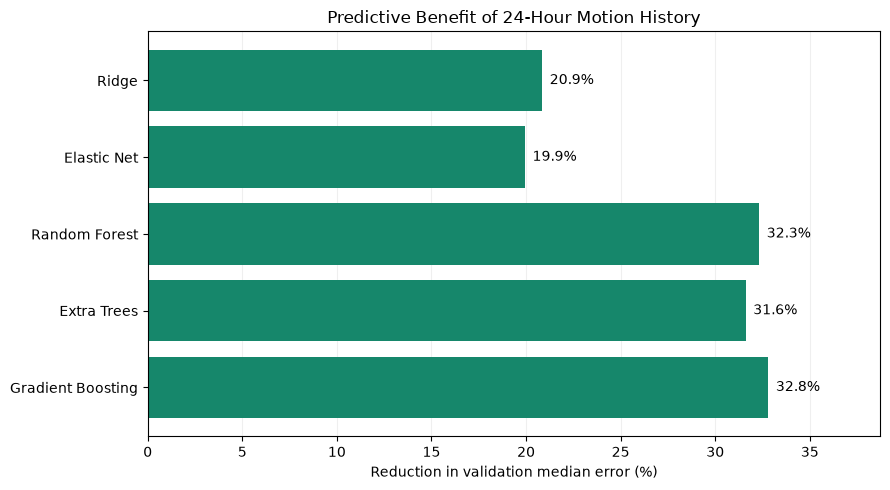

,Model Family,Current Median,History Median,Improvement (%)
0,Ridge,13.243,10.482,20.850
1,Elastic Net,13.108,10.495,19.940
2,Random Forest,12.616,8.539,32.320
3,Extra Trees,12.613,8.627,31.606
4,Gradient Boosting,12.661,8.507,32.804


In [28]:

# Step 5.6 — Consolidated validation comparison

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("../image")
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

metrics = ["Mean", "Median", "P90", "RMSE"]

# Select best configurations from each learned model family
learned_results = pd.concat([
    ridge_results.loc[
        ridge_results.groupby("Model")["Median"].idxmin()
    ],
    elastic_results.loc[
        elastic_results.groupby("Model")["Median"].idxmin()
    ],
    rf_results.loc[
        rf_results.groupby("Model")["Median"].idxmin()
    ],
    et_results.loc[
        et_results.groupby("Model")["Median"].idxmin()
    ],
    gb_results.loc[
        gb_results.groupby("Model")["Median"].idxmin()
    ]
], ignore_index=True)

learned_results = learned_results[
    ["Model"] + metrics
].copy()

# Reuse the final physical-baseline validation metrics
physical_results = pd.DataFrame([
    {
        "Model": "Constant Velocity",
        "Mean": 18.883,
        "Median": 15.044,
        "P90": 36.273,
        "RMSE": 24.496
    },
    {
        "Model": "Mean-flow Advection",
        "Mean": 28.648,
        "Median": 22.368,
        "P90": 57.730,
        "RMSE": 37.158
    }
])

comparison_final = pd.concat(
    [physical_results, learned_results],
    ignore_index=True
)

model_order = [
    "Constant Velocity",
    "Mean-flow Advection",
    "Ridge Current",
    "Ridge History",
    "Elastic Net Current",
    "Elastic Net History",
    "RF Current",
    "RF History",
    "ET Current",
    "ET History",
    "GB Current",
    "GB History"
]

comparison_final["Model"] = pd.Categorical(
    comparison_final["Model"],
    categories=model_order,
    ordered=True
)

comparison_final = (
    comparison_final
    .sort_values("Model")
    .reset_index(drop=True)
)

display(comparison_final.round(3))

comparison_final.to_csv(
    MODEL_DIR / "final_validation_comparison.csv",
    index=False
)

# Figure 1: Median validation error across all methods
fig, ax = plt.subplots(figsize=(11, 7))

names = comparison_final["Model"].astype(str)
values = comparison_final["Median"].to_numpy()

colors = [
    "#8C8C8C" if name in [
        "Constant Velocity", "Mean-flow Advection"
    ]
    else "#3B82B8" if "Current" in name
    else "#16876B"
    for name in names
]

bars = ax.barh(names, values, color=colors)

ax.invert_yaxis()
ax.set_xlabel("Median 24-hour position error (km)")
ax.set_title("Validation Performance Across Forecasting Methods")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for bar, value in zip(bars, values):
    ax.text(
        value + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, max(values) * 1.18)

fig.tight_layout()
fig.savefig(
    FIG_DIR / "report_expanded_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Figure 2: Historical-feature improvement by model family
families = [
    ("Ridge", "Ridge Current", "Ridge History"),
    ("Elastic Net", "Elastic Net Current", "Elastic Net History"),
    ("Random Forest", "RF Current", "RF History"),
    ("Extra Trees", "ET Current", "ET History"),
    ("Gradient Boosting", "GB Current", "GB History")
]

history_gain = []

for family, current_name, history_name in families:

    current_median = comparison_final.loc[
        comparison_final["Model"] == current_name,
        "Median"
    ].iloc[0]

    history_median = comparison_final.loc[
        comparison_final["Model"] == history_name,
        "Median"
    ].iloc[0]

    history_gain.append({
        "Model Family": family,
        "Current Median": current_median,
        "History Median": history_median,
        "Improvement (%)": (
            (current_median - history_median)
            / current_median * 100
        )
    })

history_gain = pd.DataFrame(history_gain)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    history_gain["Model Family"],
    history_gain["Improvement (%)"],
    color="#16876B"
)

ax.invert_yaxis()
ax.set_xlabel("Reduction in validation median error (%)")
ax.set_title("Predictive Benefit of 24-Hour Motion History")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for bar, value in zip(
    bars,
    history_gain["Improvement (%)"]
):
    ax.text(
        value + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

ax.set_xlim(
    0,
    history_gain["Improvement (%)"].max() * 1.18
)

fig.tight_layout()
fig.savefig(
    FIG_DIR / "report_expanded_history_gain.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(history_gain.round(3))



### 5.5 Interpretation of Validation Performance

The expanded benchmark provides consistent evidence that recent trajectory history improves 24-hour position forecasting across different learning algorithms.

All five model families achieved lower validation median errors when historical motion descriptors were included. The relative reductions ranged from approximately 19.9% for Elastic Net to 32.8% for Gradient Boosting.

The nonlinear tree ensembles benefited more substantially from historical information than the regularised linear models. This suggests that nonlinear relationships and interactions among recent motion descriptors may contribute to forecast accuracy beyond the information captured by linear corrections.

Gradient Boosting with historical features achieved the lowest validation median error of 8.507 km, compared with 15.044 km for Constant Velocity. Random Forest and Extra Trees achieved similar performance, indicating that the improvement was not specific to a single tree-ensemble algorithm.

The regional mean-flow baseline performed worse than Constant Velocity, suggesting that a spatially averaged velocity field does not adequately represent individual 24-hour trajectories in this setting.

These findings are preliminary validation results rather than final generalisation estimates. The selected configurations will be evaluated on held-out drifters, with particular emphasis on motion-dependent errors and uncertainty arising from repeated forecasts within trajectories.



## 6. Held-out Test Evaluation

Following validation-based hyperparameter selection, the forecasting configurations were frozen and evaluated on the previously untouched test partition.

The test set contains 82,546 forecast origins from 78 held-out drifters. All twelve forecasting methods are evaluated on identical observations using great-circle position errors.

For each forecast, the predicted geographic coordinates and corresponding distance error are retained alongside the drifter identifier, forecast origin, and pre-forecast motion descriptors. This enables paired model comparisons, motion-conditioned error analysis, and uncertainty estimation that accounts for repeated observations within individual drifters.

No further model selection or hyperparameter tuning is performed using test results.


In [29]:

# Step 6.1 — Held-out test predictions

test_data = modelling.loc[
    modelling["split"] == "test"
].copy()

test_predictions = test_data.copy()

model_specs = {}

# Retrieve validation-selected configurations
for results, models, prefix, parameter in [
    (ridge_results, ridge_models, "Ridge", "Alpha"),
    (elastic_results, elastic_models, "Elastic Net", "Alpha"),
    (rf_results, rf_models, "RF", "Config"),
    (et_results, et_models, "ET", "Config"),
    (gb_results, gb_models, "GB", "Config")
]:
    for variant in ["Current", "History"]:

        name = f"{prefix} {variant}"

        best = results.loc[
            results["Model"] == name
        ].sort_values("Median").iloc[0]

        if prefix == "Elastic Net":
            key = (
                name,
                best["Alpha"],
                best["L1 Ratio"]
            )
        else:
            key = (name, best[parameter])

        model_specs[name] = models[key]


# Constant Velocity
lon_cv, lat_cv = displacement_to_position(
    test_data["lon_t"],
    test_data["lat_t"],
    test_data["dx_cv"],
    test_data["dy_cv"]
)

test_predictions["Constant Velocity_lon"] = lon_cv
test_predictions["Constant Velocity_lat"] = lat_cv


# Mean-flow Advection
lon_flow, lat_flow, fallback_steps = stepwise_mean_flow(
    test_data,
    flow_lookup,
    grid_size=GRID_SIZE
)

test_predictions["Mean-flow Advection_lon"] = lon_flow
test_predictions["Mean-flow Advection_lat"] = lat_flow
test_predictions["mean_flow_fallback_steps"] = fallback_steps


# Learned models
for name, fitted in model_specs.items():

    cols = (
        current_features
        if "Current" in name
        else current_features + history_features
    )

    X_test = test_data[cols]

    if name.startswith("RF"):
        residual_pred = fitted["model"].predict(
            fitted["imputer"].transform(X_test)
        )
    else:
        residual_pred = fitted.predict(X_test)

    dx_pred = (
        test_data["dx_cv"].to_numpy()
        + residual_pred[:, 0]
    )

    dy_pred = (
        test_data["dy_cv"].to_numpy()
        + residual_pred[:, 1]
    )

    lon_pred, lat_pred = displacement_to_position(
        test_data["lon_t"],
        test_data["lat_t"],
        dx_pred,
        dy_pred
    )

    test_predictions[f"{name}_lon"] = lon_pred
    test_predictions[f"{name}_lat"] = lat_pred


# Calculate great-circle errors for all methods
test_results = []

for name in model_order:

    errors = great_circle_error(
        test_predictions[f"{name}_lon"],
        test_predictions[f"{name}_lat"],
        test_predictions["lon_target"],
        test_predictions["lat_target"]
    )

    test_predictions[f"{name}_error"] = errors

    test_results.append({
        "Model": name,
        "Mean": np.mean(errors),
        "Median": np.median(errors),
        "P90": np.quantile(errors, 0.90),
        "RMSE": np.sqrt(np.mean(errors ** 2))
    })

test_results = pd.DataFrame(test_results)

display(test_results.round(3))

# Save per-forecast predictions and overall metrics
DATA_DIR = Path("../data/processed")
DATA_DIR.mkdir(parents=True, exist_ok=True)

test_predictions.to_parquet(
    DATA_DIR / "report_test_predictions.parquet",
    index=False
)

test_results.to_csv(
    MODEL_DIR / "final_test_comparison.csv",
    index=False
)

print(
    "Test samples:",
    len(test_predictions)
)

print(
    "Held-out drifters:",
    test_predictions["trajectory_id"].nunique()
)

print(
    "Saved per-forecast predictions and test metrics."
)


,Model,Mean,Median,P90,RMSE
0,Constant Velocity,20.552,15.886,40.899,26.767
1,Mean-flow Advection,32.384,24.281,68.797,42.054
2,Ridge Current,18.491,14.141,37.702,24.000
3,Ridge History,16.148,11.581,33.556,22.203
4,Elastic Net Current,18.289,13.954,36.937,23.903
5,Elastic Net History,16.165,11.595,33.594,22.229
6,RF Current,17.001,13.051,34.374,22.072
7,RF History,13.326,9.254,28.812,18.778
8,ET Current,17.121,13.159,34.645,22.202
9,ET History,13.373,9.334,28.908,18.753


Test samples: 82546
Held-out drifters: 78
Saved per-forecast predictions and test metrics.



### 6.1 Geographic Forecast Case Studies

To complement aggregate performance metrics, representative held-out forecasts are visualised geographically.

Each case displays the observed 24-hour motion history, the observed future trajectory, and the predicted 24-hour endpoints from selected forecasting methods. Predicted endpoints are connected to the forecast origin for visual comparison; these connecting segments do not represent recursively predicted trajectories.

Four illustrative cases are selected using reproducible criteria: a typical forecast, a difficult forecast, a case where historical information substantially improves prediction, and a case where historical information worsens prediction.

These examples illustrate forecast geometry and model behaviour but are not intended to establish population-level performance differences.


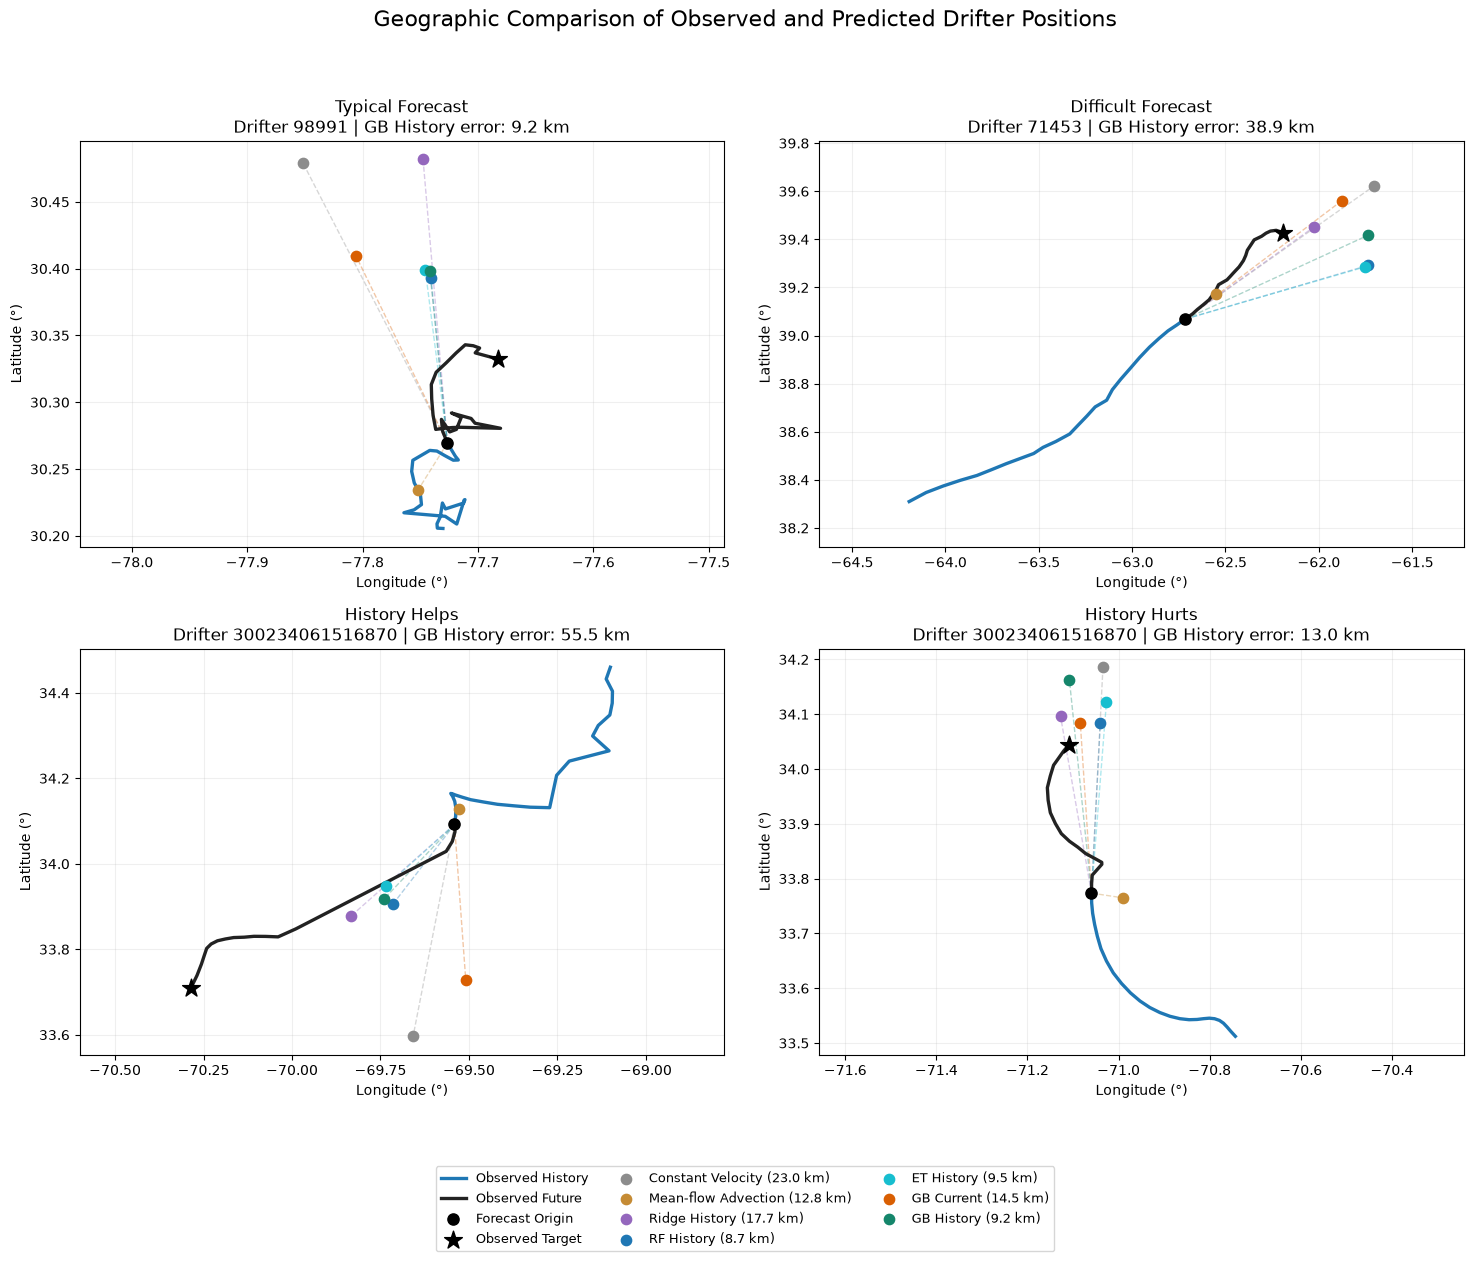

In [30]:
# Step 6.2 — Geographic forecast case studies

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np

# Select reproducible cases
cases = test_predictions.copy()

cases["history_gain"] = (
    cases["GB Current_error"]
    - cases["GB History_error"]
)

median_error = cases["GB History_error"].median()

case_indices = {
    "Typical Forecast": (
        cases["GB History_error"] - median_error
    ).abs().idxmin(),

    "Difficult Forecast": (
        cases["GB History_error"]
        - cases["GB History_error"].quantile(0.95)
    ).abs().idxmin(),

    "History Helps": (
        cases["history_gain"]
        - cases["history_gain"].quantile(0.95)
    ).abs().idxmin(),

    "History Hurts": (
        cases["history_gain"]
        - cases["history_gain"].quantile(0.05)
    ).abs().idxmin()
}

# Load complete drifter observations
trajectory_data = pd.read_parquet(
    DATA_DIR / "gulf_stream_trajectories.parquet",
    columns=["trajectory_id", "time", "lon", "lat"]
)

trajectory_data["time"] = pd.to_datetime(
    trajectory_data["time"], utc=True
)

trajectory_data = trajectory_data.sort_values(
    ["trajectory_id", "time"]
)

selected_models = [
    "Constant Velocity",
    "Mean-flow Advection",
    "Ridge History",
    "RF History",
    "ET History",
    "GB Current",
    "GB History"
]

model_colors = {
    "Constant Velocity": "#8C8C8C",
    "Mean-flow Advection": "#C58B34",
    "Ridge History": "#9467BD",
    "RF History": "#1F77B4",
    "ET History": "#17BECF",
    "GB Current": "#D95F02",
    "GB History": "#15866B"
}

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 12)
)

for ax, (case_name, idx) in zip(
    axes.flat, case_indices.items()
):

    case = cases.loc[idx]

    drifter_id = case["trajectory_id"]
    t = pd.Timestamp(case["time"])

    if t.tzinfo is None:
        t = t.tz_localize("UTC")
    else:
        t = t.tz_convert("UTC")

    track = trajectory_data.loc[
        (trajectory_data["trajectory_id"] == drifter_id)
        & (trajectory_data["time"] >= t - pd.Timedelta(hours=24))
        & (trajectory_data["time"] <= t + pd.Timedelta(hours=24))
    ].copy()

    history = track.loc[track["time"] <= t]
    future = track.loc[track["time"] >= t]

    # Break lines at missing hourly observations
    for segment, color, label in [
        (history, "#1F77B4", "Observed History"),
        (future, "#222222", "Observed Future")
    ]:
        segment = segment.copy()
        segment["gap"] = (
            segment["time"].diff().dt.total_seconds()
            .fillna(3600) > 3600
        )
        segment["segment_id"] = segment["gap"].cumsum()

        first = True
        for _, part in segment.groupby("segment_id"):
            ax.plot(
                part["lon"],
                part["lat"],
                color=color,
                linewidth=2.4,
                label=label if first else None,
                zorder=3
            )
            first = False

    # Forecast origin and actual target
    ax.scatter(
        case["lon_t"], case["lat_t"],
        color="black", marker="o", s=65,
        zorder=6, label="Forecast Origin"
    )

    ax.scatter(
        case["lon_target"], case["lat_target"],
        color="black", marker="*", s=180,
        zorder=7, label="Observed Target"
    )

    # Model-predicted endpoints
    for name in selected_models:

        lon_pred = case[f"{name}_lon"]
        lat_pred = case[f"{name}_lat"]

        ax.plot(
            [case["lon_t"], lon_pred],
            [case["lat_t"], lat_pred],
            color=model_colors[name],
            alpha=0.35,
            linewidth=1,
            linestyle="--"
        )

        ax.scatter(
            lon_pred, lat_pred,
            color=model_colors[name],
            s=55,
            zorder=5,
            label=f"{name} ({case[f'{name}_error']:.1f} km)"
        )

    # Approximate local geographic aspect ratio
    ax.set_aspect(
        1 / np.cos(np.radians(case["lat_t"])),
        adjustable="datalim"
    )

    ax.set_title(
        f"{case_name}\n"
        f"Drifter {drifter_id} | "
        f"GB History error: {case['GB History_error']:.1f} km"
    )

    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.grid(alpha=0.2)

# One shared legend to reduce clutter
handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.03),
    ncol=3,
    fontsize=9
)

fig.suptitle(
    "Geographic Comparison of Observed and Predicted Drifter Positions",
    fontsize=16,
    y=1.01
)

fig.tight_layout(rect=[0, 0.09, 1, 0.98])

fig.savefig(
    FIG_DIR / "report_geographic_forecast_cases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 6.2 Regional Rolling-Forecast Trajectory Comparison

To visualise model behaviour beyond individual forecast endpoints, rolling 24-hour predictions are assembled into geographically aligned trajectory overlays.

For each held-out drifter, forecasts issued at successive origin times are ordered by their target timestamps. The predicted 24-hour endpoints form a rolling predicted-endpoint track, which is compared against the observed positions at those same target times.

These tracks represent a sequence of independently issued 24-hour forecasts, rather than a single recursively simulated trajectory. This distinction is important because each prediction uses an updated observed origin and, for history-enhanced models, the preceding observed motion history.

To examine regional behaviour, a reproducible subset of held-out drifters is selected based on observation coverage rather than forecast accuracy. The same drifters and timestamps are used for every model, allowing direct visual comparison of spatial deviations and trajectory geometry.


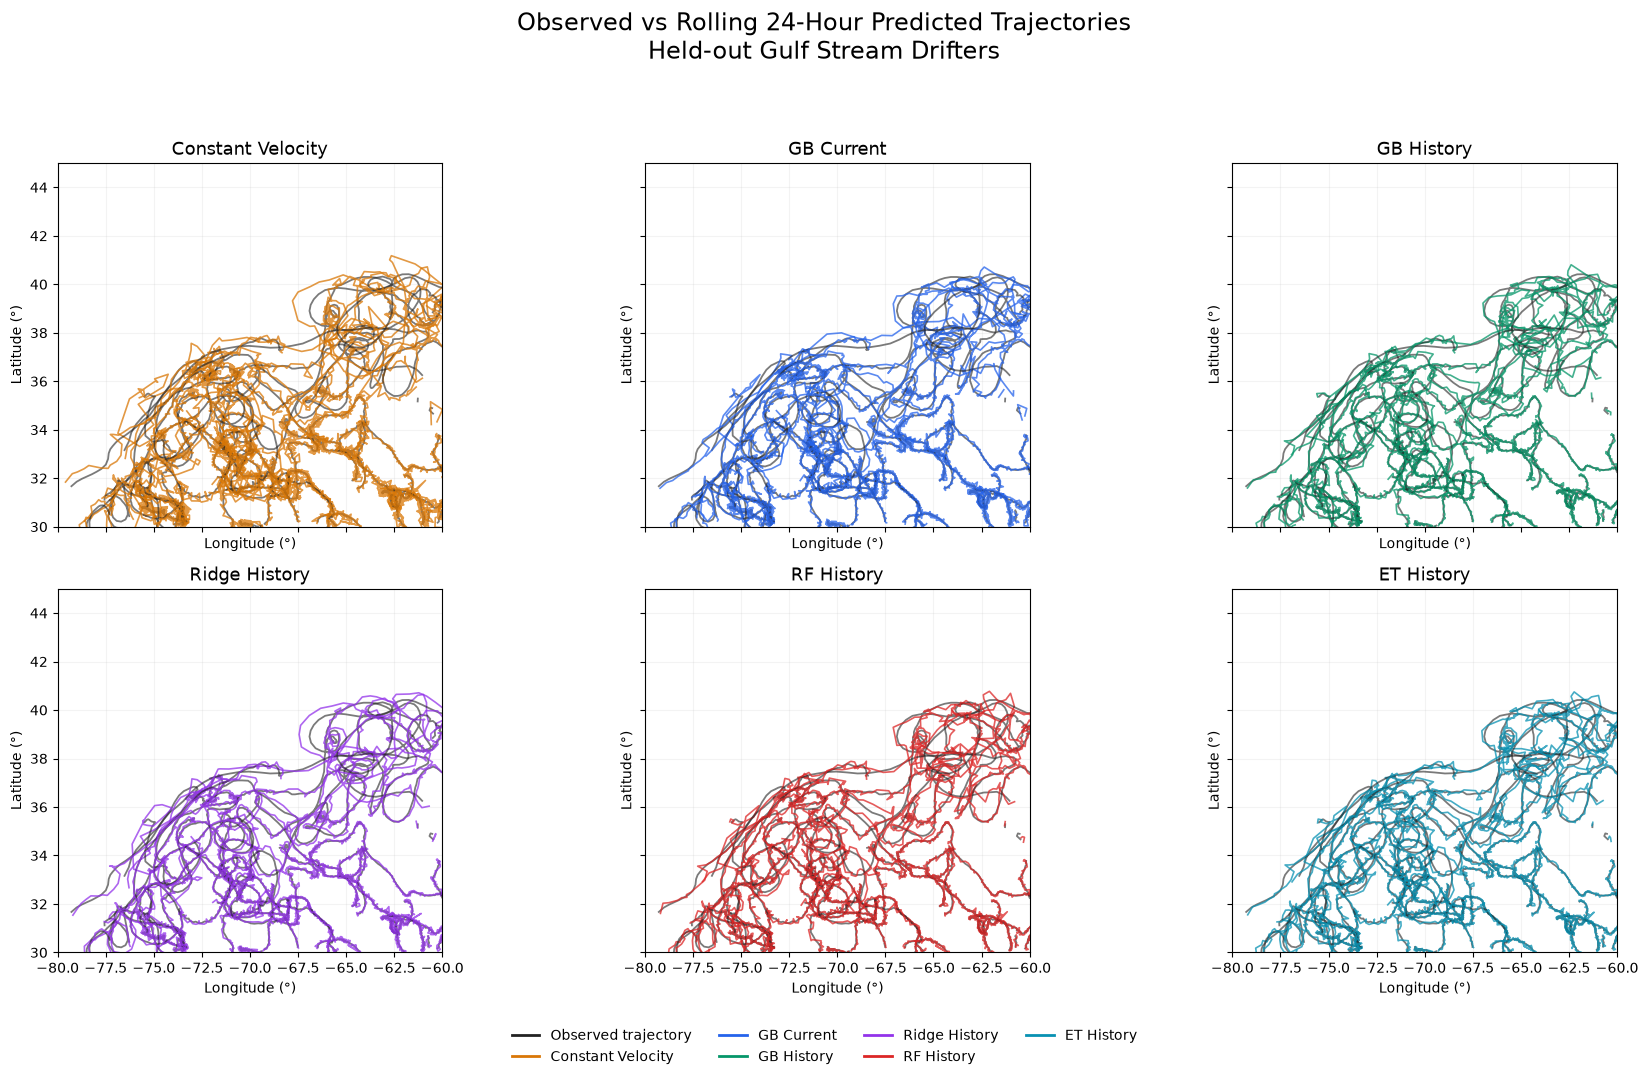

Drifters visualised: 12
Forecast endpoints visualised: 5252


In [31]:

# Step 6.3 — Regional rolling 24-hour forecast overlays

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select well-observed held-out drifters
drifter_counts = (
    test_predictions
    .groupby("trajectory_id")
    .size()
    .sort_values(ascending=False)
)

selected_ids = drifter_counts.head(12).index

overlay = test_predictions.loc[
    test_predictions["trajectory_id"].isin(selected_ids)
].copy()

overlay["time"] = pd.to_datetime(overlay["time"], utc=True)
overlay["target_time"] = overlay["time"] + pd.Timedelta(hours=24)

# Reduce visual density using a fixed six-hour sampling interval
overlay = overlay.loc[
    overlay["time"].dt.hour % 6 == 0
].copy()

overlay = overlay.sort_values(
    ["trajectory_id", "target_time"]
)

models_to_plot = [
    "Constant Velocity",
    "GB Current",
    "GB History",
    "Ridge History",
    "RF History",
    "ET History"
]

model_colors = {
    "Constant Velocity": "#D97706",
    "GB Current": "#2563EB",
    "GB History": "#059669",
    "Ridge History": "#9333EA",
    "RF History": "#DC2626",
    "ET History": "#0891B2"
}

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11),
    sharex=True,
    sharey=True
)

for ax, model_name in zip(axes.flat, models_to_plot):

    for drifter_id, track in overlay.groupby("trajectory_id"):

        track = track.sort_values("target_time").copy()

        # Break lines across missing forecast timestamps
        track["segment_id"] = (
            track["target_time"]
            .diff()
            .dt.total_seconds()
            .fillna(21600)
            .gt(21600)
            .cumsum()
        )

        for _, segment in track.groupby("segment_id"):

            if len(segment) < 2:
                continue

            # Observed trajectory at forecast target times
            ax.plot(
                segment["lon_target"],
                segment["lat_target"],
                color="#222222",
                linewidth=1.3,
                alpha=0.6
            )

            # Rolling predicted-endpoint track
            ax.plot(
                segment[f"{model_name}_lon"],
                segment[f"{model_name}_lat"],
                color=model_colors[model_name],
                linewidth=1.2,
                alpha=0.75
            )

    ax.set_title(model_name, fontsize=13)
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.grid(alpha=0.15)

    # Geographic aspect ratio at the study-region midpoint
    ax.set_aspect(
        1 / np.cos(np.radians(37.5)),
        adjustable="box"
    )

# Shared regional extent
axes[0, 0].set_xlim(-80, -60)
axes[0, 0].set_ylim(30, 45)

from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0], [0], color="#222222",
           lw=2, label="Observed trajectory")
]

legend_handles += [
    Line2D(
        [0], [0],
        color=model_colors[name],
        lw=2,
        label=name
    )
    for name in models_to_plot
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=10,
    bbox_to_anchor=(0.5, 0.01)
)

fig.suptitle(
    "Observed vs Rolling 24-Hour Predicted Trajectories\n"
    "Held-out Gulf Stream Drifters",
    fontsize=17,
    y=0.98
)

fig.tight_layout(rect=[0, 0.07, 1, 0.94])

fig.savefig(
    FIG_DIR / "report_regional_trajectory_overlays.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Drifters visualised:",
    overlay["trajectory_id"].nunique()
)

print(
    "Forecast endpoints visualised:",
    len(overlay)
)


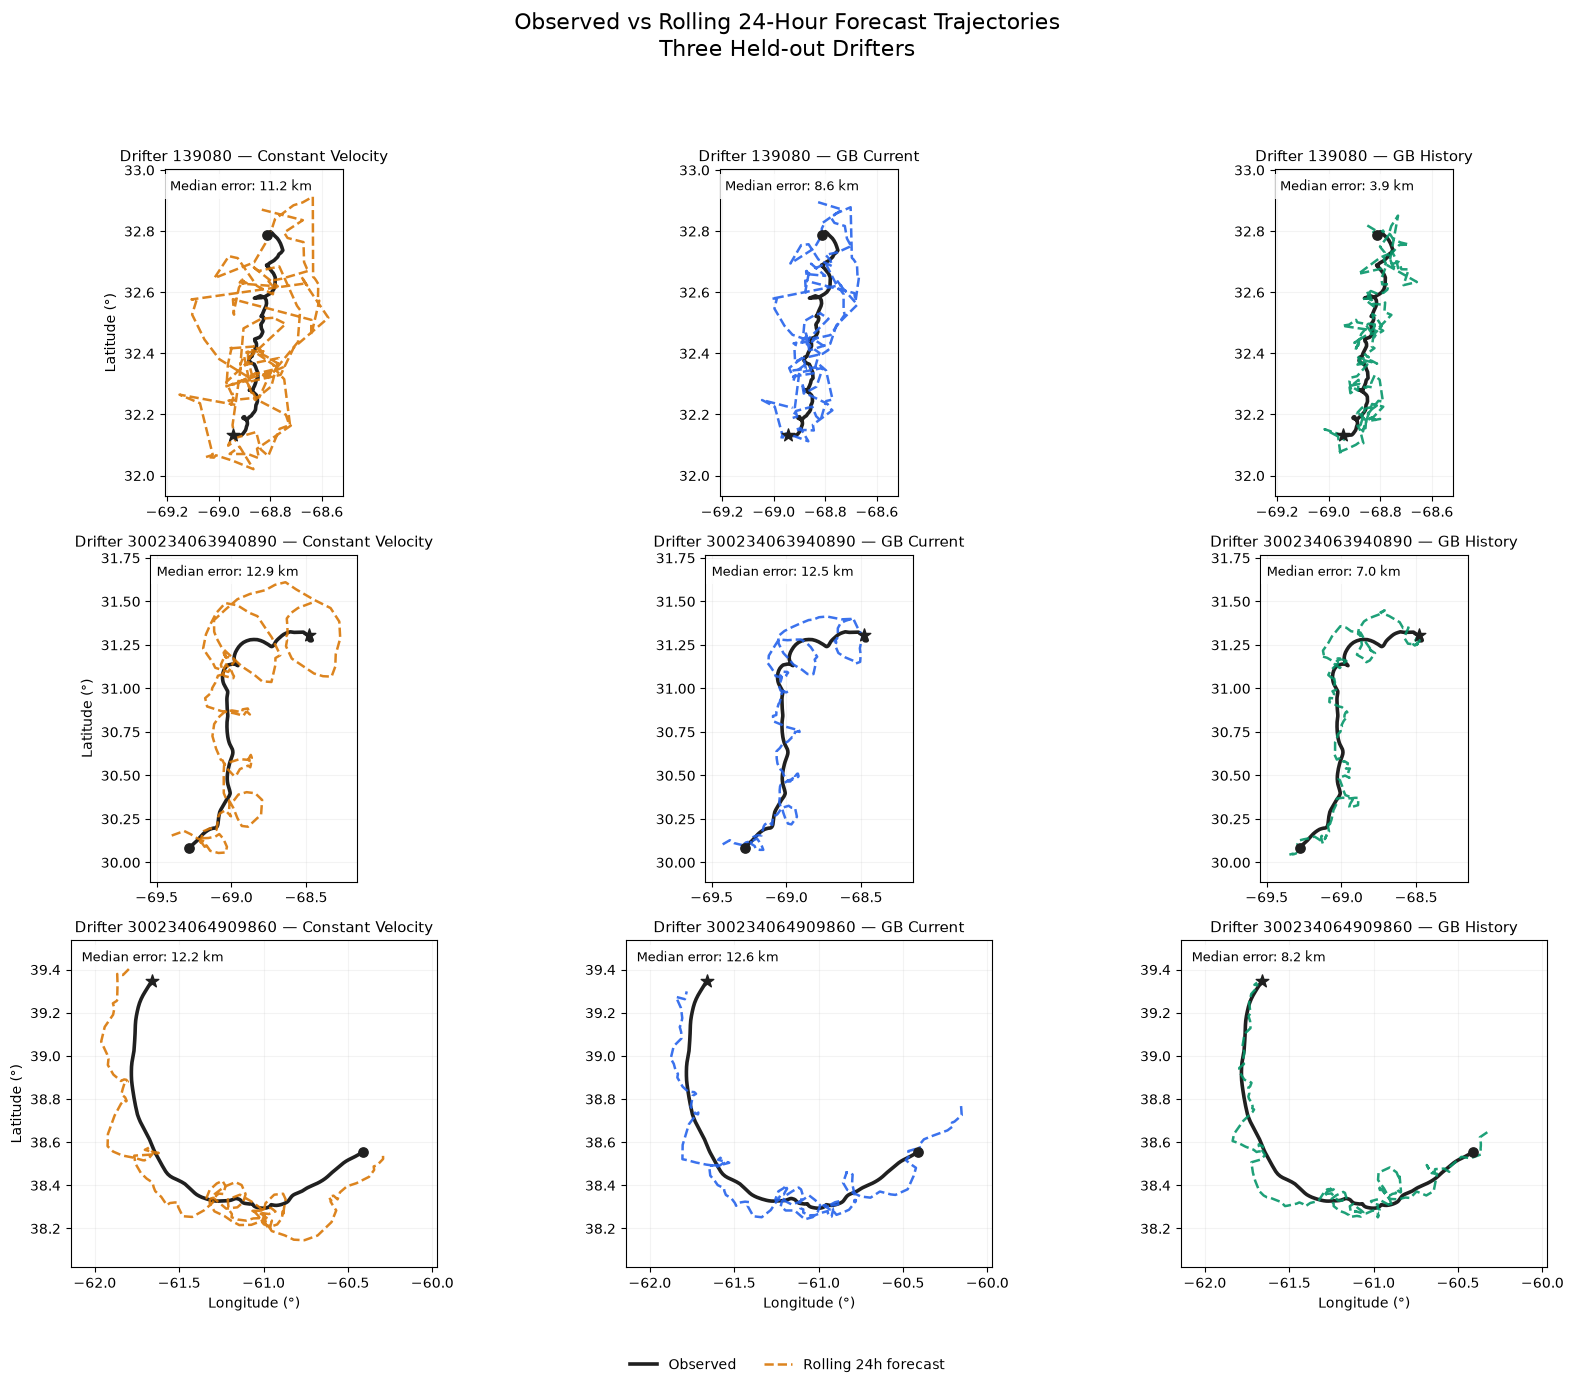

In [32]:

# Step 6.4 — Clear individual trajectory overlays

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plot_data = test_predictions.copy()
plot_data["time"] = pd.to_datetime(plot_data["time"], utc=True)
plot_data["target_time"] = (
    plot_data["time"] + pd.Timedelta(hours=24)
)

# Select three drifters by observation coverage
drifter_counts = (
    plot_data.groupby("trajectory_id")
    .size()
    .sort_values(ascending=False)
)

selected_ids = drifter_counts.head(3).index.tolist()

models_to_compare = [
    "Constant Velocity",
    "GB Current",
    "GB History"
]

colors = {
    "Constant Velocity": "#D97706",
    "GB Current": "#2563EB",
    "GB History": "#059669"
}

fig, axes = plt.subplots(
    3, 3,
    figsize=(17, 14)
)

for row_idx, drifter_id in enumerate(selected_ids):

    track = plot_data.loc[
        plot_data["trajectory_id"] == drifter_id
    ].sort_values("target_time").copy()

    # Find contiguous hourly segments
    track["segment_id"] = (
        track["target_time"]
        .diff()
        .dt.total_seconds()
        .fillna(3600)
        .gt(3600)
        .cumsum()
    )

    # Choose longest continuous segment
    segment_id = (
        track.groupby("segment_id")
        .size()
        .idxmax()
    )

    segment = track.loc[
        track["segment_id"] == segment_id
    ].copy()

    # Limit to a 7-day window
    segment = segment.head(7 * 24)

    for col_idx, model_name in enumerate(models_to_compare):

        ax = axes[row_idx, col_idx]

        ax.plot(
            segment["lon_target"],
            segment["lat_target"],
            color="#202020",
            linewidth=2.6,
            label="Observed",
            zorder=3
        )

        ax.plot(
            segment[f"{model_name}_lon"],
            segment[f"{model_name}_lat"],
            color=colors[model_name],
            linewidth=1.8,
            linestyle="--",
            alpha=0.9,
            label="Rolling 24h forecast",
            zorder=4
        )

        ax.scatter(
            segment["lon_target"].iloc[0],
            segment["lat_target"].iloc[0],
            color="#202020",
            s=45,
            marker="o",
            zorder=5
        )

        ax.scatter(
            segment["lon_target"].iloc[-1],
            segment["lat_target"].iloc[-1],
            color="#202020",
            s=90,
            marker="*",
            zorder=5
        )

        # Consistent extent within each drifter row
        all_lon = np.concatenate([
            segment["lon_target"].to_numpy(),
            *[
                segment[f"{name}_lon"].to_numpy()
                for name in models_to_compare
            ]
        ])

        all_lat = np.concatenate([
            segment["lat_target"].to_numpy(),
            *[
                segment[f"{name}_lat"].to_numpy()
                for name in models_to_compare
            ]
        ])

        lon_margin = max(np.ptp(all_lon) * 0.1, 0.05)
        lat_margin = max(np.ptp(all_lat) * 0.1, 0.05)

        ax.set_xlim(
            all_lon.min() - lon_margin,
            all_lon.max() + lon_margin
        )

        ax.set_ylim(
            all_lat.min() - lat_margin,
            all_lat.max() + lat_margin
        )

        ax.set_aspect(
            1 / np.cos(np.radians(segment["lat_target"].mean())),
            adjustable="box"
        )

        ax.set_title(
            f"Drifter {drifter_id} — {model_name}",
            fontsize=11
        )

        ax.grid(alpha=0.15)

        if col_idx == 0:
            ax.set_ylabel("Latitude (°)")

        if row_idx == 2:
            ax.set_xlabel("Longitude (°)")

        # Window-specific median error
        median_error = segment[f"{model_name}_error"].median()

        ax.text(
            0.03, 0.97,
            f"Median error: {median_error:.1f} km",
            transform=ax.transAxes,
            va="top",
            fontsize=9,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.8
            )
        )

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=2,
    frameon=False
)

fig.suptitle(
    "Observed vs Rolling 24-Hour Forecast Trajectories\n"
    "Three Held-out Drifters",
    fontsize=16
)

fig.tight_layout(rect=[0, 0.04, 1, 0.94])

fig.savefig(
    FIG_DIR / "report_individual_trajectory_overlays.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 6.3 Extended Trajectory Comparisons Across Model Families

To examine the spatial behaviour of different forecasting approaches, the rolling 24-hour predicted-endpoint tracks are compared across three groups: physical baselines and linear correction, linear versus nonlinear learning, and alternative tree ensembles.

Each figure uses the same three held-out drifters and seven-day observation windows. Observed trajectories are shown as solid black lines, while model predictions are shown as coloured dashed lines.

Geographic extents are fixed within each drifter across all figures to ensure that apparent differences are not caused by changes in map scale. Window-specific median great-circle errors are displayed alongside each model.

These visualisations provide qualitative evidence of trajectory alignment, local deviations, and forecast smoothness. Quantitative conclusions are based on the complete held-out test set rather than the selected illustrative tracks.


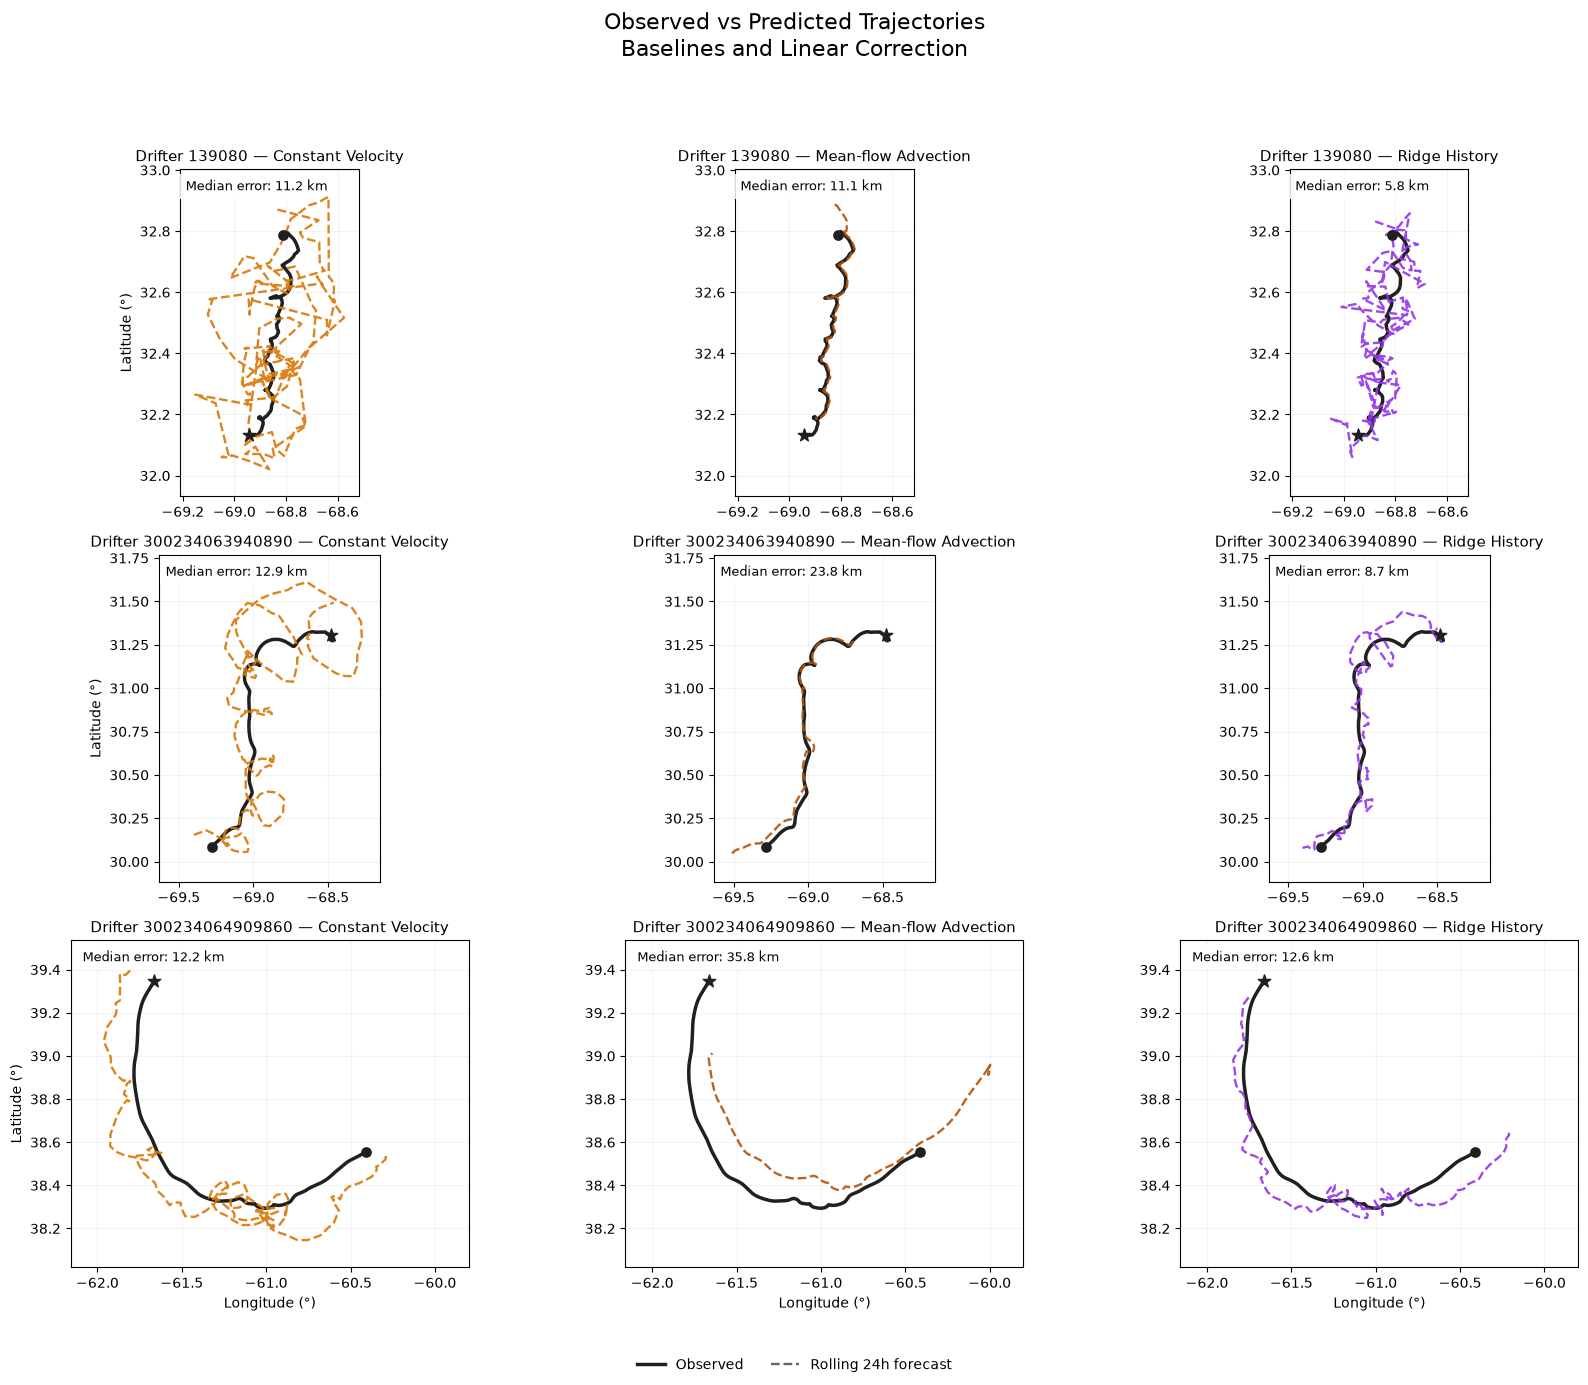

Saved: ../image/report_trajectory_baselines_and_linear_correction.png


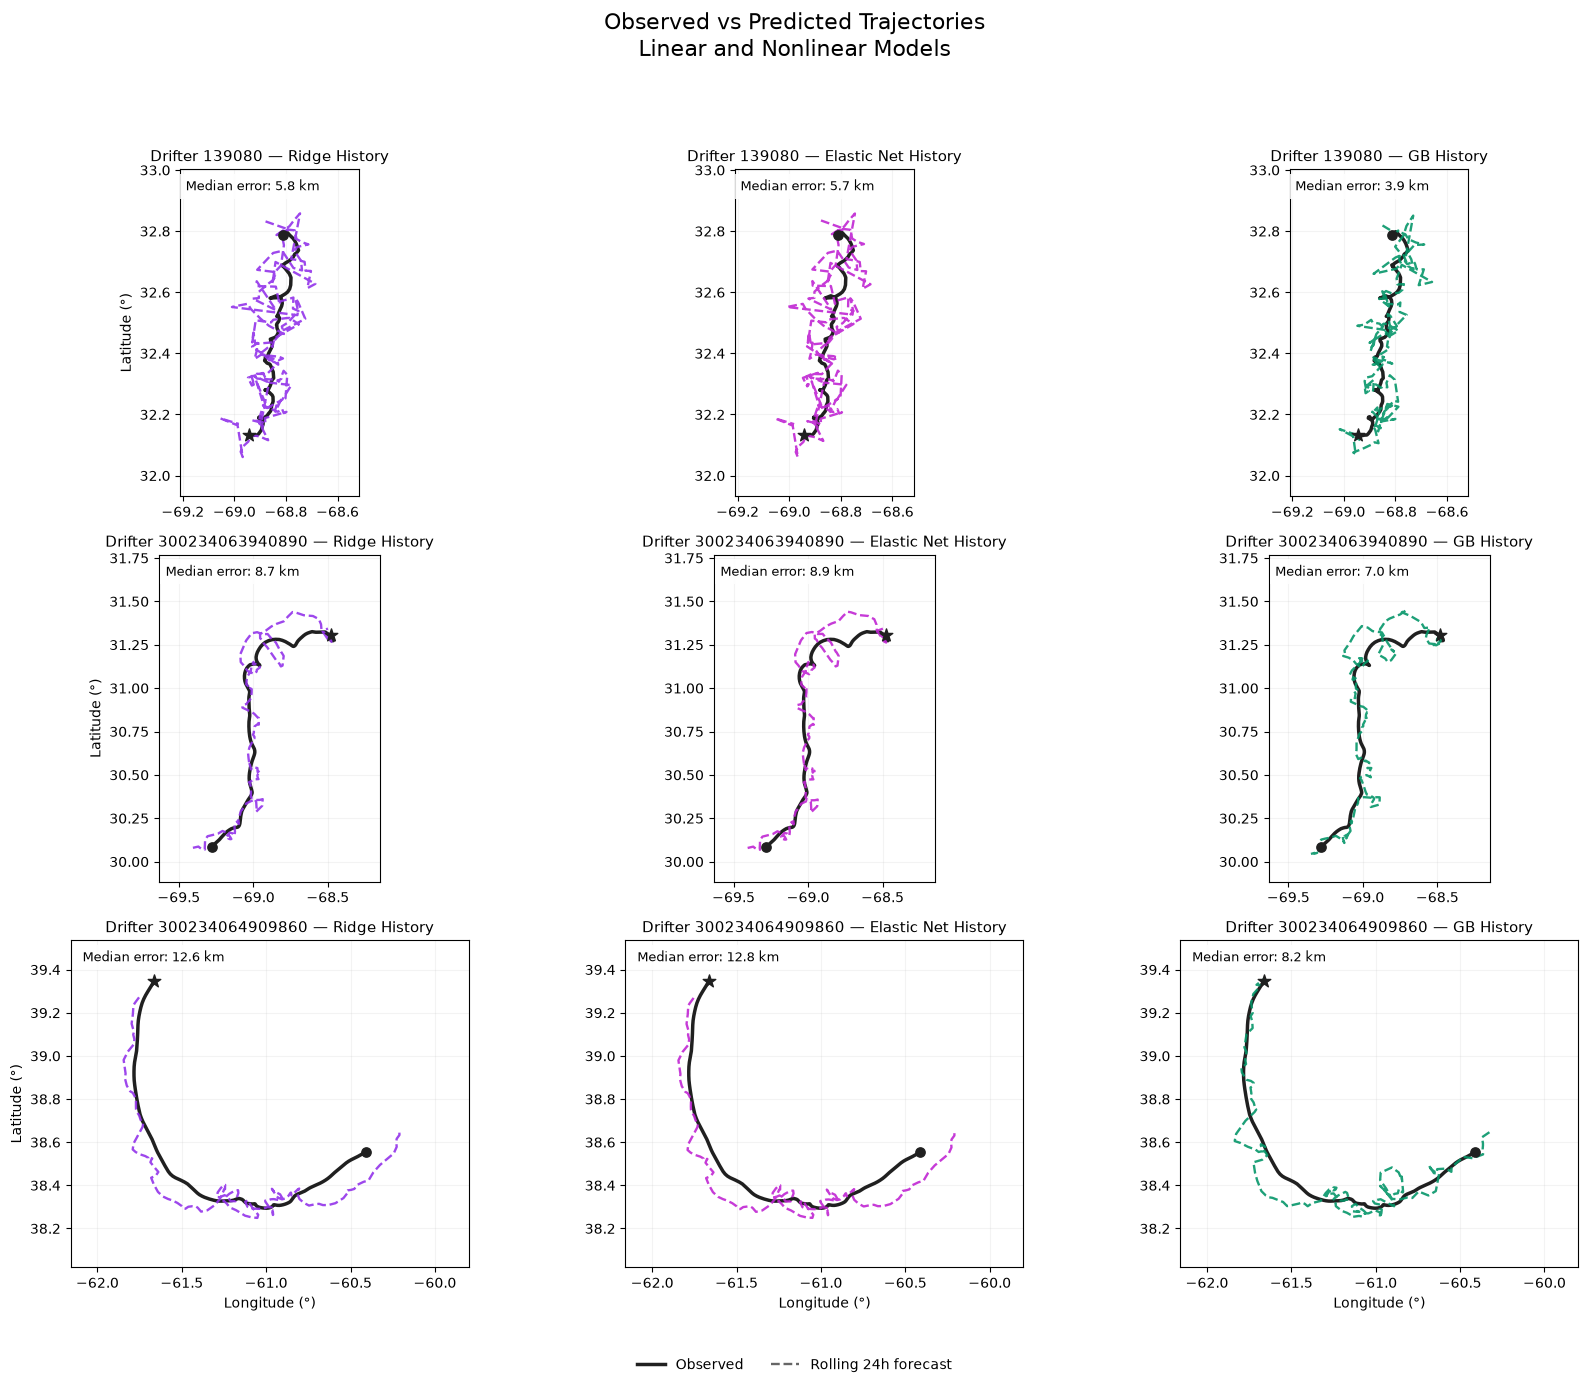

Saved: ../image/report_trajectory_linear_and_nonlinear_models.png


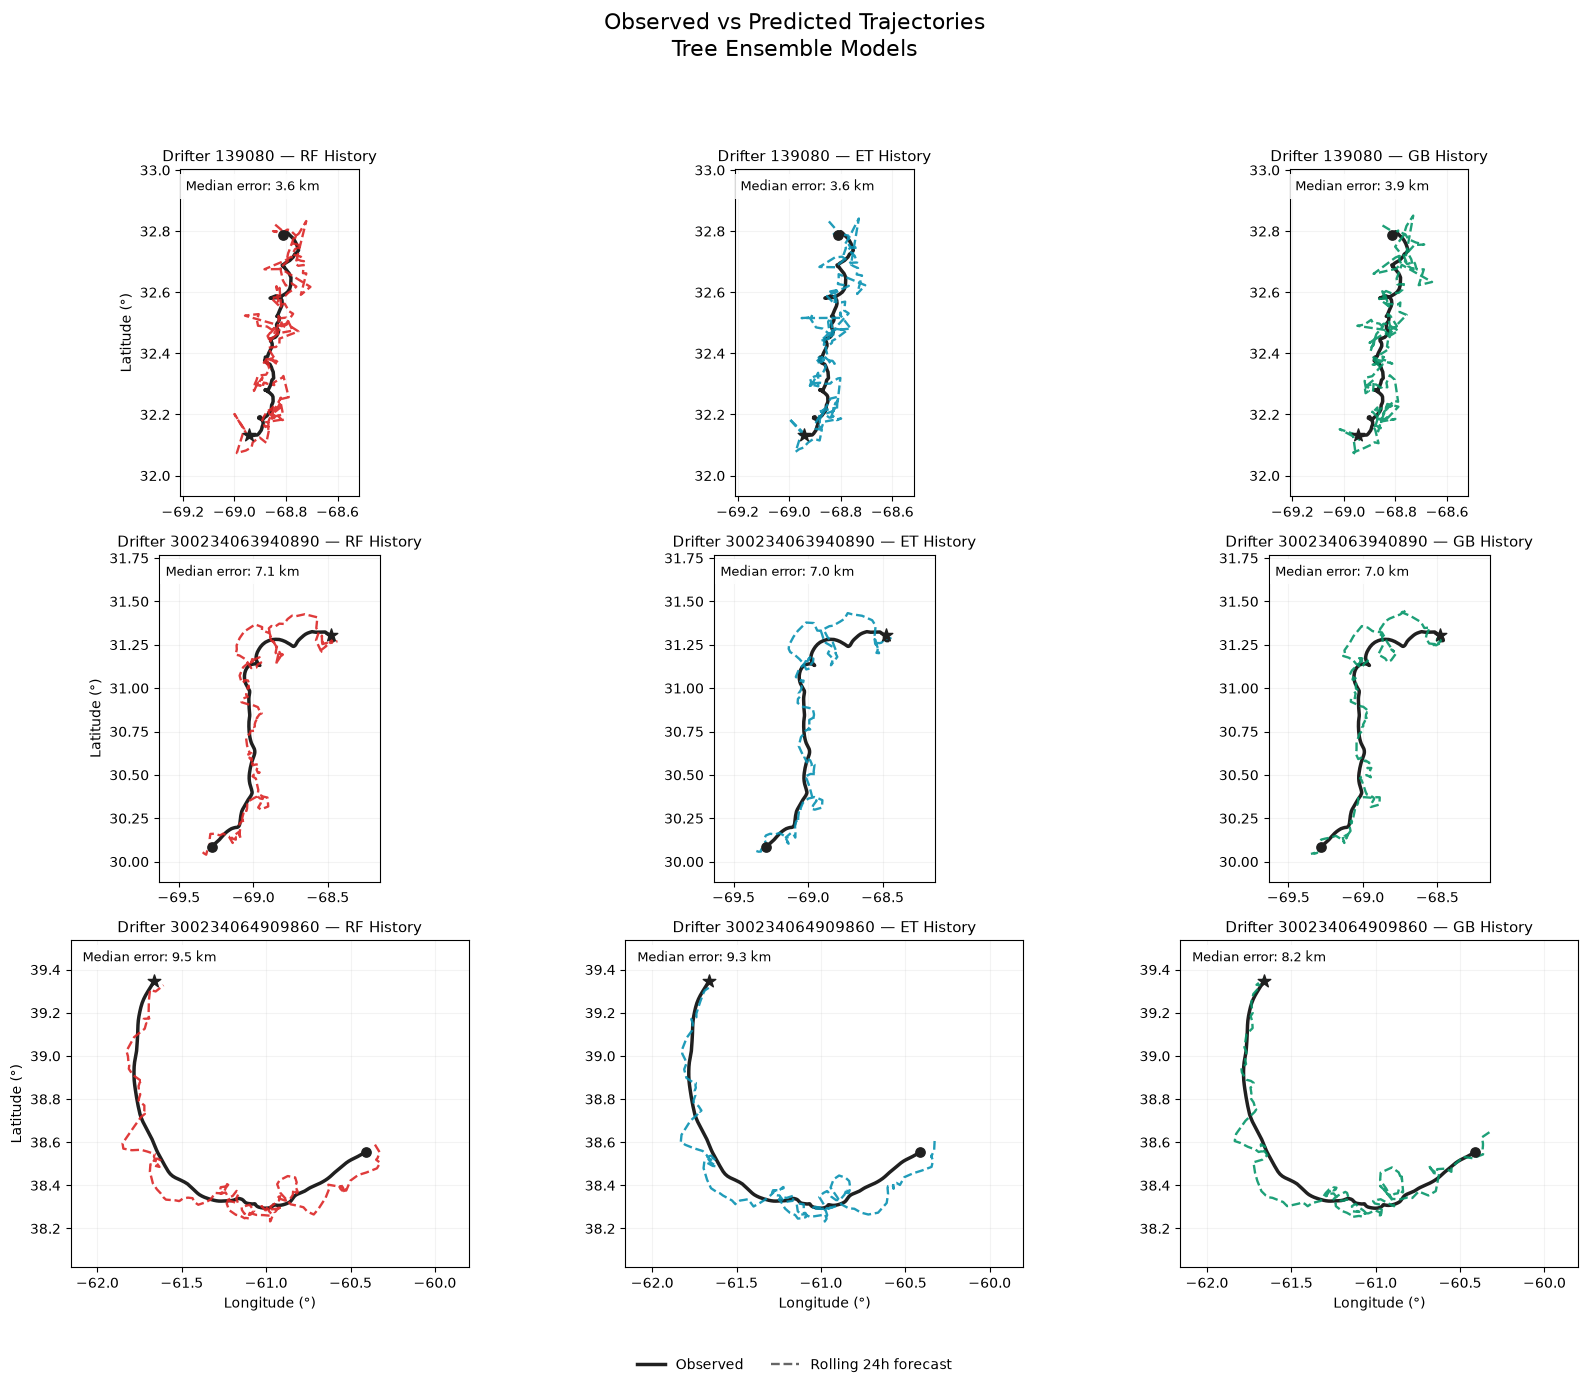

Saved: ../image/report_trajectory_tree_ensemble_models.png


In [33]:

# Step 6.5 — Extended trajectory comparison figures

from matplotlib.lines import Line2D

figure_groups = {
    "Baselines and Linear Correction": [
        "Constant Velocity",
        "Mean-flow Advection",
        "Ridge History"
    ],
    "Linear and Nonlinear Models": [
        "Ridge History",
        "Elastic Net History",
        "GB History"
    ],
    "Tree Ensemble Models": [
        "RF History",
        "ET History",
        "GB History"
    ]
}

model_colors = {
    "Constant Velocity": "#D97706",
    "Mean-flow Advection": "#B45309",
    "Ridge History": "#9333EA",
    "Elastic Net History": "#C026D3",
    "RF History": "#DC2626",
    "ET History": "#0891B2",
    "GB History": "#059669"
}

# Reuse the same three drifters and seven-day windows
selected_ids = (
    test_predictions
    .groupby("trajectory_id")
    .size()
    .sort_values(ascending=False)
    .head(3)
    .index
    .tolist()
)

plot_data = test_predictions.copy()
plot_data["time"] = pd.to_datetime(plot_data["time"], utc=True)
plot_data["target_time"] = (
    plot_data["time"] + pd.Timedelta(hours=24)
)

selected_tracks = {}

for drifter_id in selected_ids:

    track = plot_data.loc[
        plot_data["trajectory_id"] == drifter_id
    ].sort_values("target_time").copy()

    track["segment_id"] = (
        track["target_time"]
        .diff()
        .dt.total_seconds()
        .fillna(3600)
        .gt(3600)
        .cumsum()
    )

    longest_segment = (
        track.groupby("segment_id")
        .size()
        .idxmax()
    )

    selected_tracks[drifter_id] = (
        track.loc[track["segment_id"] == longest_segment]
        .head(7 * 24)
        .copy()
    )

# Use all displayed models to establish consistent axes
all_displayed_models = list({
    name
    for group in figure_groups.values()
    for name in group
})

track_extents = {}

for drifter_id, segment in selected_tracks.items():

    lon_arrays = [segment["lon_target"].to_numpy()]
    lat_arrays = [segment["lat_target"].to_numpy()]

    for name in all_displayed_models:
        lon_arrays.append(segment[f"{name}_lon"].to_numpy())
        lat_arrays.append(segment[f"{name}_lat"].to_numpy())

    all_lon = np.concatenate(lon_arrays)
    all_lat = np.concatenate(lat_arrays)

    lon_margin = max(np.ptp(all_lon) * 0.10, 0.05)
    lat_margin = max(np.ptp(all_lat) * 0.10, 0.05)

    track_extents[drifter_id] = (
        (all_lon.min() - lon_margin,
         all_lon.max() + lon_margin),
        (all_lat.min() - lat_margin,
         all_lat.max() + lat_margin)
    )

# Generate separate comparison figures
for figure_name, models in figure_groups.items():

    fig, axes = plt.subplots(
        3, 3,
        figsize=(17, 14)
    )

    for row_idx, drifter_id in enumerate(selected_ids):

        segment = selected_tracks[drifter_id]
        xlim, ylim = track_extents[drifter_id]

        for col_idx, model_name in enumerate(models):

            ax = axes[row_idx, col_idx]

            ax.plot(
                segment["lon_target"],
                segment["lat_target"],
                color="#202020",
                linewidth=2.5,
                label="Observed",
                zorder=3
            )

            ax.plot(
                segment[f"{model_name}_lon"],
                segment[f"{model_name}_lat"],
                color=model_colors[model_name],
                linewidth=1.7,
                linestyle="--",
                alpha=0.9,
                label="Rolling 24h forecast",
                zorder=4
            )

            ax.scatter(
                segment["lon_target"].iloc[0],
                segment["lat_target"].iloc[0],
                color="#202020",
                s=45,
                marker="o",
                zorder=5
            )

            ax.scatter(
                segment["lon_target"].iloc[-1],
                segment["lat_target"].iloc[-1],
                color="#202020",
                s=90,
                marker="*",
                zorder=5
            )

            ax.set_xlim(*xlim)
            ax.set_ylim(*ylim)

            ax.set_aspect(
                1 / np.cos(
                    np.radians(segment["lat_target"].mean())
                ),
                adjustable="box"
            )

            median_error = segment[
                f"{model_name}_error"
            ].median()

            ax.set_title(
                f"Drifter {drifter_id} — {model_name}",
                fontsize=11
            )

            ax.text(
                0.03, 0.97,
                f"Median error: {median_error:.1f} km",
                transform=ax.transAxes,
                va="top",
                fontsize=9,
                bbox=dict(
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.85
                )
            )

            ax.grid(alpha=0.15)

            if col_idx == 0:
                ax.set_ylabel("Latitude (°)")

            if row_idx == 2:
                ax.set_xlabel("Longitude (°)")

    legend_handles = [
        Line2D(
            [0], [0],
            color="#202020",
            lw=2.5,
            label="Observed"
        ),
        Line2D(
            [0], [0],
            color="#666666",
            lw=1.7,
            linestyle="--",
            label="Rolling 24h forecast"
        )
    ]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=2,
        frameon=False
    )

    fig.suptitle(
        f"Observed vs Predicted Trajectories\n{figure_name}",
        fontsize=16
    )

    fig.tight_layout(rect=[0, 0.04, 1, 0.94])

    filename = (
        "report_trajectory_"
        + figure_name.lower().replace(" ", "_")
        + ".png"
    )

    fig.savefig(
        FIG_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", FIG_DIR / filename)


### 6.4 Interpretation of Trajectory Visualisations

The trajectory overlays provide a spatial interpretation of the forecasting results by comparing observed drifter positions with rolling 24-hour predicted endpoints across three held-out trajectories.

**Physical baselines and linear models.** Constant Velocity exhibits noticeable deviations from the observed trajectories, particularly in regions involving changes in direction or irregular motion. Mean-flow Advection shows mixed performance: it closely follows the first illustrated trajectory but produces substantial errors in the other two cases, highlighting the limitations of spatially averaged flow estimates. Ridge Regression generally improves trajectory alignment, although local oscillations and directional deviations remain visible.

**Linear versus nonlinear models.** Ridge and Elastic Net produce nearly identical predicted tracks, consistent with their similar quantitative performance. In contrast, Gradient Boosting with historical features follows the observed trajectories more closely, particularly around bends and changes in movement direction. This suggests that nonlinear modelling can better exploit relationships among historical motion descriptors that are not fully captured by linear corrections.

**Tree ensemble comparisons.** Random Forest, Extra Trees and Gradient Boosting all achieve relatively close alignment with the observed trajectories. Their predictions capture the broad spatial structure of the selected drifter movements, with comparatively small differences between the three methods. This visual similarity is consistent with their closely matched overall test errors, suggesting that the benefits of nonlinear tree ensembles are not restricted to a particular algorithm.

Across the three figures, the strongest qualitative improvement is generally observed when moving from physical or linear forecasting approaches to history-enhanced nonlinear models. However, even the best-performing methods exhibit local fluctuations and occasional deviations, indicating that accurate 24-hour endpoint prediction does not necessarily imply smooth temporal consistency across successive forecasts.

Importantly, the displayed predicted tracks are constructed from independently issued rolling 24-hour forecasts, rather than recursively simulated trajectories. The three drifters are illustrative examples selected by observation coverage, and their performance should not be interpreted as representative of all test trajectories.

**Overall, these visualisations complement the quantitative test results by demonstrating how historical motion information and nonlinear modelling improve geographic trajectory alignment, while also revealing remaining limitations in local forecast consistency.**


## 7. Motion-Conditioned Forecast Evaluation

### 7.1 Definition of Motion Regimes

To investigate the relationship between recent motion characteristics and forecast difficulty, test forecasts are stratified by three descriptors computed exclusively from the preceding 24-hour observation window:

- **Mean speed (m/s):** Average velocity magnitude over the input window.
- **Mean acceleration magnitude (m/s²):** Average magnitude of consecutive hourly velocity changes divided by the elapsed time.
- **Mean turning rate (degrees/hour):** Average absolute change in heading per hour, excluding unreliable headings at low speeds.

For each descriptor, the 33rd and 67th percentile thresholds are estimated from the training partition. These fixed thresholds are subsequently applied to the held-out test partition to define Low, Medium and High motion regimes.

Forecasts with undefined turning rates are retained in a separate category rather than assigned an artificial turning value.

The resulting group sizes and numbers of distinct drifters are reported before comparing forecast errors. All subsequent motion-conditioned comparisons use the same held-out forecasts across methods.


In [34]:

# Step 7.1 — Define motion regimes using training-set tertiles

motion_descriptors = {
    "Speed": "mean_speed",
    "Acceleration": "mean_acceleration",
    "Turning": "mean_turning"
}

regime_labels = ["Low", "Medium", "High"]

train_data = modelling.loc[
    modelling["split"] == "train"
]

motion_thresholds = []
motion_group_counts = []

for descriptor, feature in motion_descriptors.items():

    # Estimate thresholds exclusively from training data
    q33, q67 = train_data[feature].dropna().quantile(
        [1/3, 2/3]
    )

    motion_thresholds.append({
        "Descriptor": descriptor,
        "Feature": feature,
        "Lower Threshold": q33,
        "Upper Threshold": q67
    })

    group_column = f"{descriptor}_group"

    # Apply the fixed thresholds to held-out test forecasts
    test_predictions[group_column] = pd.cut(
        test_predictions[feature],
        bins=[-np.inf, q33, q67, np.inf],
        labels=regime_labels,
        include_lowest=True
    )

    # Preserve undefined values as a separate category
    test_predictions[group_column] = (
        test_predictions[group_column]
        .cat.add_categories(["Undefined"])
        .fillna("Undefined")
    )

    counts = (
        test_predictions
        .groupby(group_column, observed=True)
        .agg(
            Samples=("trajectory_id", "size"),
            Drifters=("trajectory_id", "nunique")
        )
        .reset_index()
    )

    counts.insert(0, "Descriptor", descriptor)

    counts = counts.rename(
        columns={group_column: "Group"}
    )

    motion_group_counts.append(counts)

motion_thresholds = pd.DataFrame(motion_thresholds)

motion_group_counts = pd.concat(
    motion_group_counts,
    ignore_index=True
)

print("Training-defined motion thresholds:")
display(motion_thresholds)

print("Test-set motion regime coverage:")
display(motion_group_counts)

# Save results for reproducibility
motion_thresholds.to_csv(
    MODEL_DIR / "motion_group_thresholds.csv",
    index=False
)

motion_group_counts.to_csv(
    MODEL_DIR / "motion_group_counts.csv",
    index=False
)

test_predictions.to_parquet(
    DATA_DIR / "report_test_predictions.parquet",
    index=False
)


Training-defined motion thresholds:


,Descriptor,Feature,Lower Threshold,Upper Threshold
0,Speed,mean_speed,0.238686,0.398547
1,Acceleration,mean_acceleration,0.000015,0.000023
2,Turning,mean_turning,6.695738,13.984027


Test-set motion regime coverage:


,Descriptor,Group,Samples,Drifters
0,Speed,Low,24510,62
1,Speed,Medium,24046,69
2,Speed,High,33990,73
3,Acceleration,Low,23198,71
4,Acceleration,Medium,27627,77
5,Acceleration,High,31721,73
6,Turning,Low,30570,73
7,Turning,Medium,24432,72
8,Turning,High,27531,66
9,Turning,Undefined,13,1



### 7.2 Forecast Error Across Motion Regimes

Forecast difficulty is evaluated by comparing 24-hour great-circle position errors across training-defined speed, acceleration and turning regimes.

Six representative forecasting methods are considered: Constant Velocity, Mean-flow Advection, Ridge History, GB Current, RF History and GB History. These methods span physical baselines, regularised linear correction, and nonlinear tree ensembles.

For each motion regime, median and 90th-percentile forecast errors are calculated using the held-out test predictions. Median errors characterise typical forecast accuracy, while 90th-percentile errors describe the upper tail of the error distribution.

The analysis examines whether forecast difficulty increases monotonically with motion intensity and whether the relative performance of forecasting methods changes across regimes.

Because motion characteristics may be correlated and multiple forecasts originate from the same drifter, these comparisons are interpreted as descriptive associations rather than causal effects.


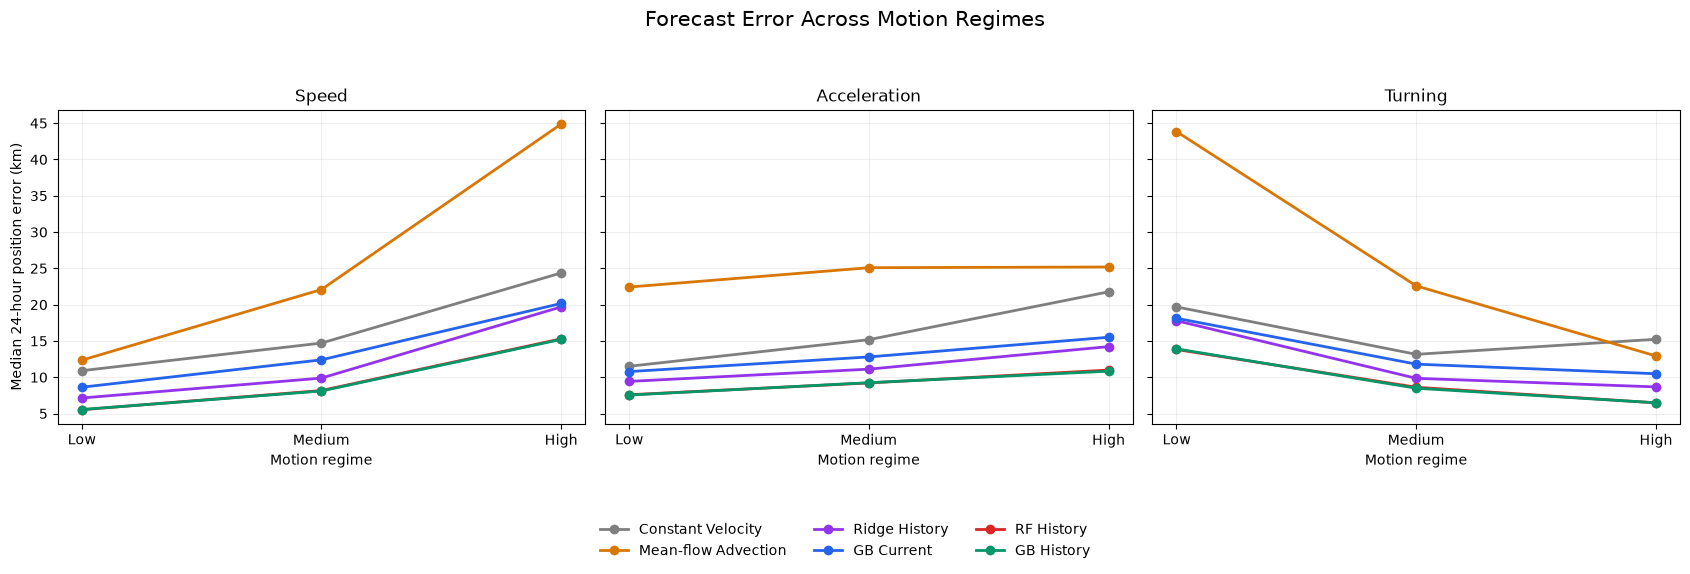

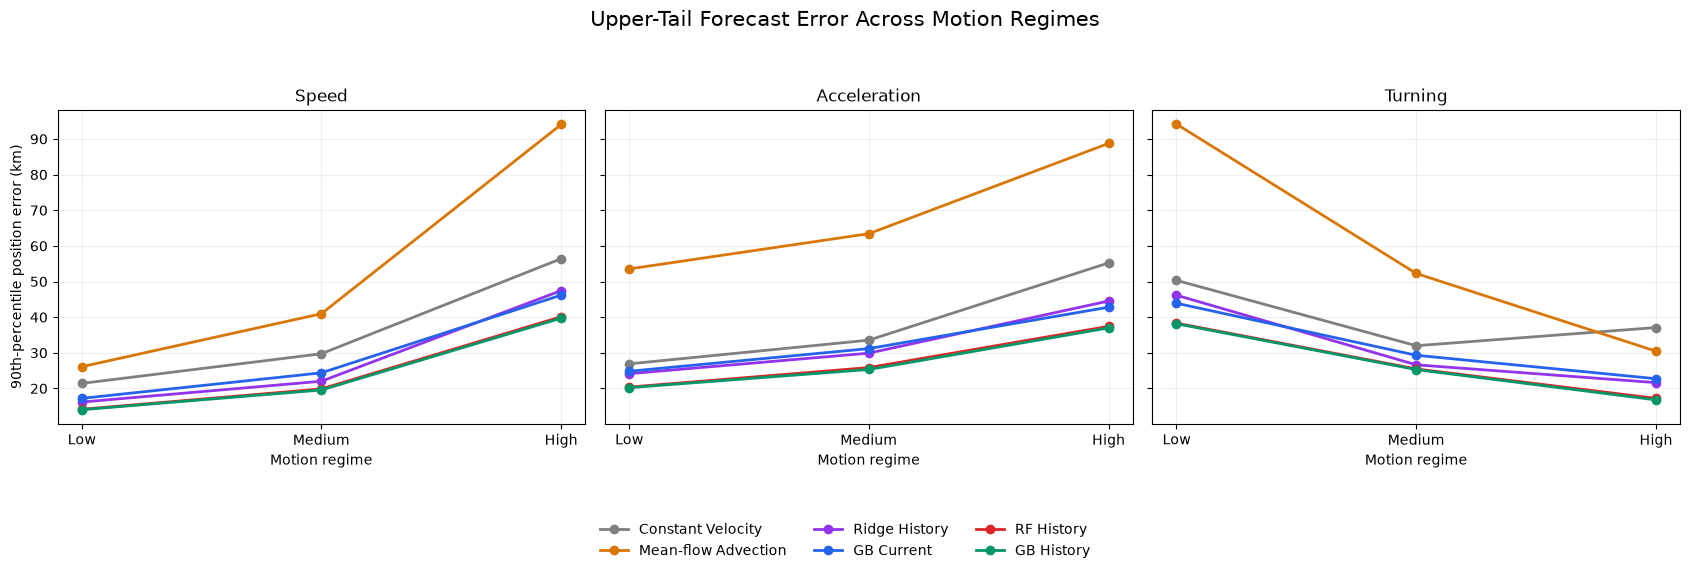

Model,Descriptor,Regime,Constant Velocity,GB History,GB Improvement (%)
0,Acceleration,High,21.769,10.836,50.224
1,Acceleration,Low,11.509,7.545,34.447
2,Acceleration,Medium,15.173,9.248,39.051
3,Speed,High,24.370,15.213,37.574
4,Speed,Low,10.903,5.545,49.140
5,Speed,Medium,14.707,8.104,44.895
6,Turning,High,15.231,6.479,57.461
7,Turning,Low,19.693,13.912,29.353
8,Turning,Medium,13.155,8.488,35.478


In [35]:

# Step 7.2 — Motion-conditioned forecast error profiles

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

selected_models = [
    "Constant Velocity",
    "Mean-flow Advection",
    "Ridge History",
    "GB Current",
    "RF History",
    "GB History"
]

model_colors = {
    "Constant Velocity": "#7F7F7F",
    "Mean-flow Advection": "#D97706",
    "Ridge History": "#9333EA",
    "GB Current": "#2563EB",
    "RF History": "#DC2626",
    "GB History": "#059669"
}

regime_order = ["Low", "Medium", "High"]

motion_error_rows = []

for descriptor in motion_descriptors:

    group_col = f"{descriptor}_group"

    for regime in regime_order:

        subset = test_predictions.loc[
            test_predictions[group_col] == regime
        ]

        for model_name in selected_models:

            errors = subset[
                f"{model_name}_error"
            ].to_numpy()

            motion_error_rows.append({
                "Descriptor": descriptor,
                "Regime": regime,
                "Model": model_name,
                "Samples": len(errors),
                "Drifters": subset["trajectory_id"].nunique(),
                "Mean": np.mean(errors),
                "Median": np.median(errors),
                "P90": np.quantile(errors, 0.90),
                "RMSE": np.sqrt(np.mean(errors ** 2))
            })

motion_errors = pd.DataFrame(motion_error_rows)

# Save complete results
motion_errors.to_csv(
    MODEL_DIR / "motion_conditioned_test_errors.csv",
    index=False
)

# Figure 1: Median error profiles
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5.5),
    sharey=True
)

for ax, descriptor in zip(
    axes, motion_descriptors
):

    subset = motion_errors.loc[
        motion_errors["Descriptor"] == descriptor
    ]

    for model_name in selected_models:

        values = (
            subset.loc[subset["Model"] == model_name]
            .set_index("Regime")
            .reindex(regime_order)
        )

        ax.plot(
            regime_order,
            values["Median"],
            marker="o",
            linewidth=2,
            markersize=6,
            color=model_colors[model_name],
            label=model_name
        )

    ax.set_title(descriptor)
    ax.set_xlabel("Motion regime")
    ax.grid(alpha=0.2)

axes[0].set_ylabel(
    "Median 24-hour position error (km)"
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, -0.04)
)

fig.suptitle(
    "Forecast Error Across Motion Regimes",
    fontsize=15
)

fig.tight_layout(rect=[0, 0.12, 1, 0.93])

fig.savefig(
    FIG_DIR / "report_motion_regime_median_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Figure 2: 90th-percentile error profiles
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5.5),
    sharey=True
)

for ax, descriptor in zip(
    axes, motion_descriptors
):

    subset = motion_errors.loc[
        motion_errors["Descriptor"] == descriptor
    ]

    for model_name in selected_models:

        values = (
            subset.loc[subset["Model"] == model_name]
            .set_index("Regime")
            .reindex(regime_order)
        )

        ax.plot(
            regime_order,
            values["P90"],
            marker="o",
            linewidth=2,
            markersize=6,
            color=model_colors[model_name],
            label=model_name
        )

    ax.set_title(descriptor)
    ax.set_xlabel("Motion regime")
    ax.grid(alpha=0.2)

axes[0].set_ylabel(
    "90th-percentile position error (km)"
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, -0.04)
)

fig.suptitle(
    "Upper-Tail Forecast Error Across Motion Regimes",
    fontsize=15
)

fig.tight_layout(rect=[0, 0.12, 1, 0.93])

fig.savefig(
    FIG_DIR / "report_motion_regime_p90_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Summary table: GB History vs Constant Velocity
summary = motion_errors.loc[
    motion_errors["Model"].isin([
        "Constant Velocity",
        "GB History"
    ])
].pivot(
    index=["Descriptor", "Regime"],
    columns="Model",
    values="Median"
).reset_index()

summary["GB Improvement (%)"] = (
    (
        summary["Constant Velocity"]
        - summary["GB History"]
    )
    / summary["Constant Velocity"]
    * 100
)

display(summary.round(3))



### 7.2.1 Interpretation of Motion-Conditioned Forecast Errors

The motion-conditioned evaluation reveals substantial differences in 24-hour forecasting difficulty across speed, acceleration and turning regimes.

**Speed.** Forecast errors increase consistently with mean speed across all evaluated methods. For GB History, the median error rises from 5.55 km in the low-speed regime to 15.21 km in the high-speed regime. The corresponding 90th-percentile errors also increase substantially, indicating that faster-moving drifters experience both greater typical errors and more pronounced extreme deviations. Although GB History outperforms Constant Velocity across all speed regimes, its relative median-error reduction decreases from 49.1% at low speed to 37.6% at high speed.

**Acceleration.** Higher acceleration is also associated with increasing forecast error. GB History median errors rise from 7.55 km to 10.84 km between the low- and high-acceleration regimes. However, the relative improvement over Constant Velocity increases from 34.4% to 50.2%, suggesting that learned motion corrections become particularly valuable when recent velocities are changing rapidly. This pattern is consistent with the limitations of assuming constant velocity over a 24-hour forecast horizon.

**Turning.** Contrary to a simple expectation that more frequent directional changes necessarily make forecasting more difficult, higher mean turning rates are associated with lower position errors. GB History median error decreases from 13.91 km in the low-turning regime to 6.48 km in the high-turning regime. Similar patterns appear across the other forecasting methods. One possible explanation is that high turning rates coincide with slower motion or smaller net displacements, reducing absolute endpoint errors despite greater directional variability. This hypothesis requires further examination of the joint relationship between speed and turning.

**Model comparison.** History-enhanced tree ensembles consistently achieve the lowest or near-lowest errors across motion regimes. Their advantage is particularly apparent in high-acceleration conditions, while the magnitude of improvement varies considerably across speed and turning categories. The 90th-percentile results broadly reinforce the median-error findings, indicating that these patterns extend beyond typical forecasts.

Overall, the results suggest that forecasting difficulty depends not only on the complexity of recent motion but also on its magnitude and persistence. These associations motivate a joint speed–turning analysis to distinguish potentially overlapping effects.


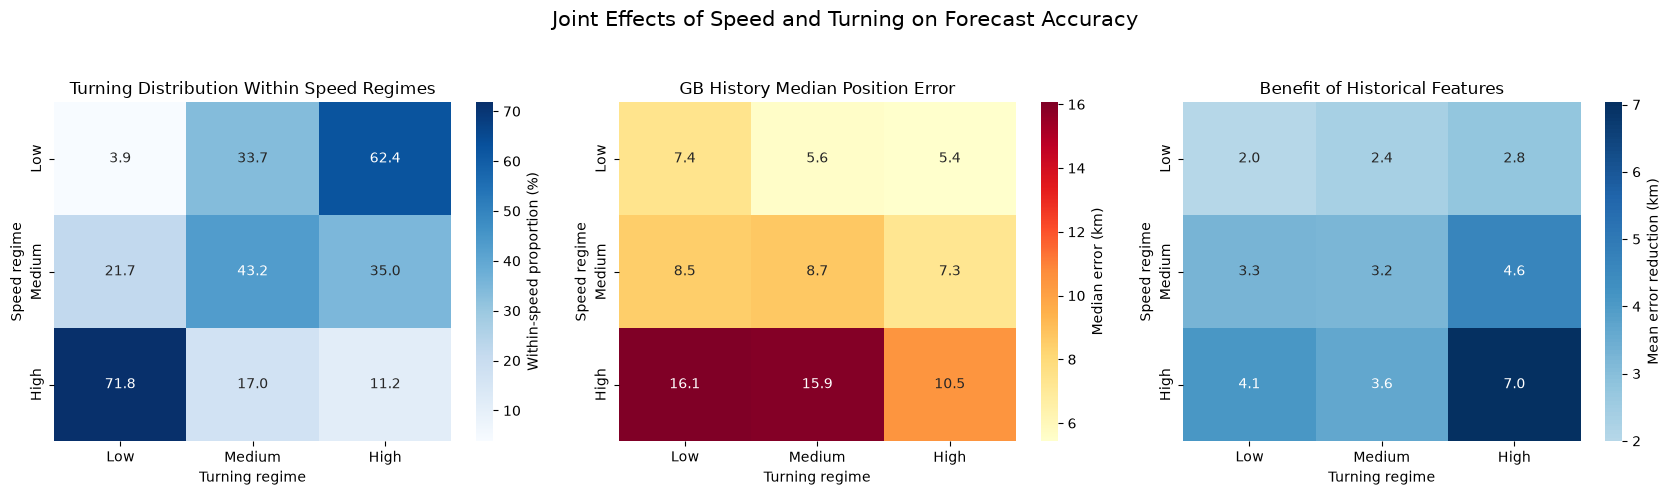

Joint sample counts:


Turning_group,Low,Medium,High
Speed_group,,,
Low,946,8263,15288
Medium,5225,10394,8427
High,24399,5775,3816


GB History median errors:


Turning_group,Low,Medium,High
Speed_group,,,
Low,7.36,5.57,5.44
Medium,8.48,8.68,7.26
High,16.06,15.94,10.47


Mean benefit of history (GB Current − GB History):


Turning_group,Low,Medium,High
Speed_group,,,
Low,2.00,2.36,2.76
Medium,3.26,3.23,4.65
High,4.11,3.63,7.03


In [36]:

# Step 7.3 — Joint speed-turning analysis

import seaborn as sns
import matplotlib.pyplot as plt

regime_order = ["Low", "Medium", "High"]

joint_data = test_predictions.loc[
    test_predictions["Turning_group"] != "Undefined"
].copy()

# 1. Joint sample distribution
joint_counts = pd.crosstab(
    joint_data["Speed_group"],
    joint_data["Turning_group"]
).reindex(
    index=regime_order,
    columns=regime_order,
    fill_value=0
)

# Row percentages: turning distribution conditional on speed
joint_percent = (
    joint_counts.div(joint_counts.sum(axis=1), axis=0) * 100
)

# 2. GB History median error within each joint regime
joint_error = (
    joint_data.groupby(
        ["Speed_group", "Turning_group"],
        observed=True
    )["GB History_error"]
    .median()
    .unstack()
    .reindex(index=regime_order, columns=regime_order)
)

# 3. Relative improvement of GB History vs GB Current
joint_improvement = joint_data.assign(
    history_gain_km=(
        joint_data["GB Current_error"]
        - joint_data["GB History_error"]
    )
).groupby(
    ["Speed_group", "Turning_group"],
    observed=True
)["history_gain_km"].mean().unstack().reindex(
    index=regime_order,
    columns=regime_order
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.heatmap(
    joint_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    ax=axes[0],
    cbar_kws={"label": "Within-speed proportion (%)"}
)
axes[0].set_title("Turning Distribution Within Speed Regimes")

sns.heatmap(
    joint_error,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    ax=axes[1],
    cbar_kws={"label": "Median error (km)"}
)
axes[1].set_title("GB History Median Position Error")

sns.heatmap(
    joint_improvement,
    annot=True,
    fmt=".1f",
    cmap="RdBu",
    center=0,
    ax=axes[2],
    cbar_kws={"label": "Mean error reduction (km)"}
)
axes[2].set_title("Benefit of Historical Features")

for ax in axes:
    ax.set_xlabel("Turning regime")
    ax.set_ylabel("Speed regime")

fig.suptitle(
    "Joint Effects of Speed and Turning on Forecast Accuracy",
    fontsize=15
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

fig.savefig(
    FIG_DIR / "report_joint_speed_turning_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Joint sample counts:")
display(joint_counts)

print("GB History median errors:")
display(joint_error.round(2))

print("Mean benefit of history (GB Current − GB History):")
display(joint_improvement.round(2))



### 7.3 Joint Effects of Speed and Turning

The joint speed–turning analysis reveals a pronounced association between the two motion descriptors. Among low-speed forecasts, 62.4% belong to the high-turning regime, whereas 71.8% of high-speed forecasts belong to the low-turning regime. This imbalance suggests that the lower errors observed in high-turning conditions may partly reflect differences in movement speed.

However, the inverse relationship between turning rate and forecast error persists within the broad speed categories. For GB History, median errors in the high-speed regime decrease from 16.06 km under low turning to 10.47 km under high turning. Similar, although smaller, differences occur in the low- and medium-speed regimes. Thus, differences in speed-regime composition do not fully account for the observed turning–error association.

The benefit of historical information also varies across joint motion conditions. Measured as the mean paired error reduction between GB Current and GB History, the improvement ranges from 2.00 km in low-speed, low-turning conditions to 7.03 km in high-speed, high-turning conditions. This indicates that historical motion descriptors provide particularly substantial absolute improvements for forecasts involving both rapid movement and frequent directional changes.

These findings suggest that forecast difficulty is influenced by interacting motion characteristics rather than by speed or turning alone. Nevertheless, the analysis remains descriptive: the speed categories are broad, additional motion properties may confound the associations, and observations from the same drifter are temporally dependent. The results therefore motivate uncertainty assessment using drifter-level resampling.


Overall mean history gain: 3.652 km
95% cluster-bootstrap CI: [3.141, 4.141] km


,Regime,Mean Gain (km),CI Lower,CI Upper,Samples,Drifters
0,Low Speed / Low Turning,1.997,1.237,2.709,946,38
1,Low Speed / Medium Turning,2.363,1.930,2.739,8263,55
2,Low Speed / High Turning,2.764,2.308,3.125,15288,57
3,Medium Speed / Low Turning,3.261,2.673,3.745,5225,54
4,Medium Speed / Medium Turning,3.227,2.719,3.680,10394,65
5,Medium Speed / High Turning,4.648,3.861,5.329,8427,59
6,High Speed / Low Turning,4.106,2.941,5.315,24399,65
7,High Speed / Medium Turning,3.630,2.518,4.674,5775,65
8,High Speed / High Turning,7.032,5.380,9.169,3816,44


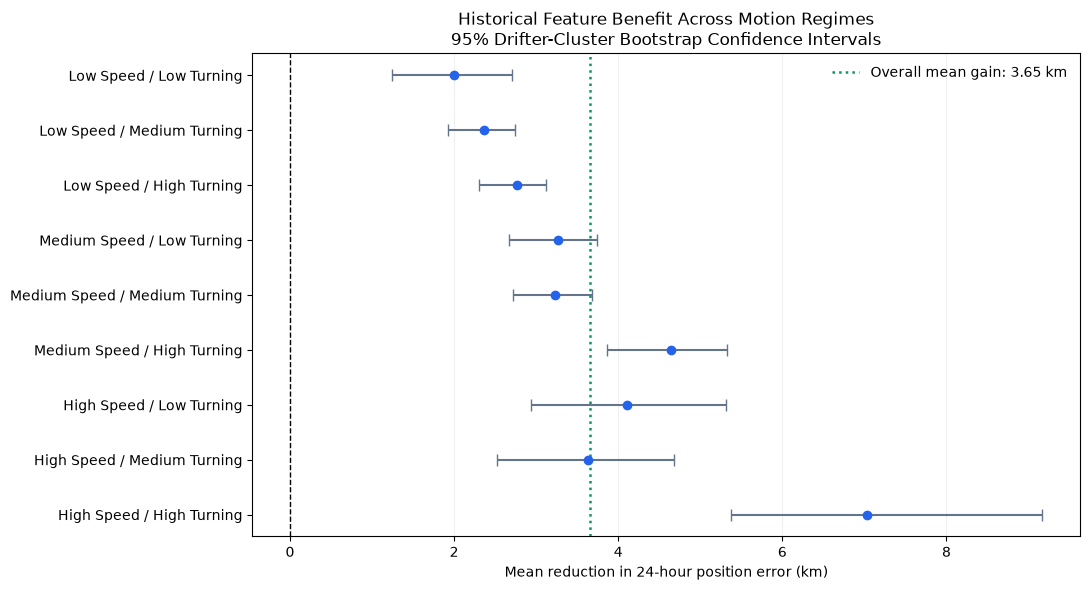

In [37]:

# Step 7.4 — Drifter-level cluster bootstrap
# Paired GB Current vs GB History error reduction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
N_BOOT = 2000

bootstrap_data = test_predictions.loc[
    test_predictions["Turning_group"] != "Undefined",
    [
        "trajectory_id",
        "Speed_group",
        "Turning_group",
        "GB Current_error",
        "GB History_error"
    ]
].copy()

bootstrap_data["history_gain"] = (
    bootstrap_data["GB Current_error"]
    - bootstrap_data["GB History_error"]
)

# Define nine joint regimes
regime_order = ["Low", "Medium", "High"]

joint_labels = [
    f"{speed} Speed / {turning} Turning"
    for speed in regime_order
    for turning in regime_order
]

bootstrap_data["joint_regime"] = (
    bootstrap_data["Speed_group"].astype(str)
    + " Speed / "
    + bootstrap_data["Turning_group"].astype(str)
    + " Turning"
)

# Aggregate by drifter and joint regime.
# This preserves the contribution of repeated forecasts
# while allowing efficient cluster resampling.
cluster_stats = (
    bootstrap_data
    .groupby(
        ["trajectory_id", "joint_regime"],
        observed=True
    )["history_gain"]
    .agg(["sum", "count"])
    .reset_index()
)

drifter_ids = bootstrap_data["trajectory_id"].unique()
n_drifters = len(drifter_ids)

sum_matrix = (
    cluster_stats.pivot(
        index="trajectory_id",
        columns="joint_regime",
        values="sum"
    )
    .reindex(
        index=drifter_ids,
        columns=joint_labels
    )
    .fillna(0)
    .to_numpy()
)

count_matrix = (
    cluster_stats.pivot(
        index="trajectory_id",
        columns="joint_regime",
        values="count"
    )
    .reindex(
        index=drifter_ids,
        columns=joint_labels
    )
    .fillna(0)
    .to_numpy()
)

# Point estimates
point_estimates = (
    sum_matrix.sum(axis=0)
    / count_matrix.sum(axis=0)
)

# Bootstrap sampling at the drifter level
bootstrap_estimates = np.full(
    (N_BOOT, len(joint_labels)),
    np.nan
)

overall_bootstrap = np.empty(N_BOOT)

drifter_total_sum = sum_matrix.sum(axis=1)
drifter_total_count = count_matrix.sum(axis=1)

for b in range(N_BOOT):

    sampled = rng.integers(
        0, n_drifters, size=n_drifters
    )

    sums = sum_matrix[sampled].sum(axis=0)
    counts = count_matrix[sampled].sum(axis=0)

    bootstrap_estimates[b] = np.divide(
        sums,
        counts,
        out=np.full(len(joint_labels), np.nan),
        where=counts > 0
    )

    overall_bootstrap[b] = (
        drifter_total_sum[sampled].sum()
        / drifter_total_count[sampled].sum()
    )

ci_lower = np.nanpercentile(
    bootstrap_estimates, 2.5, axis=0
)

ci_upper = np.nanpercentile(
    bootstrap_estimates, 97.5, axis=0
)

bootstrap_summary = pd.DataFrame({
    "Regime": joint_labels,
    "Mean Gain (km)": point_estimates,
    "CI Lower": ci_lower,
    "CI Upper": ci_upper,
    "Samples": count_matrix.sum(axis=0).astype(int),
    "Drifters": (count_matrix > 0).sum(axis=0)
})

overall_point = bootstrap_data["history_gain"].mean()

overall_ci = np.percentile(
    overall_bootstrap, [2.5, 97.5]
)

print(
    f"Overall mean history gain: {overall_point:.3f} km"
)

print(
    f"95% cluster-bootstrap CI: "
    f"[{overall_ci[0]:.3f}, {overall_ci[1]:.3f}] km"
)

display(bootstrap_summary.round(3))

bootstrap_summary.to_csv(
    MODEL_DIR / "history_gain_cluster_bootstrap.csv",
    index=False
)

# Plot confidence intervals
fig, ax = plt.subplots(figsize=(11, 6))

positions = np.arange(len(joint_labels))

ax.errorbar(
    bootstrap_summary["Mean Gain (km)"],
    positions,
    xerr=[
        bootstrap_summary["Mean Gain (km)"]
        - bootstrap_summary["CI Lower"],
        bootstrap_summary["CI Upper"]
        - bootstrap_summary["Mean Gain (km)"]
    ],
    fmt="o",
    color="#2563EB",
    ecolor="#64748B",
    capsize=4,
    markersize=6
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.axvline(
    overall_point,
    color="#059669",
    linestyle=":",
    linewidth=1.8,
    label=f"Overall mean gain: {overall_point:.2f} km"
)

ax.set_yticks(positions)
ax.set_yticklabels(joint_labels)
ax.invert_yaxis()

ax.set_xlabel(
    "Mean reduction in 24-hour position error (km)"
)

ax.set_title(
    "Historical Feature Benefit Across Motion Regimes\n"
    "95% Drifter-Cluster Bootstrap Confidence Intervals"
)

ax.grid(axis="x", alpha=0.2)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "report_history_gain_bootstrap_ci.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 7.4 Uncertainty in the Benefit of Historical Motion Features

To account for dependence among forecasts originating from the same drifter, uncertainty was estimated using a drifter-level cluster bootstrap with 2,000 resamples. Each bootstrap replicate sampled held-out drifters with replacement while retaining their associated forecast observations. Historical-feature benefit was defined as the paired reduction in great-circle position error between GB Current and GB History.

Across the test forecasts with defined turning rates, incorporating historical features reduced mean position error by **3.652 km**, with a 95% cluster-bootstrap confidence interval of **[3.141, 4.141] km**.

Positive mean improvements were observed in all nine speed–turning combinations, and every corresponding 95% confidence interval excluded zero. The smallest estimated benefit occurred under low-speed, low-turning conditions (1.997 km; 95% CI [1.237, 2.709]), whereas the largest occurred under high-speed, high-turning conditions (7.032 km; 95% CI [5.380, 9.169]).

The high-speed, high-turning regime contained 3,816 forecasts from 44 distinct drifters. Its comparatively wide confidence interval indicates greater uncertainty in the magnitude of the improvement, despite a consistently positive estimated effect.

These results provide evidence that historical motion descriptors improve average 24-hour endpoint prediction across a broad range of observed motion conditions. The particularly large absolute benefit in high-speed, high-turning regimes suggests that historical information may be most valuable when recent movement combines rapid translation with substantial directional variability.

Nevertheless, confidence intervals for individual regime benefits do not directly establish statistically significant differences between regimes. Furthermore, cluster resampling accounts for within-drifter dependence but does not eliminate potential confounding by geographic location, season, or other motion characteristics.


High Speed + High Turning mean gain: 7.032 km
High Speed + Low/Medium Turning mean gain: 4.015 km
Difference in mean gain: 3.017 km
95% cluster-bootstrap CI: [1.212 5.248]
Valid bootstrap replicates: 2000


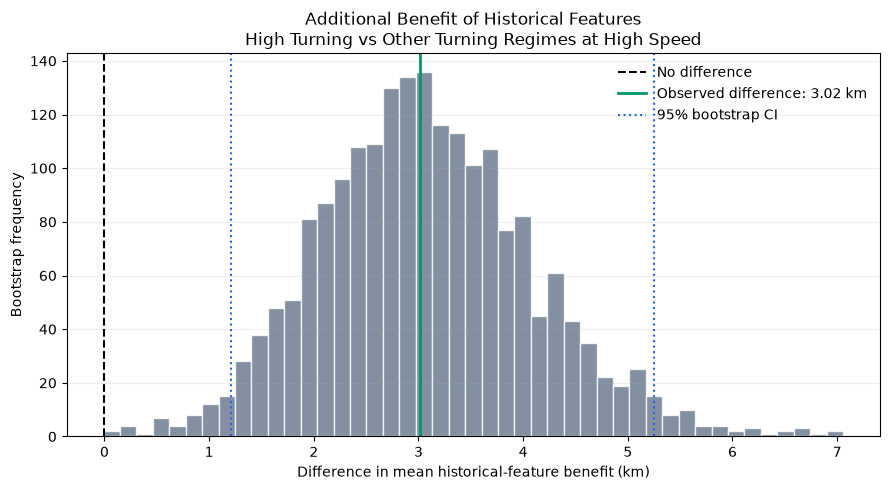

In [38]:

# Step 7.5 — Bootstrap contrast within the high-speed regime

high_speed = bootstrap_data.loc[
    bootstrap_data["Speed_group"] == "High"
].copy()

high_speed["contrast_group"] = np.where(
    high_speed["Turning_group"] == "High",
    "High Turning",
    "Low/Medium Turning"
)

contrast_stats = (
    high_speed
    .groupby(
        ["trajectory_id", "contrast_group"],
        observed=True
    )["history_gain"]
    .agg(["sum", "count"])
    .reset_index()
)

contrast_groups = ["High Turning", "Low/Medium Turning"]

contrast_sums = (
    contrast_stats.pivot(
        index="trajectory_id",
        columns="contrast_group",
        values="sum"
    )
    .reindex(
        index=drifter_ids,
        columns=contrast_groups
    )
    .fillna(0)
    .to_numpy()
)

contrast_counts = (
    contrast_stats.pivot(
        index="trajectory_id",
        columns="contrast_group",
        values="count"
    )
    .reindex(
        index=drifter_ids,
        columns=contrast_groups
    )
    .fillna(0)
    .to_numpy()
)

group_means = (
    contrast_sums.sum(axis=0)
    / contrast_counts.sum(axis=0)
)

observed_difference = group_means[0] - group_means[1]

contrast_bootstrap = []

rng_contrast = np.random.default_rng(43)

for b in range(2000):

    sampled = rng_contrast.integers(
        0, n_drifters, size=n_drifters
    )

    sums = contrast_sums[sampled].sum(axis=0)
    counts = contrast_counts[sampled].sum(axis=0)

    if np.all(counts > 0):
        means = sums / counts
        contrast_bootstrap.append(
            means[0] - means[1]
        )

contrast_bootstrap = np.asarray(contrast_bootstrap)

contrast_ci = np.percentile(
    contrast_bootstrap, [2.5, 97.5]
)

print("High Speed + High Turning mean gain:",
      round(group_means[0], 3), "km")

print("High Speed + Low/Medium Turning mean gain:",
      round(group_means[1], 3), "km")

print("Difference in mean gain:",
      round(observed_difference, 3), "km")

print("95% cluster-bootstrap CI:",
      np.round(contrast_ci, 3))

print("Valid bootstrap replicates:",
      len(contrast_bootstrap))

# Plot bootstrap contrast distribution
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    contrast_bootstrap,
    bins=45,
    color="#64748B",
    alpha=0.8,
    edgecolor="white"
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="No difference"
)

ax.axvline(
    observed_difference,
    color="#059669",
    linewidth=2,
    label=f"Observed difference: {observed_difference:.2f} km"
)

ax.axvline(
    contrast_ci[0],
    color="#2563EB",
    linestyle=":",
    linewidth=1.5
)

ax.axvline(
    contrast_ci[1],
    color="#2563EB",
    linestyle=":",
    linewidth=1.5,
    label="95% bootstrap CI"
)

ax.set_xlabel(
    "Difference in mean historical-feature benefit (km)"
)
ax.set_ylabel("Bootstrap frequency")

ax.set_title(
    "Additional Benefit of Historical Features\n"
    "High Turning vs Other Turning Regimes at High Speed"
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "report_high_speed_turning_bootstrap_contrast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 7.5 Statistical Comparison of Historical-Feature Benefits at High Speed

The joint-regime analysis suggested that historical motion features provide particularly large improvements for forecasts characterised by both high speed and high turning rates. To assess whether this difference extends beyond sampling variability, a direct comparison was conducted within the high-speed regime.

Forecasts were divided into two groups: high turning and combined low/medium turning. For each forecast, historical-feature benefit was calculated as the reduction in 24-hour great-circle position error from GB Current to GB History. A drifter-level cluster bootstrap with 2,000 resamples was used to estimate uncertainty in the difference between group mean benefits.

The high-speed, high-turning group achieved a mean error reduction of **7.032 km**, compared with **4.015 km** for high-speed forecasts with low or medium turning rates. The estimated difference was **3.017 km**, with a 95% cluster-bootstrap confidence interval of **[1.212, 5.248] km**.

Because the confidence interval lies entirely above zero, the results provide statistical evidence that the average absolute benefit of historical features is greater in the high-turning group than in the combined lower-turning group, conditional on high-speed motion.

This finding strengthens the interpretation of the preceding motion-regime analyses. Historical information is beneficial across all investigated regimes, but its contribution is not uniform. In particular, models using recent motion history appear better equipped to correct forecast errors associated with rapidly moving drifters experiencing substantial directional variation.

However, this comparison remains observational. Differences between motion regimes may also reflect geographic, seasonal or environmental characteristics. The results therefore establish a robust conditional association rather than a causal effect of turning rate on model performance.



## 8. Spatial and Temporal Evaluation

### 8.1 Spatial Distribution of Forecast Errors

Although the preceding analyses demonstrate that forecasting performance varies with recent motion characteristics, prediction difficulty may also depend on geographic location.

To investigate spatial heterogeneity, held-out forecast origins are assigned to a regular 1° × 1° longitude–latitude grid. Within each grid cell, we calculate:

1. The mean 24-hour great-circle position error of GB History.
2. The mean improvement of GB History relative to Constant Velocity.

Only grid cells containing at least 100 forecasts from at least three distinct drifters are displayed. These thresholds reduce the influence of sparsely sampled locations.

All spatial statistics are computed exclusively from the held-out test forecasts. The resulting maps describe geographic variation in predictive performance rather than independent validation of unseen geographic regions, since the train–test split was performed by drifter rather than spatial location.


Available columns:
['trajectory_id', 'time', 'lon_t', 'lat_t', 've_t', 'vn_t', 'sample_id', 'lon_target', 'lat_target', 'lon_t_feature', 'lat_t_feature', 've_t_feature', 'vn_t_feature', 'speed_t', 'heading_sin_t', 'heading_cos_t', 'mean_speed', 'sd_speed', 'mean_ve', 'mean_vn', 'sd_ve', 'sd_vn', 'mean_acceleration', 'max_acceleration', 'mean_speed_change', 'mean_turning', 'max_turning', 'valid_turn_fraction', 've_trend', 'vn_trend', 'history_dlon', 'history_dlat', 'day_sin', 'day_cos', 'dx_true', 'dy_true', 'dx_cv', 'dy_cv', 'dx_residual', 'dy_residual', 'split', 'lon_cv', 'lat_cv', 'error_cv_km', 'Constant Velocity_lon', 'Constant Velocity_lat', 'Mean-flow Advection_lon', 'Mean-flow Advection_lat', 'mean_flow_fallback_steps', 'Ridge Current_lon', 'Ridge Current_lat', 'Ridge History_lon', 'Ridge History_lat', 'Elastic Net Current_lon', 'Elastic Net Current_lat', 'Elastic Net History_lon', 'Elastic Net History_lat', 'RF Current_lon', 'RF Current_lat', 'RF History_lon', 'RF History_lat',

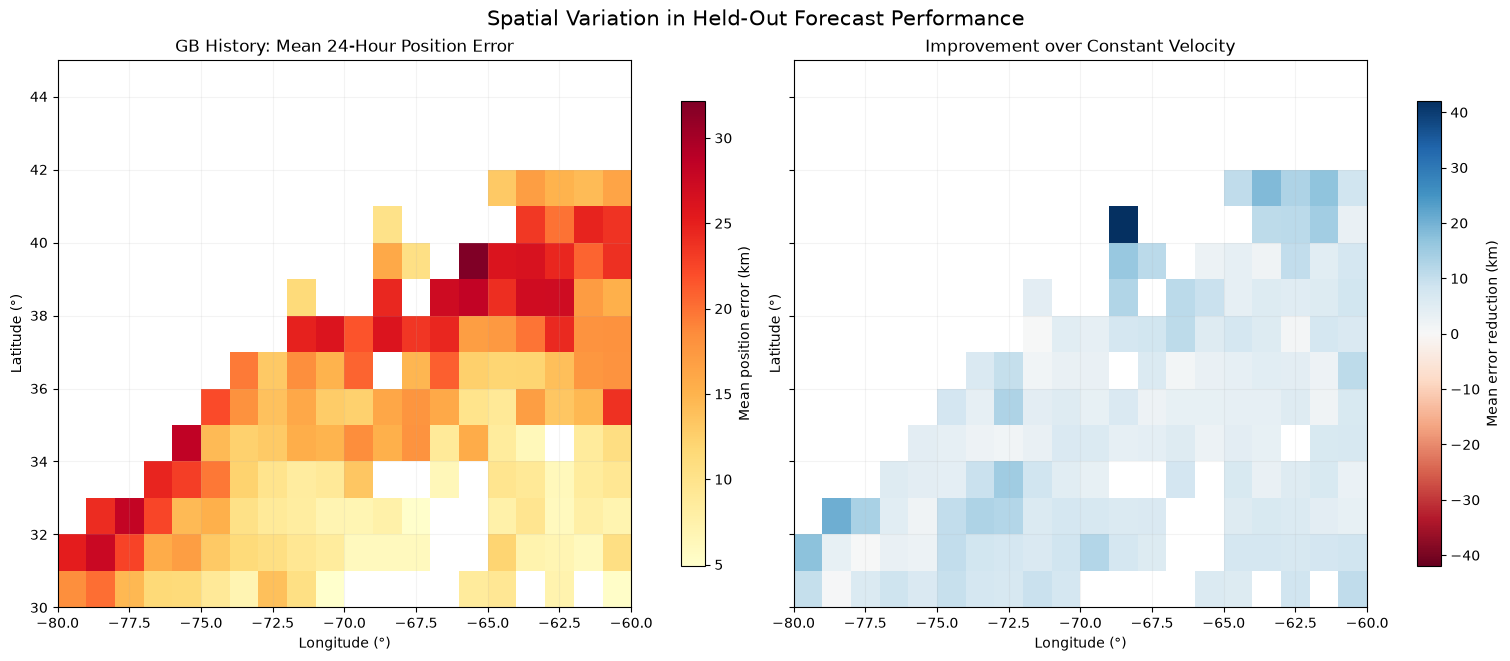

,lat_grid,lon_grid,mean_gb_error,mean_improvement,n_forecasts,n_drifters
162,39.0,-66.0,32.162,2.583,114,3
79,34.0,-76.0,28.536,4.383,479,16
149,38.0,-66.0,28.306,9.409,375,9
42,32.0,-78.0,28.205,13.518,267,13
21,31.0,-79.0,27.591,3.341,365,14
148,38.0,-67.0,27.288,11.251,170,6
152,38.0,-63.0,27.214,4.965,574,13
151,38.0,-64.0,27.152,5.695,489,14
164,39.0,-64.0,26.387,1.929,383,11
163,39.0,-65.0,26.192,3.811,186,6


In [39]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from pathlib import Path

FIG_DIR = Path("../image")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load saved held-out forecasts
spatial = pd.read_parquet(
    "../data/processed/report_test_predictions.parquet"
).copy()

print("Available columns:")
print(spatial.columns.tolist())

# Resolve saved error-column names
def find_column(df, candidates):
    for name in candidates:
        if name in df.columns:
            return name
    raise KeyError(
        f"Could not find any of: {candidates}"
    )

cv_col = find_column(spatial, [
    "error_Constant Velocity",
    "Constant Velocity",
    "Constant Velocity_error",
    "cv_error_km",
    "error_cv"
])

gb_col = find_column(spatial, [
    "error_GB History",
    "GB History",
    "GB History_error",
    "gb_history_error_km",
    "error_gb_history"
])

lon_col = find_column(spatial, ["lon_t", "lon"])
lat_col = find_column(spatial, ["lat_t", "lat"])

# Spatial grid at forecast origins
GRID_DEG = 1.0

spatial["lon_grid"] = (
    np.floor(spatial[lon_col] / GRID_DEG) * GRID_DEG
)
spatial["lat_grid"] = (
    np.floor(spatial[lat_col] / GRID_DEG) * GRID_DEG
)

spatial["gb_error"] = spatial[gb_col]
spatial["improvement"] = spatial[cv_col] - spatial[gb_col]

grid_summary = (
    spatial.groupby(["lat_grid", "lon_grid"])
    .agg(
        mean_gb_error=("gb_error", "mean"),
        mean_improvement=("improvement", "mean"),
        n_forecasts=("gb_error", "size"),
        n_drifters=("trajectory_id", "nunique")
    )
    .reset_index()
)

# Filter sparsely observed grid cells
MIN_FORECASTS = 100
MIN_DRIFTERS = 3

grid_valid = grid_summary.loc[
    (grid_summary["n_forecasts"] >= MIN_FORECASTS)
    & (grid_summary["n_drifters"] >= MIN_DRIFTERS)
].copy()

print("\nTotal grid cells:", len(grid_summary))
print("Eligible grid cells:", len(grid_valid))
print(
    "Forecasts represented:",
    grid_valid["n_forecasts"].sum()
)
print(
    "Coverage:",
    f'{100 * grid_valid["n_forecasts"].sum() / len(spatial):.1f}%'
)

# Build 2D grid arrays
lon_edges = np.arange(-80, -59, GRID_DEG)
lat_edges = np.arange(30, 46, GRID_DEG)

def to_grid(values_col):
    table = grid_valid.pivot(
        index="lat_grid",
        columns="lon_grid",
        values=values_col
    )

    return table.reindex(
        index=lat_edges[:-1],
        columns=lon_edges[:-1]
    ).to_numpy()

error_map = to_grid("mean_gb_error")
gain_map = to_grid("mean_improvement")

# Shared geographic axes
fig, axes = plt.subplots(
    1, 2, figsize=(15, 6.5),
    sharex=True, sharey=True,
    constrained_layout=True
)

m1 = axes[0].pcolormesh(
    lon_edges,
    lat_edges,
    error_map,
    cmap="YlOrRd",
    shading="flat"
)

axes[0].set_title(
    "GB History: Mean 24-Hour Position Error"
)
fig.colorbar(
    m1, ax=axes[0],
    label="Mean position error (km)",
    shrink=0.85
)

max_abs_gain = np.nanmax(np.abs(gain_map))

m2 = axes[1].pcolormesh(
    lon_edges,
    lat_edges,
    gain_map,
    cmap="RdBu",
    norm=TwoSlopeNorm(
        vmin=-max_abs_gain,
        vcenter=0,
        vmax=max_abs_gain
    ),
    shading="flat"
)

axes[1].set_title(
    "Improvement over Constant Velocity"
)
fig.colorbar(
    m2, ax=axes[1],
    label="Mean error reduction (km)",
    shrink=0.85
)

for ax in axes:
    ax.set_xlim(-80, -60)
    ax.set_ylim(30, 45)
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.grid(alpha=0.15)

fig.suptitle(
    "Spatial Variation in Held-Out Forecast Performance",
    fontsize=15
)

fig.savefig(
    FIG_DIR / "report_spatial_forecast_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    grid_valid.sort_values(
        "mean_gb_error",
        ascending=False
    ).head(10).round(3)
)



#### Spatial Patterns in Forecast Performance

The spatial analysis retained 145 grid cells satisfying the minimum coverage requirements of 100 forecasts and three distinct drifters per cell. These cells represented 73,214 held-out forecasts, accounting for 88.7% of the test observations.

GB History exhibited substantial geographic variation in mean 24-hour position error. Several cells in the northern and central portions of the study region recorded mean errors exceeding 25 km, including cells near 39°N, 66°W (32.16 km) and 38°N, 66°W (28.31 km).

However, areas with high absolute prediction errors did not necessarily exhibit limited improvements over the Constant Velocity baseline. For example, the cell near 38°N, 67°W achieved an average error reduction of 11.25 km, while the cell near 32°N, 78°W achieved a reduction of 13.52 km.

The spatial distribution of relative improvement was predominantly positive across the displayed cells, suggesting that the history-enhanced model provides benefits across a broad geographic range rather than exclusively within a narrow subregion.

Nevertheless, improvements were spatially heterogeneous. Some cells exhibited relatively small gains despite substantial absolute errors, indicating that particular movement patterns or geographic conditions may remain challenging for the model.

These findings distinguish geographic forecast difficulty from the effectiveness of model-based corrections. The observed spatial patterns are descriptive and should not be interpreted as direct evidence of specific oceanographic mechanisms without additional environmental information.



### 8.2 Temporal Stability of Forecast Performance

To examine whether predictive performance is consistent across the study period, held-out forecasts are grouped by calendar year and four predefined multi-year intervals: 2007–2010, 2011–2014, 2015–2018 and 2019–2022.

For each temporal group, we calculate the median 24-hour position error for Constant Velocity, GB Current and GB History, together with the mean improvement of GB History relative to Constant Velocity.

Forecast counts and the number of distinct drifters are reported to distinguish well-supported temporal patterns from periods with limited observations.

Because the dataset is split by drifter rather than chronologically, these comparisons assess temporal heterogeneity in held-out performance, not prospective generalisation to entirely unseen future years.


Yearly performance:


,year,Samples,Drifters,CV_Median,GB_Current_Median,GB_History_Median,CV_Mean_Gain,History_Mean_Gain
0,2007,11030,13,14.385,12.641,8.257,7.240,4.065
1,2008,1860,3,11.979,9.466,7.297,5.365,2.597
2,2009,2392,5,24.337,20.192,16.030,9.386,4.755
3,2010,3034,4,18.967,18.523,14.304,5.981,5.251
4,2011,7696,7,17.513,15.506,11.871,5.599,3.470
5,2012,8163,10,14.229,10.915,7.280,8.902,3.619
6,2013,6056,10,12.527,9.542,6.524,7.068,2.992
7,2014,5739,6,18.021,14.682,10.776,7.504,3.250
8,2015,5724,5,19.802,14.618,11.243,7.379,2.739
9,2016,2356,4,17.028,13.275,9.844,8.851,2.883


Four-period performance:


,period,Samples,Drifters,CV_Median,GB_Current_Median,GB_History_Median,CV_Mean_Gain,History_Mean_Gain
0,2007–2010,18316,22,15.633,13.572,9.460,7.121,4.202
1,2011–2014,27654,30,15.422,12.397,8.770,7.291,3.364
2,2015–2018,20056,14,16.916,13.667,10.102,7.121,3.478
3,2019–2022,16520,15,15.715,12.840,8.852,7.820,3.733


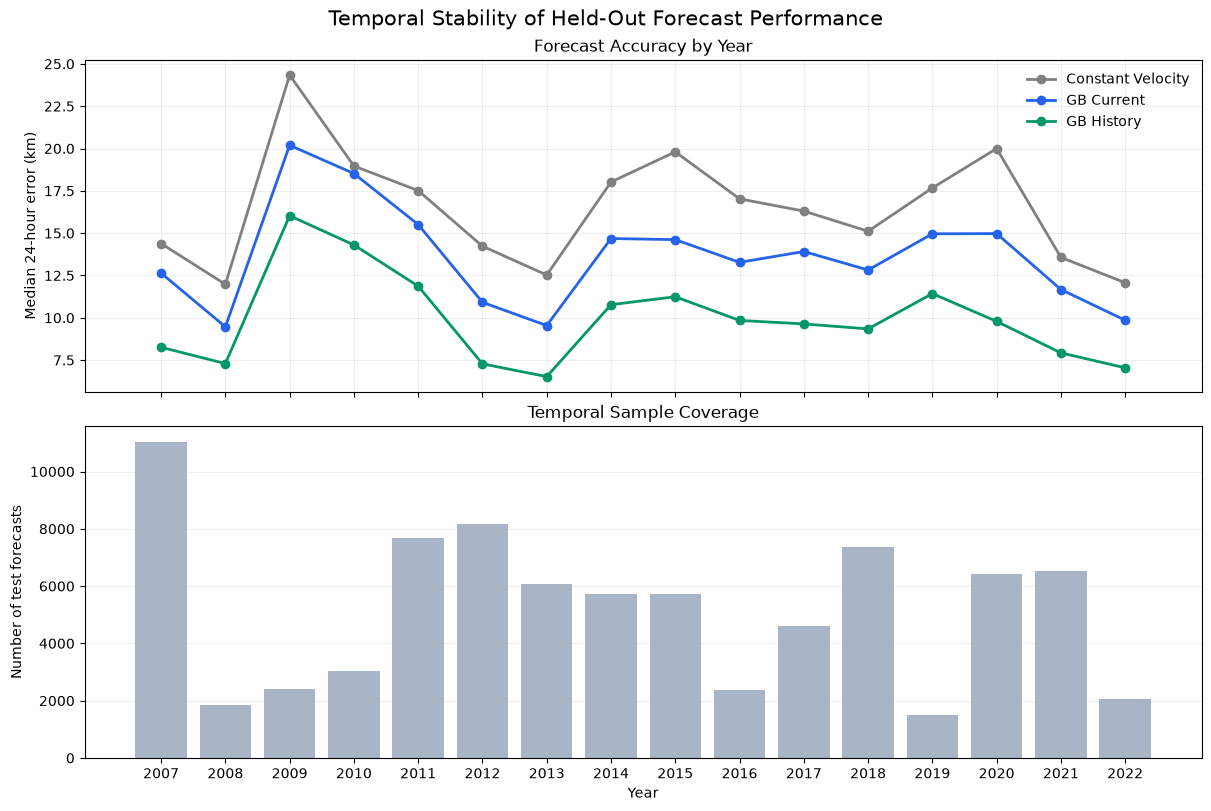

In [40]:

# Section 8.2 — Temporal stability

temporal = spatial.copy()
temporal["time"] = pd.to_datetime(temporal["time"])
temporal["year"] = temporal["time"].dt.year

temporal["period"] = pd.cut(
    temporal["year"],
    bins=[2006, 2010, 2014, 2018, 2022],
    labels=[
        "2007–2010",
        "2011–2014",
        "2015–2018",
        "2019–2022"
    ]
)

temporal["cv_error"] = temporal["Constant Velocity_error"]
temporal["gb_current_error"] = temporal["GB Current_error"]
temporal["gb_history_error"] = temporal["GB History_error"]

temporal["cv_gain"] = (
    temporal["cv_error"] - temporal["gb_history_error"]
)

temporal["history_gain"] = (
    temporal["gb_current_error"] - temporal["gb_history_error"]
)

def temporal_summary(data, group_col):
    return (
        data.groupby(group_col, observed=True)
        .agg(
            Samples=("trajectory_id", "size"),
            Drifters=("trajectory_id", "nunique"),
            CV_Median=("cv_error", "median"),
            GB_Current_Median=("gb_current_error", "median"),
            GB_History_Median=("gb_history_error", "median"),
            CV_Mean_Gain=("cv_gain", "mean"),
            History_Mean_Gain=("history_gain", "mean")
        )
        .reset_index()
    )

yearly = temporal_summary(temporal, "year")
periods = temporal_summary(temporal, "period")

print("Yearly performance:")
display(yearly.round(3))

print("Four-period performance:")
display(periods.round(3))

# Visualise yearly performance
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True
)

models_to_plot = [
    ("CV_Median", "Constant Velocity", "#808080"),
    ("GB_Current_Median", "GB Current", "#2563EB"),
    ("GB_History_Median", "GB History", "#059669")
]

for col, label, color in models_to_plot:
    axes[0].plot(
        yearly["year"],
        yearly[col],
        marker="o",
        linewidth=2,
        color=color,
        label=label
    )

axes[0].set_ylabel("Median 24-hour error (km)")
axes[0].set_title("Forecast Accuracy by Year")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.2)

axes[1].bar(
    yearly["year"],
    yearly["Samples"],
    color="#94A3B8",
    alpha=0.8
)

axes[1].set_xlabel("Year")
axes[1].set_ylabel("Number of test forecasts")
axes[1].set_title("Temporal Sample Coverage")
axes[1].grid(axis="y", alpha=0.2)

axes[1].set_xticks(yearly["year"])

fig.suptitle(
    "Temporal Stability of Held-Out Forecast Performance",
    fontsize=15
)

fig.savefig(
    FIG_DIR / "report_temporal_forecast_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



#### Temporal Stability Results

The temporal evaluation demonstrates consistent relative performance across the 2007–2022 study period. GB History achieved lower median 24-hour position errors than both GB Current and Constant Velocity in all 16 calendar years.

Across the four predefined study periods, GB History median errors ranged from 8.77 to 10.10 km, compared with 15.42–16.92 km for Constant Velocity. The mean reduction in position error relative to Constant Velocity remained between 7.12 and 7.82 km across all four periods.

Historical motion features also provided consistent additional predictive value, reducing mean error relative to GB Current by 3.36–4.20 km across the four periods.

Although absolute forecasting difficulty varied between years, the relative advantage of history-enhanced gradient boosting was maintained throughout the study period.

Annual comparisons should nevertheless be interpreted cautiously, as several years contained only three to five held-out drifters. Consequently, year-specific differences may reflect the composition of the available trajectories rather than systematic temporal changes in model performance.

Overall, these findings provide descriptive evidence of temporal robustness within the observed study period, while not establishing prospective forecasting performance for unseen future years.



## 9. Environmental Conditions and Forecast Performance

### 9.1 Sea Surface Temperature and Forecast Difficulty

In addition to recent drifter motion, sea surface temperature (SST) may provide useful environmental context for understanding forecast performance.

Unlike speed, acceleration and turning rate, SST describes an environmental condition rather than the observed kinematics of the drifter.

This section examines whether 24-hour position errors vary across SST regimes. SST values at forecast origins are obtained from the original hourly drifter observations and converted from Kelvin to degrees Celsius.

Low, Medium and High SST regimes are defined using the 33rd and 67th percentiles of the training-origin SST distribution. The resulting thresholds are applied without modification to the held-out test observations.

We compare forecast errors across these regimes and examine whether the benefit of historical motion features varies with SST.

These analyses are descriptive. SST is associated with geographic location, seasonality and oceanographic conditions, so observed differences should not be interpreted as causal temperature effects.


In [41]:

# Section 9.1 — SST at forecast origins

source = pd.read_parquet(
    "../data/processed/gulf_stream_trajectories.parquet",
    columns=["trajectory_id", "time", "sst"]
)

source["time"] = pd.to_datetime(source["time"])

# One SST observation per drifter and timestamp
sst_lookup = source.drop_duplicates(
    subset=["trajectory_id", "time"]
)

# Attach SST to all forecast origins
sst_data = modelling[
    ["sample_id", "trajectory_id", "time", "split"]
].copy()

sst_data["time"] = pd.to_datetime(sst_data["time"])

sst_data = sst_data.merge(
    sst_lookup,
    on=["trajectory_id", "time"],
    how="left",
    validate="many_to_one"
)

# Kelvin to Celsius
sst_data["sst_c"] = sst_data["sst"] - 273.15

# Training-only thresholds
train_sst = sst_data.loc[
    (sst_data["split"] == "train") &
    sst_data["sst_c"].notna(),
    "sst_c"
]

sst_low, sst_high = train_sst.quantile([1/3, 2/3])

# Apply thresholds to test predictions
sst_test = test_predictions.merge(
    sst_data[["sample_id", "sst_c"]],
    on="sample_id",
    how="left",
    validate="one_to_one"
)

sst_test["SST_group"] = pd.cut(
    sst_test["sst_c"],
    bins=[-np.inf, sst_low, sst_high, np.inf],
    labels=["Low", "Medium", "High"]
)

print(f"SST thresholds: {sst_low:.2f}°C, {sst_high:.2f}°C")

print("\nSST availability:")
print(
    f"{sst_test['sst_c'].notna().sum():,} / "
    f"{len(sst_test):,} test forecasts"
)

print("\nSST distribution (°C):")
display(
    sst_test["sst_c"].describe().round(3)
)

print("\nSST regime coverage:")
display(
    sst_test.groupby("SST_group", observed=True)
    .agg(
        Samples=("sample_id", "size"),
        Drifters=("trajectory_id", "nunique"),
        Mean_SST=("sst_c", "mean")
    )
    .round(3)
    .reset_index()
)


SST thresholds: 26.93°C, 28.06°C

SST availability:
77,845 / 82,546 test forecasts

SST distribution (°C):


count    77845.000
mean        26.791
std          2.913
min         10.322
25%         26.281
50%         27.566
75%         28.495
max         34.718
Name: sst_c, dtype: float64


SST regime coverage:


,SST_group,Samples,Drifters,Mean_SST
0,Low,28147,58,24.174
1,Medium,21205,56,27.525
2,High,28493,57,28.829



### 9.2 Forecast Performance Across SST Regimes

Forecast accuracy is evaluated separately across Low, Medium and High SST regimes using the training-derived temperature thresholds.

For each regime, we compare the median and 90th-percentile position errors of Constant Velocity, GB Current and GB History.

We additionally calculate the mean reduction in forecast error achieved by incorporating historical motion features into gradient boosting.

This analysis investigates whether SST regimes are associated with differences in forecasting difficulty and whether the predictive benefit of motion history varies across environmental conditions.

Because SST is geographically and seasonally structured, the comparisons are interpreted as descriptive associations rather than independent temperature effects.


,SST Regime,Model,Samples,Mean,Median,P90
0,Low,Constant Velocity,28147,23.073,17.588,47.712
1,Low,GB Current,28147,17.826,13.810,36.206
2,Low,GB History,28147,13.733,9.981,28.462
3,Medium,Constant Velocity,21205,19.751,15.498,38.313
4,Medium,GB Current,21205,16.815,13.060,33.748
5,Medium,GB History,21205,13.324,9.278,29.320
6,High,Constant Velocity,28493,18.872,14.934,36.837
7,High,GB Current,28493,15.938,12.281,32.109
8,High,GB History,28493,12.551,8.279,28.250


,SST_group,Samples,Mean_Gain,Median_Gain
0,Low,28147,4.093,3.444
1,Medium,21205,3.492,3.472
2,High,28493,3.387,3.338


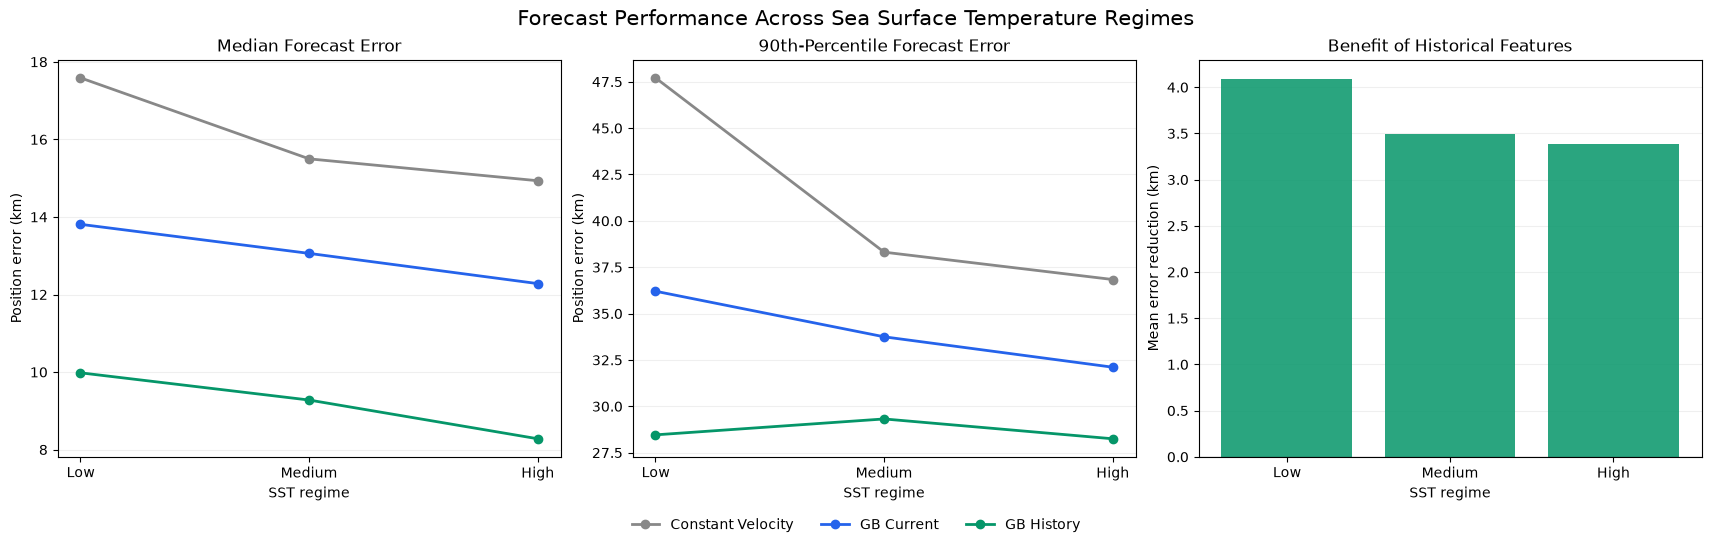

In [42]:

# Section 9.2 — Forecast errors across SST regimes

sst_models = [
    "Constant Velocity",
    "GB Current",
    "GB History"
]

sst_order = ["Low", "Medium", "High"]

sst_results = []

for regime in sst_order:
    subset = sst_test[
        sst_test["SST_group"] == regime
    ]

    for model in sst_models:
        errors = subset[f"{model}_error"].dropna()

        sst_results.append({
            "SST Regime": regime,
            "Model": model,
            "Samples": len(errors),
            "Mean": errors.mean(),
            "Median": errors.median(),
            "P90": errors.quantile(0.90)
        })

sst_results = pd.DataFrame(sst_results)

display(sst_results.round(3))

# Historical feature benefit: paired error reduction
sst_benefit = (
    sst_test.assign(
        history_gain=(
            sst_test["GB Current_error"]
            - sst_test["GB History_error"]
        )
    )
    .groupby("SST_group", observed=True)
    .agg(
        Samples=("history_gain", "count"),
        Mean_Gain=("history_gain", "mean"),
        Median_Gain=("history_gain", "median")
    )
    .reset_index()
)

display(sst_benefit.round(3))

# Visual comparison
fig, axes = plt.subplots(
    1, 3, figsize=(17, 5), constrained_layout=True
)

colors = {
    "Constant Velocity": "#888888",
    "GB Current": "#2563eb",
    "GB History": "#059669"
}

for model in sst_models:
    values = (
        sst_results[sst_results["Model"] == model]
        .set_index("SST Regime")
        .reindex(sst_order)
    )

    axes[0].plot(
        sst_order, values["Median"],
        marker="o", linewidth=2,
        color=colors[model], label=model
    )

    axes[1].plot(
        sst_order, values["P90"],
        marker="o", linewidth=2,
        color=colors[model], label=model
    )

axes[0].set_title("Median Forecast Error")
axes[0].set_ylabel("Position error (km)")

axes[1].set_title("90th-Percentile Forecast Error")
axes[1].set_ylabel("Position error (km)")

axes[2].bar(
    sst_benefit["SST_group"].astype(str),
    sst_benefit["Mean_Gain"],
    color="#059669",
    alpha=0.85
)

axes[2].axhline(
    0, color="black", linewidth=0.8
)

axes[2].set_title("Benefit of Historical Features")
axes[2].set_ylabel("Mean error reduction (km)")

for ax in axes:
    ax.set_xlabel("SST regime")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Forecast Performance Across Sea Surface Temperature Regimes",
    fontsize=15
)

fig.savefig(
    FIG_DIR / "report_sst_regime_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 9.3 Joint Effects of SST and Motion Speed

The preceding analysis indicates that lower SST regimes are associated with higher forecast errors and somewhat greater benefits from historical motion features.

However, SST and motion speed may not be independent. Differences in the distribution of drifter speeds across temperature regimes could partly explain the observed association between SST and forecasting difficulty.

To investigate this possibility, we jointly stratify held-out forecasts by SST and historical mean-speed regimes, using thresholds derived from the training partition.

We examine the distribution of speed regimes within each SST category, the median GB History position error, and the mean benefit of historical motion features.

This joint analysis helps distinguish temperature-associated differences from variation in the observed motion conditions, although it does not fully control for geographic or seasonal confounding.


Joint sample counts:


Speed_group,Low,Medium,High
SST_group,,,
Low,6855,9048,12244
Medium,6085,6615,8505
High,10202,6883,11408


Speed distribution within SST regimes (%):


Speed_group,Low,Medium,High
SST_group,,,
Low,24.4,32.1,43.5
Medium,28.7,31.2,40.1
High,35.8,24.2,40.0


GB History median error (km):


Speed_group,Low,Medium,High
SST_group,,,
Low,6.44,8.61,15.03
Medium,5.53,7.87,15.77
High,4.81,7.57,14.96


Historical feature mean benefit (km):


Speed_group,Low,Medium,High
SST_group,,,
Low,2.12,3.63,5.53
Medium,2.90,3.58,3.85
High,2.77,4.14,3.48


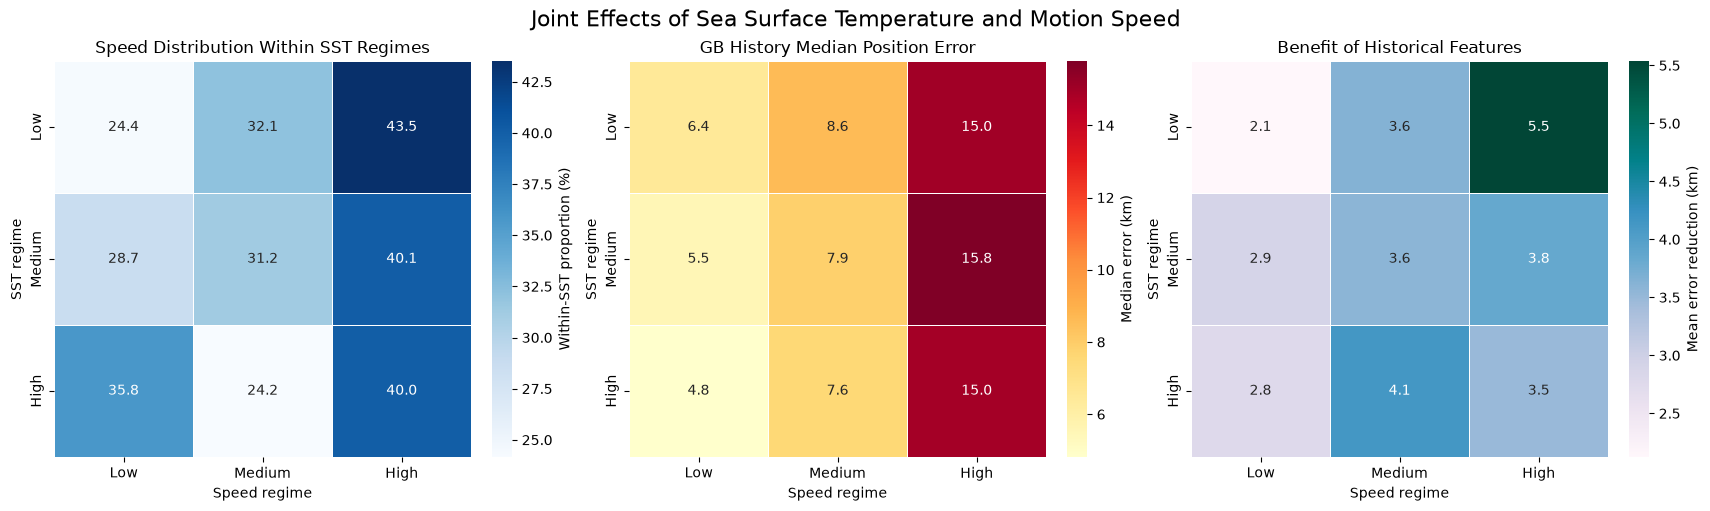

In [43]:

# Section 9.3 — Joint SST and speed analysis

import seaborn as sns

sst_speed = sst_test.dropna(
    subset=["SST_group", "Speed_group"]
).copy()

sst_order = ["Low", "Medium", "High"]
speed_order = ["Low", "Medium", "High"]

# Joint sample counts
joint_counts = pd.crosstab(
    sst_speed["SST_group"],
    sst_speed["Speed_group"]
).reindex(
    index=sst_order,
    columns=speed_order,
    fill_value=0
)

# Within-SST speed distribution (%)
speed_distribution = (
    joint_counts.div(joint_counts.sum(axis=1), axis=0) * 100
)

# GB History median forecast error
gb_error_matrix = (
    sst_speed.pivot_table(
        index="SST_group",
        columns="Speed_group",
        values="GB History_error",
        aggfunc="median",
        observed=True
    )
    .reindex(index=sst_order, columns=speed_order)
)

# Historical feature benefit
sst_speed["history_gain"] = (
    sst_speed["GB Current_error"]
    - sst_speed["GB History_error"]
)

benefit_matrix = (
    sst_speed.pivot_table(
        index="SST_group",
        columns="Speed_group",
        values="history_gain",
        aggfunc="mean",
        observed=True
    )
    .reindex(index=sst_order, columns=speed_order)
)

print("Joint sample counts:")
display(joint_counts)

print("Speed distribution within SST regimes (%):")
display(speed_distribution.round(1))

print("GB History median error (km):")
display(gb_error_matrix.round(2))

print("Historical feature mean benefit (km):")
display(benefit_matrix.round(2))

# Visualization
fig, axes = plt.subplots(
    1, 3, figsize=(17, 5), constrained_layout=True
)

matrices = [
    speed_distribution,
    gb_error_matrix,
    benefit_matrix
]

titles = [
    "Speed Distribution Within SST Regimes",
    "GB History Median Position Error",
    "Benefit of Historical Features"
]

cmaps = ["Blues", "YlOrRd", "PuBuGn"]

colorbar_labels = [
    "Within-SST proportion (%)",
    "Median error (km)",
    "Mean error reduction (km)"
]

for ax, matrix, title, cmap, cbar_label in zip(
    axes, matrices, titles, cmaps, colorbar_labels
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".1f",
        cmap=cmap,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": cbar_label},
        ax=ax
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Speed regime")
    ax.set_ylabel("SST regime")

fig.suptitle(
    "Joint Effects of Sea Surface Temperature and Motion Speed",
    fontsize=16
)

fig.savefig(
    FIG_DIR / "report_sst_speed_interaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



#### SST and Motion Speed: Joint Analysis Results

The joint SST–speed analysis reveals that differences in motion speed partially explain the variation in forecasting difficulty across temperature regimes.

High-speed observations accounted for 43.5% of forecasts in the Low SST regime, compared with approximately 40% in the Medium and High SST regimes. Conversely, low-speed observations were more common in the High SST regime (35.8%) than in the Low SST regime (24.4%).

Within low-speed conditions, GB History median position error decreased from 6.44 km in the Low SST regime to 4.81 km in the High SST regime. A similar, though smaller, reduction was observed under medium-speed conditions (8.61 to 7.57 km).

However, under high-speed conditions, median errors remained relatively similar across temperature regimes, ranging from 14.96 to 15.77 km. This suggests that the association between SST and forecast difficulty is more pronounced at lower motion speeds, while high-speed conditions are consistently associated with greater prediction errors regardless of SST category.

The additional benefit of historical motion features also varied across the joint regimes. The largest mean improvement was observed under Low SST and High Speed conditions (5.53 km), although no consistent monotonic temperature-related pattern was present across all speed categories.

Overall, these findings indicate that motion speed is an important factor in SST-conditioned forecasting performance. Nevertheless, residual differences across SST regimes suggest that speed composition alone does not fully account for the observed variation. Geographic, seasonal and other environmental factors may also contribute.

These findings remain descriptive and do not establish an independent or causal effect of SST on forecast accuracy.


In [44]:

# Section 9.4 — Prepare SST feature ablation

# Attach SST to the original modelling dataset
sst_feature_data = modelling.merge(
    sst_data[["sample_id", "sst_c"]],
    on="sample_id",
    how="left",
    validate="one_to_one"
)

# Original GB History features
gb_history_features = current_features + history_features

# Extended feature set
gb_history_sst_features = gb_history_features + ["sst_c"]

# Keep the original train/validation partitions
sst_train = sst_feature_data[
    sst_feature_data["split"] == "train"
].copy()

sst_val = sst_feature_data[
    sst_feature_data["split"] == "validation"
].copy()

print("Training samples:", len(sst_train))
print("Validation samples:", len(sst_val))

print("\nSST availability:")
print(
    "Train:",
    f"{sst_train['sst_c'].notna().mean():.1%}"
)
print(
    "Validation:",
    f"{sst_val['sst_c'].notna().mean():.1%}"
)

print("\nFeature counts:")
print("GB History:", len(gb_history_features))
print("GB History + SST:", len(gb_history_sst_features))


Training samples: 455662
Validation samples: 88471

SST availability:
Train: 98.4%
Validation: 97.0%

Feature counts:
GB History: 25
GB History + SST: 26



### 9.4 Incremental Predictive Value of SST

To determine whether SST provides additional predictive information beyond historical motion characteristics, a feature ablation experiment is conducted.

Two gradient boosting models are compared:

- **GB History:** The original 25-feature model incorporating current state and historical motion descriptors.
- **GB History + SST:** An otherwise identical model with sea surface temperature at the forecast origin included as an additional predictor.

Both models use the same training and validation partitions, residual-displacement targets, and gradient boosting hyperparameters. Missing SST values are handled natively by the estimator.

The comparison focuses on mean, median, 90th-percentile and root-mean-square position errors, together with paired differences in forecast accuracy.

Since SST-related patterns have already been explored on the held-out test partition, this additional experiment is treated as exploratory and evaluated on the original validation partition rather than presented as a new independent test-set result.


In [45]:

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
import joblib

# Match the selected GB History configuration (config 2)
gb_sst_model = MultiOutputRegressor(
    HistGradientBoostingRegressor(
        max_iter=250,
        max_leaf_nodes=31,
        learning_rate=0.08,
        l2_regularization=1.0,
        min_samples_leaf=50,
        random_state=42
    )
)

target_columns = ["dx_residual", "dy_residual"]

# Train the SST-extended model
gb_sst_model.fit(
    sst_train[gb_history_sst_features],
    sst_train[target_columns]
)

# Predictions from the original and extended models
gb_original = gb_models[("GB History", 2)]

pred_original = gb_original.predict(
    sst_val[gb_history_features]
)

pred_sst = gb_sst_model.predict(
    sst_val[gb_history_sst_features]
)

def evaluate_residual_forecast(data, residual_predictions):
    dx = data["dx_cv"].to_numpy() + residual_predictions[:, 0]
    dy = data["dy_cv"].to_numpy() + residual_predictions[:, 1]

    lon_pred, lat_pred = displacement_to_position(
        data["lon_t"].to_numpy(),
        data["lat_t"].to_numpy(),
        dx, dy
    )

    errors = np.asarray(
        great_circle_error(
            lon_pred,
            lat_pred,
            data["lon_target"].to_numpy(),
            data["lat_target"].to_numpy()
        )
    )

    return errors

error_original = evaluate_residual_forecast(
    sst_val, pred_original
)

error_sst = evaluate_residual_forecast(
    sst_val, pred_sst
)

def error_metrics(errors):
    return {
        "Mean": np.mean(errors),
        "Median": np.median(errors),
        "P90": np.quantile(errors, 0.90),
        "RMSE": np.sqrt(np.mean(errors ** 2))
    }

sst_ablation_results = pd.DataFrame([
    {
        "Model": "GB History",
        **error_metrics(error_original)
    },
    {
        "Model": "GB History + SST",
        **error_metrics(error_sst)
    }
])

display(sst_ablation_results.round(3))

# Paired improvement: positive values favour SST
paired_gain = error_original - error_sst

print(
    "Mean improvement from SST:",
    f"{paired_gain.mean():.4f} km"
)
print(
    "Median paired improvement:",
    f"{np.median(paired_gain):.4f} km"
)
print(
    "Forecasts improved:",
    f"{np.mean(paired_gain > 0):.1%}"
)

# Save exploratory model and validation results
joblib.dump(
    gb_sst_model,
    "../models/gb_history_with_sst.joblib"
)

sst_ablation_results.to_csv(
    "../data/processed/report_sst_ablation_validation.csv",
    index=False
)


,Model,Mean,Median,P90,RMSE
0,GB History,11.969,8.507,24.977,16.681
1,GB History + SST,11.950,8.537,24.929,16.633


Mean improvement from SST: 0.0192 km
Median paired improvement: 0.0019 km
Forecasts improved: 50.1%



#### SST Feature Ablation Results

The SST-extended gradient boosting model produced only marginal changes in validation performance compared with the original GB History model.

Mean position error decreased from 11.969 km to 11.950 km, corresponding to an improvement of approximately 0.16%. The 90th-percentile error decreased slightly from 24.977 km to 24.929 km, while median error increased from 8.507 km to 8.537 km. The median paired improvement was only 0.0019 km, and 50.1% of individual forecasts improved after incorporating SST.

These results indicate that adding SST as a single additional predictor provides negligible incremental predictive benefit beyond the existing historical motion features.

This finding should be distinguished from the earlier SST-conditioned evaluation, which identified differences in forecast difficulty across temperature regimes. Such associations do not necessarily imply that SST contains additional predictive information once recent velocity, acceleration, turning behaviour and geographic position are already represented.

One possible explanation is that historical motion descriptors capture much of the short-term dynamical information associated with local ocean conditions. However, the present experiment cannot establish the underlying physical mechanism.

Overall, the ablation study supports retaining the original GB History model as the preferred forecasting approach. SST remains useful as a contextual variable for analysing forecast performance, but its direct inclusion does not materially improve 24-hour position prediction under the evaluated configuration.

Because this experiment was conducted after exploratory analysis of the held-out test set, its results are interpreted as exploratory validation evidence rather than an independently confirmed improvement.



## 10. Discussion and Limitations

### 10.1 Main Findings and Interpretation

This study investigated how recent motion characteristics influence the accuracy of 24-hour surface-drifter position forecasts in the Gulf Stream region. By combining physical forecasting baselines, multiple machine-learning algorithms, and motion-conditioned evaluation, the analysis provides consistent evidence that historical trajectory information improves short-term position prediction.

Across the evaluated model families, history-enhanced configurations generally outperformed their current-state counterparts. Gradient Boosting with historical motion features (GB History) achieved the strongest overall predictive performance, while Random Forest and Extra Trees produced competitive results. This consistency suggests that the value of historical information is not restricted to a particular learning algorithm.

The Constant Velocity baseline provided a useful reference by extrapolating the most recently observed velocity. In contrast, the regional Mean-flow Advection baseline performed relatively poorly, indicating that spatially averaged flow velocities do not adequately represent the individual motion of drifters over the forecasting horizon.

The geographic trajectory visualisations further supported the quantitative results. History-enhanced models generally followed observed trajectories more closely than the physical baselines, although local deviations and occasional large errors remained evident.

Together, these findings suggest that short-term drifter forecasting benefits from combining instantaneous velocity information with recent motion patterns and flexible nonlinear correction models.

### 10.2 Why Historical Motion Features Matter

The contribution of historical motion information was examined using speed, acceleration and turning-rate regimes derived from the preceding 24-hour observation window.

Forecast difficulty was strongly associated with motion speed. Higher-speed regimes generally exhibited larger position errors, consistent with the greater distances travelled over a fixed forecasting horizon and the potential accumulation of displacement errors.

Acceleration was also positively associated with forecast difficulty, suggesting that rapidly changing velocity conditions are less adequately represented by simple extrapolation.

Turning rate exhibited a more complex relationship with forecasting performance. High-turning regimes did not necessarily produce the largest absolute forecast errors. The joint speed-turning analysis revealed that speed and turning were themselves strongly associated: low-speed observations were disproportionately represented in high-turning regimes, while high-speed observations were concentrated in low-turning regimes.

Consequently, turning rate should not be interpreted independently of speed.

The strongest additional benefit from historical features occurred under combined high-speed and high-turning conditions. In this regime, GB History reduced mean forecast error by 7.032 km relative to GB Current, compared with 4.015 km for high-speed observations with low or medium turning rates.

The difference of 3.017 km was supported by a 95% drifter-cluster bootstrap confidence interval of [1.212, 5.248] km.

This result suggests that recent motion history is particularly informative when substantial displacement coincides with directional variability. Historical velocity trends, turning behaviour and displacement patterns may help the model identify departures from constant-velocity motion that cannot be inferred from the current state alone.

Importantly, these results describe predictive associations rather than causal relationships. The analysis does not establish that acceleration or turning directly causes changes in forecasting accuracy.

### 10.3 Spatial, Temporal and Environmental Heterogeneity

Forecasting performance varied geographically across the study region. Some spatial grid cells exhibited substantially larger errors than others, while improvements relative to Constant Velocity remained predominantly positive across the adequately sampled locations.

This indicates that the best-performing model is not equally accurate throughout the Gulf Stream region. Local motion complexity, geographic conditions and differences in the available drifter observations may all contribute to spatial variation.

Temporal analysis provided complementary evidence. GB History achieved lower median errors than GB Current and Constant Velocity in every calendar year from 2007 to 2022. Across the four predefined study periods, its median position errors ranged from 8.77 to 10.10 km, while the Constant Velocity baseline ranged from 15.42 to 16.92 km.

These findings support the consistency of the model's relative advantage across the observed years. However, the year-specific results were obtained from a drifter-grouped test partition rather than a strictly chronological holdout, and therefore do not establish prospective generalisation to future years.

Environmental analysis identified additional variation associated with sea surface temperature (SST). Lower-SST regimes generally exhibited larger forecast errors, although joint analysis with motion speed showed that differences in speed composition explained part of this relationship.

The SST feature-ablation experiment provided an important distinction between descriptive association and incremental predictive value. Adding SST to the GB History model reduced validation mean error by only 0.019 km, while slightly increasing median error.

Thus, although SST is associated with forecast difficulty, its inclusion as an additional instantaneous predictor did not materially improve prediction beyond the existing historical motion and geographic features.

These findings suggest that the available motion descriptors capture much of the information relevant to the evaluated short-term forecasting task, while additional environmental predictors may require more detailed spatial or temporal representations to provide substantial gains.

### 10.4 Methodological Limitations

Several limitations should be considered when interpreting the results.

**First, the evaluation focuses on a fixed 24-hour forecasting horizon.** The models were trained to predict displacement corrections at this horizon, and their relative performance cannot automatically be generalised to shorter or longer lead times.

**Second, the dataset contains repeated and temporally overlapping forecasts from individual drifters.** Although train, validation and test partitions were separated by drifter identifier, forecasts within the same trajectory are not statistically independent. Drifter-cluster bootstrap intervals were therefore used for selected comparisons, but this dependence remains relevant when interpreting subgroup sample sizes and uncertainty.

**Third, the evaluation uses observed motion history at each forecast origin.** The rolling trajectory visualisations connect successive 24-hour forecasts generated from updated observed states. They are not autonomous multi-step simulations in which predictions are recursively fed back into the model. Therefore, the visual agreement should not be interpreted as evidence of long-horizon free-running trajectory stability.

**Fourth, the temporal and spatial analyses are descriptive.** Individual years and geographic cells differ in their numbers of forecasts and distinct drifters. Some annual groups contain only a few held-out drifters, limiting the precision of comparisons between years.

**Fifth, the motion-conditioned and SST analyses are observational.** Speed, turning, acceleration, temperature and geographic location may be correlated. Differences between regimes cannot establish independent causal effects without additional modelling assumptions or controlled analyses.

**Sixth, the environmental representation is limited.** The forecasting models primarily use observed drifter kinematics and geographic information, rather than explicit ocean-current fields, wind forcing, sea-surface-height gradients or other dynamical variables. The SST ablation considers only an additional instantaneous temperature feature and does not exhaust the potential value of environmental information.

**Finally, the dataset is based on processed hourly drifter observations.** Interpolation, smoothing, measurement uncertainty and the construction of velocity estimates may affect the apparent predictability of trajectories. In particular, the temporal support of processed velocity estimates should be considered when interpreting the forecasting task as an operational real-time application.

The held-out test partition was also used for exploratory subgroup and environmental analyses. Accordingly, these secondary findings should be regarded as exploratory rather than independently confirmed on a separate external dataset.

### 10.5 Implications and Future Directions

The findings demonstrate that historical motion features provide a practical and interpretable improvement over instantaneous-velocity extrapolation for 24-hour drifter forecasting.

The particularly large benefits observed under high-speed and high-turning conditions suggest that model evaluation should consider motion regimes rather than relying exclusively on aggregate error metrics.

Future work could extend the analysis in several directions.

A first priority would be to evaluate multiple forecast horizons, allowing the relationship between lead time, motion complexity and accumulated position error to be examined directly.

A second direction would be to incorporate additional environmental information, including gridded ocean currents, wind fields and sea-surface-height-derived circulation indicators. Such predictors may provide information about changing flow conditions that is not fully represented by historical drifter motion alone.

A third direction would be to assess autonomous multi-step trajectory prediction, where model-generated positions are recursively propagated without access to future observed states.

Further evaluation could also use strictly chronological holdouts, geographically separated test regions and independent drifter deployments to assess generalisation under distribution shift.

Finally, uncertainty-aware forecasting methods could be explored to provide prediction regions or probabilistic trajectory forecasts rather than single deterministic endpoints.

Overall, the study demonstrates that combining recent trajectory history with nonlinear learning improves short-term drifter position prediction, while highlighting the importance of motion-conditioned evaluation, spatial heterogeneity and careful interpretation of observational forecasting results.



## 11. Conclusion

This study investigated 24-hour surface-drifter trajectory forecasting in the Gulf Stream region, with particular emphasis on the predictive value of recent motion history and the relationship between motion characteristics and forecast difficulty.

Using hourly NOAA drifter observations, we constructed a forecasting dataset with 25-hour historical observation windows and evaluated physical baselines alongside regularised linear models and nonlinear tree ensembles. Model development and evaluation were conducted using drifter-disjoint training, validation and test partitions to assess generalisation to previously unseen drifters.

The results demonstrate that incorporating historical motion information consistently improves forecasting accuracy. History-enhanced models outperformed their current-state counterparts across all five machine-learning model families, with Gradient Boosting using historical features achieving the strongest overall performance. Geographic trajectory comparisons further illustrated the improved agreement between predicted and observed drifter positions.

Motion-conditioned analysis revealed that forecasting difficulty depends substantially on recent movement characteristics. Higher speeds and accelerations were generally associated with larger position errors, while the relationship with turning rate was more complex because speed and turning behaviour were strongly associated. Historical features provided particularly large improvements under combined high-speed and high-turning conditions, where the additional mean error reduction reached 7.03 km.

Spatial and temporal analyses showed variation in absolute forecasting difficulty across locations and years, while the relative advantage of history-enhanced Gradient Boosting remained consistent across the observed study periods. Additional analysis of sea surface temperature identified associations with forecast difficulty, but incorporating SST as an additional model feature produced negligible incremental predictive benefit.

Overall, the findings support the use of historical motion descriptors and nonlinear correction models for short-term drifter position forecasting. They also demonstrate the importance of evaluating predictive performance across different motion regimes rather than relying exclusively on aggregate accuracy.

Future research should examine multiple forecasting horizons, incorporate richer environmental forcing information, and assess autonomous multi-step prediction and generalisation to independent temporal and geographic settings.



## 12. Reflection on the Use of AI Tools

Generative AI tools, primarily ChatGPT, were used to support the implementation, debugging and refinement of the modelling workflow. Their main contributions included generating Python code, suggesting alternative implementations, reviewing mathematical calculations and assisting with the interpretation and presentation of results. All modelling decisions and reported findings were evaluated against the actual code outputs rather than accepted solely on the basis of AI-generated explanations.

Several examples illustrate both the usefulness and limitations of AI assistance:

**1. Trajectory visualisation.** AI initially suggested plotting observed drifter trajectories alongside multiple model predictions on a single geographic map. However, overlapping trajectories made the results difficult to distinguish. We subsequently refined the approach through several iterations, using separate model-specific panels, consistent geographic scales and contrasting line styles to make the differences between observed and predicted trajectories clearer.

**2. Geographic displacement calculations.** AI-assisted implementation initially combined locally approximated Cartesian displacement targets with spherical forward-geodesic position reconstruction. We identified the potential inconsistency and introduced a geometric consistency assessment, followed by a revised spherical inverse-geodesic target formulation. This demonstrated the importance of checking mathematical assumptions rather than relying on generated code alone.

**3. Model evaluation and interpretation.** AI assisted with implementing model comparisons, motion-conditioned analyses and bootstrap uncertainty estimation. However, its suggestions required methodological scrutiny. In particular, we distinguished drifter-disjoint train/validation/test splitting from K-fold cross-validation, and clarified that rolling forecasts based on updated observations were not equivalent to autonomous recursive trajectory prediction.

Overall, AI was most useful for accelerating coding, exploring visualisation alternatives and identifying possible analytical approaches. Its limitations were most apparent when implementation details depended on domain-specific assumptions or precise experimental definitions. Human review, direct examination of numerical outputs and iterative testing remained essential to ensuring the reliability and reproducibility of the analysis.


## 13. Reproducibility checks for the final report (Appendix A.2)

The notebook above contains the **original executable research pipeline**: sample construction (cells 4–8), baselines and geometry checks (9–25), model training and validation (27–36), held-out test evaluation (39), motion regimes and clustered bootstrap (49–57), and spatial, temporal and SST analyses (60–74). These are the corresponding methods behind the report tables and figures.

The following **lightweight, read-only checks** allow a reviewer to validate key reported quantities **without retraining**. They require the saved `data/processed/` and `models/` outputs referenced in Appendix A.2. The report's final layout and redrawn figures are produced separately by `report/scripts/make_figures.py`; they are not claimed to be regenerated by these checks. Run this section from the repository's `notebook/` directory, or use the project-root discovery below.

**Important limitation:** the full end-to-end raw NOAA → trained models workflow also requires the original input files, dependencies and earlier notebooks. Saved model files and processed data must be shared separately if the marker is expected to execute the whole pipeline.

In [1]:
# 13.1 Locate saved artifacts and check their presence (no model fitting)
from pathlib import Path
import pandas as pd
import numpy as np

cwd = Path.cwd().resolve()
root_candidates = [cwd, cwd.parent]
project_root = next((p for p in root_candidates if (p / 'data' / 'processed').is_dir()), None)
if project_root is None:
    raise FileNotFoundError('Open this notebook from the project root or notebook/ folder, with data/processed available.')

artifacts = {
    'forecast cohort': project_root / 'data/processed/modelling_dataset_final.parquet',
    'test predictions': project_root / 'data/processed/report_test_predictions.parquet',
    'model comparison': project_root / 'models/final_test_comparison.csv',
    'motion regimes': project_root / 'models/motion_conditioned_test_errors.csv',
    'bootstrap': project_root / 'models/history_gain_cluster_bootstrap.csv',
    'SST ablation': project_root / 'data/processed/report_sst_ablation_validation.csv',
}
artifact_inventory = pd.DataFrame([
    {'artifact': name, 'path': str(path.relative_to(project_root)), 'exists': path.is_file()}
    for name, path in artifacts.items()
])
display(artifact_inventory)
missing = artifact_inventory.loc[~artifact_inventory['exists'], 'path'].tolist()
if missing:
    raise FileNotFoundError('Missing saved artifacts; share them before claiming reproducibility: ' + ', '.join(missing))

,artifact,path,exists
0,forecast cohort,data/processed/modelling_dataset_final.parquet,True
1,test predictions,data/processed/report_test_predictions.parquet,True
2,model comparison,models/final_test_comparison.csv,True
3,motion regimes,models/motion_conditioned_test_errors.csv,True
4,bootstrap,models/history_gain_cluster_bootstrap.csv,True
5,SST ablation,data/processed/report_sst_ablation_validation.csv,True


In [2]:
# 13.2 Verify cohort, disjoint drifter partitions, and the fixed test population
cohort = pd.read_parquet(artifacts['forecast cohort'], columns=['trajectory_id', 'split'])
expected_cases = {'train': 455_662, 'validation': 88_471, 'test': 82_546}
expected_drifters = {'train': 361, 'validation': 78, 'test': 78}
cases = cohort.groupby('split').size().to_dict()
drifters = cohort.groupby('split')['trajectory_id'].nunique().to_dict()
assert cases == expected_cases, (cases, expected_cases)
assert drifters == expected_drifters, (drifters, expected_drifters)
assert cohort.groupby('trajectory_id')['split'].nunique().max() == 1, 'Drifter leakage across splits'
assert len(cohort) == 626_679 and cohort['trajectory_id'].nunique() == 517
print('PASS: 626,679 cases; 517 drifters; disjoint train/validation/test partitions.')

pred = pd.read_parquet(artifacts['test predictions'])
assert len(pred) == 82_546
assert pred['trajectory_id'].nunique() == 78
print('PASS: held-out test predictions cover 82,546 forecasts from 78 drifters.')

PASS: 626,679 cases; 517 drifters; disjoint train/validation/test partitions.
PASS: held-out test predictions cover 82,546 forecasts from 78 drifters.


In [3]:
# 13.3 Recompute held-out CV / GB History metrics from saved forecast errors
# This independent check does not rely on table layout or rounded CSV values.
required = ['Constant Velocity_error', 'GB History_error', 'GB Current_error']
assert set(required).issubset(pred.columns), f'Missing error columns: {set(required) - set(pred.columns)}'
metrics = pd.DataFrame({
    model: {
        'mean_km': pred[col].mean(),
        'median_km': pred[col].median(),
        'p90_km': pred[col].quantile(.9),
        'rmse_km': np.sqrt(np.mean(np.square(pred[col]))),
    }
    for model, col in [('Constant Velocity', required[0]),
                       ('GB History', required[1]),
                       ('GB Current', required[2])]
}).T
display(metrics.round(3))
assert np.isclose(metrics.loc['Constant Velocity', 'median_km'], 15.89, atol=.01)
assert np.isclose(metrics.loc['GB History', 'median_km'], 9.23, atol=.01)
assert np.isclose(metrics.loc['GB History', 'p90_km'], 28.55, atol=.02)
median_reduction_pct = 100 * (1 - metrics.loc['GB History', 'median_km'] /
                                  metrics.loc['Constant Velocity', 'median_km'])
assert np.isclose(median_reduction_pct, 41.9, atol=.15)
print(f'PASS: GB History reduces the test median relative to CV by {median_reduction_pct:.1f}%.')

,mean_km,median_km,p90_km,rmse_km
Constant Velocity,20.552,15.886,40.899,26.767
GB History,13.234,9.231,28.547,18.603
GB Current,16.886,13.049,34.047,21.825


PASS: GB History reduces the test median relative to CV by 41.9%.


In [4]:
# 13.4 Verify the paired history benefit and supporting output files
paired_gain = pred['GB Current_error'] - pred['GB History_error']
assert np.isclose(paired_gain.mean(), 3.652, atol=.01)
print(f'PASS: mean paired GB History benefit = {paired_gain.mean():.3f} km.')

# Inspect the original exported tables used in Appendix A.2; their complete
# numerical cross-checks remain in the report's verification_note.md.
for name in ['model comparison', 'motion regimes', 'bootstrap', 'SST ablation']:
    table = pd.read_csv(artifacts[name])
    assert len(table) > 0, f'Empty table: {name}'
    print(f'{name}: {len(table)} rows; {len(table.columns)} columns')
print('PASS: the saved report-supporting tables are readable and nonempty.')

PASS: mean paired GB History benefit = 3.651 km.
model comparison: 12 rows; 5 columns
motion regimes: 54 rows; 9 columns
bootstrap: 9 rows; 6 columns
SST ablation: 2 rows; 5 columns
PASS: the saved report-supporting tables are readable and nonempty.
